# Offline replay with a new forward model

This notebook replays one closed-loop PRIME session offline twice, with the decider code that ran the session and two
forward models:

| arm | forward model | stands for |
|---|---|---|
| **A** | `fsaverage-fwd.fif`, the model the decider loads (`prime/decider/offline_data/fsaverage`) | the session as it ran |
| **B** | `FORWARD_B_PATH` (section 0) | the same session with the new forward model |

The code is prime commit `f4fd395` ("ocular thresh z 2 --> 2.5", 17 Sep 2026), the version that ran pilot005. It is
exported from the repository in `prime/decider` into a folder of its own (section 2); the repository and its working
tree are only read, and nothing is written into `prime/`.

**Where the forward model enters the decider.** Only in three places, so everything else is identical in both arms:

1. `Preprocessor`: the channel names of the forward define the channel order of the `mne.Info` (the electrode
   *positions* come from the `standard_1005` montage, not from the forward). `preprocess_calibration()` hands the
   average-referenced leadfield to **SOUND** (`sound(..., leadfield, ...)`) and to **SSP-SIR** (the two SIR
   projection matrices). Both use it only through the 60 × 60 matrix L Lᵀ, and its overall scale cancels.
2. `DipoleFitter`: scans every source of the forward for the calibration dipole (position, orientation, time window),
   then fits every trial at that position (`tep_amplitude_raw`).
3. Through the amplitudes: the post-stimulus MAD gate (it runs after SSP-SIR), the TEP normaliser, the labels, and
   with them the PRIME model's calibration and finetuning.

Bad channels, the interpolation, the ICA and its ocular gate, the pre-stimulus QC filter and MAD gates and the model
inputs do not depend on the forward model. They should come out identical in A and B; section 4.1 shows it.

| section | content |
|---|---|
| 0 | parameters: session, commit, forward models |
| 1 | the session's raw buffers and logs, loaded into memory |
| 2 | prime commit `f4fd395`: export, verification, import |
| 3 | forward models; calibration replay in arms A and B; online calibration; does arm A reproduce it |
| 4 | online vs both arms: summary table, SOUND, SSP-SIR, dipoles |
| 5 | how decisive each arm's window choice is; dipole fit replayed 200 times on bootstrap resamples of the calibration trials |
| 6 | intervention replay in both arms (continual adaptation), open-loop blocks, processing time per pulse |
| 7 | TEP amplitudes per block and condition |
| 8 | prediction performance on the intervention trials |

**What the replay cannot change.** Every pulse happens where it happened online, on a trial the online model and
threshold chose. The replay tests what each arm computes, and what its re-calibrated model predicts and learns, on
those trials; not which trials it would have selected.

**Requirements.** `mne` and `mne-icalabel`, `torch` with CUDA for the PRIME model (`ALLOW_CPU` is a slow fallback,
`RUN_MODEL = False` skips the model), and `git` for the first run (the export). Expect about 15 minutes for pilot005
(two calibrations, 2 × 200 dipole refits, two intervention replays and the open-loop blocks); the 400 refits take
about 6 of them.

## 0 · Parameters

Everything else follows from these. `FORWARD_B_PATH` is the new forward model; set it before running. It has to be a
free-orientation EEG forward solution (`-fwd.fif`) in head coordinates that contains the 60 channels of the session;
extra channels are dropped and the channel order is matched to the session's (section 3.1). `SESSION_OVERRIDES`
holds decider settings a session ran with where they differ from `PRIME_COMMIT`: pilot003 and pilot004 ran before
`f4fd395`, with an ocular z threshold of 2.0.

In [1]:
# ---------------------------------------------------------------- session
SUBJECT_ID = "pilot005"          # BIDS subject label, without "sub-"
SESSION_ID = "ses-prime"
RUN_ID     = "105"               # NeuroSimo run folder; None = the one folder with prime/trials_intervention.csv

# ---------------------------------------------------------------- the decider code
PRIME_COMMIT     = "f4fd3954c4f5b1e31a5be06c82e39d9beb175154"   # the commit that ran pilot005
PRIME_EXPORT_DIR = None          # None: <Loop>/prime_<first 7 characters of PRIME_COMMIT>; exported if missing
GIT_EXE          = None          # None: git on PATH, else the usual Git for Windows locations

# ---------------------------------------------------------------- forward models
FORWARD_A_PATH  = None           # None: the online model, prime/decider/offline_data/fsaverage/fsaverage-fwd.fif
FORWARD_B_PATH  = r"D:\Linus\Loop\BIDS\sub-pilot005\Francesco_headmodel\pilot_0005_leadfield-fwd.fif"         # the new forward model: set this
FORWARD_B_LABEL = "francesco"  # short name for tables and legends

# ---------------------------------------------------------------- replay
RUN_MODEL       = True           # PRIME model: calibration, predictions, finetuning (sections 3, 6 and 8)
REPLAY_TRIPLETS = True           # also the post windows of prime_triplet trials (rejection, raw amplitude, timing;
                                 # online they neither update the normaliser nor finetune)
PRE_WINDOW      = "online"       # non-forced PRIME singles: "online" = the window that triggered the pulse
                                 # (_pre_proc.npy, through the arm's gates); "pulse" = re-cut from _pre_raw
N_BOOTSTRAP     = 200            # section 5: dipole refits on bootstrap resamples of the calibration trials
BOOTSTRAP_SEED  = 0

# ---------------------------------------------------------------- outputs
RESULTS_ROOT = None              # None: <Loop>/offline_fwdmodel/sub-<ID>; arm folders below it

# ---------------------------------------------------------------- decider settings that changed between sessions
SESSION_OVERRIDES = {            # the values a session ran with, where they differ from PRIME_COMMIT
    "pilot003": {"ocular_z_threshold": 2.0},     # sessions before f4fd395
    "pilot004": {"ocular_z_threshold": 2.0},
}

ALLOW_CPU = False                # OnlinePredictor hard-codes CUDA; True runs it on the CPU when there is no GPU

## 1 · The session's raw buffers

### 1.1 Paths and plotting style

The Loop folder is found as in the other replay notebooks: the `LOOP_ROOT` environment variable, `D:\Linus\Loop`, or
a folder above this notebook that holds `BIDS` and `prime`. The prime repository is `prime/decider` (lab PC) or
`prime` itself. Files that are not in git (the fsaverage forward model, the pretrained model, the global
back-rotation) are read from the repository folder; results never go into `prime/`.

In [2]:
import contextlib, hashlib, io, json, logging, os, platform, re, shutil, subprocess, sys, textwrap, time, types, warnings
import ast
from datetime import datetime
from pathlib import Path

import numpy as np
import pandas as pd
import scipy
import matplotlib.pyplot as plt
import matplotlib.ticker as mticker
from scipy import linalg, signal, stats
from scipy.spatial import cKDTree

warnings.filterwarnings("ignore")
%matplotlib inline
plt.rcParams.update({
    "figure.dpi": 100, "axes.grid": True, "grid.alpha": 0.25, "grid.linestyle": "-", "grid.linewidth": 0.6,
    "axes.spines.top": False, "axes.spines.right": False, "lines.linewidth": 1.8, "lines.solid_capstyle": "round",
    "legend.frameon": False,
})
pd.set_option("display.width", 200)
pd.set_option("display.max_columns", 60)
pd.set_option("display.max_colwidth", 90)

# Sources: the online log in neutral grey (dashed, open markers), arm A in the colour it has in
# offline_replay_three_arm.ipynb (the decider as it ran), arm B in violet. The pair was checked with the dataviz
# validator, all pairs, on white: CVD ΔE 24, normal vision ΔE 30, both >= 3:1.
SOURCE_STYLE = {
    "online": dict(color="#595959", ls="--", marker="o", mfc="white"),
    "A":      dict(color="#199e70", ls="-",  marker="s", mfc="#199e70"),
    "B":      dict(color="#6250d6", ls="-",  marker="D", mfc="#6250d6"),
}
# Conditions: the colours of PRIME_online_performance.ipynb and the other replay notebooks (validated as a pair).
COLOR_PREDETERMINED = "#5b8ff9"
COLOR_PRIME_SINGLE  = "#e8684a"
CONDITION_COLORS = {"predetermined_single": COLOR_PREDETERMINED, "prime_single_pulse": COLOR_PRIME_SINGLE}
INK, INK_2, INK_MUTED = "#0b0b0b", "#52514e", "#898781"


def plain_log(ax, axis="y"):
    # Log axis with plain-number tick labels (… 0.5, 1, 2, 3, 5, 10, 20 …) instead of 2×10¹.
    a = ax.yaxis if axis == "y" else ax.xaxis
    a.set_major_locator(mticker.LogLocator(base=10, subs=(1.0, 2.0, 3.0, 5.0)))
    a.set_major_formatter(mticker.FuncFormatter(lambda v, _: f"{v:g}"))
    a.set_minor_formatter(mticker.NullFormatter())


def fmt_p(p):
    return "p < 1e-300" if p < 1e-300 else f"p = {p:.2g}"

if not hasattr(np, "trapz"):     # NumPy >= 2.4 removed np.trapz; Preprocessor.calibrate() still calls it
    np.trapz = np.trapezoid      # (bad-channel AUC). Same function, new name; in memory only.


def _find_loop_root() -> Path:
    env = os.environ.get("LOOP_ROOT")
    candidates = [env] if env else []
    candidates += [r"D:\Linus\Loop", str(Path.home() / "Desktop" / "Loop")]
    for c in candidates:
        if c and (Path(c) / "BIDS").is_dir() and (Path(c) / "prime").is_dir():
            return Path(c)
    for d in (Path.cwd(), *Path.cwd().parents):
        if (d / "BIDS").is_dir() and (d / "prime").is_dir():
            return d
    raise FileNotFoundError("Loop root not found; set the LOOP_ROOT environment variable.")


def first_existing(paths, what):
    for p in paths:
        if Path(p).exists():
            return Path(p)
    raise FileNotFoundError(f"{what} not found; looked for:\n  " + "\n  ".join(str(p) for p in paths))


LOOP_ROOT  = _find_loop_root()
PRIME_DIR  = LOOP_ROOT / "prime"
PRIME_REPO = next((d for d in (PRIME_DIR / "decider", PRIME_DIR)
                   if (d / "2_intervention.py").is_file() or (d / ".git").exists()), PRIME_DIR / "decider")
FORWARD_A_PATH = Path(FORWARD_A_PATH) if FORWARD_A_PATH else first_existing(
    [d / "offline_data" / "fsaverage" / "fsaverage-fwd.fif" for d in (PRIME_REPO, PRIME_DIR, LOOP_ROOT)],
    "online forward model fsaverage-fwd.fif")
FORWARD_B_PATH = Path(FORWARD_B_PATH)
if not FORWARD_B_PATH.is_file():
    raise FileNotFoundError(f"FORWARD_B_PATH = {FORWARD_B_PATH} does not exist: set it in section 0 to the new "
                            "forward model (-fwd.fif)")
TRAIN_DIR = first_existing([d / "offline_results" / "train" for d in (PRIME_REPO, PRIME_DIR)],
                           "offline_results/train (pretrained model, global back-rotation)")
PRIME_EXPORT_DIR = Path(PRIME_EXPORT_DIR) if PRIME_EXPORT_DIR else LOOP_ROOT / f"prime_{PRIME_COMMIT[:7]}"

SESSION_DIR = LOOP_ROOT / "BIDS" / f"sub-{SUBJECT_ID}" / SESSION_ID
if RUN_ID is None:
    runs = sorted({p.parent.parent.name for p in SESSION_DIR.glob("*/prime/trials_intervention.csv")})
    if len(runs) != 1:
        raise FileNotFoundError(f"expected one run folder with prime/trials_intervention.csv in {SESSION_DIR}, "
                                f"found {runs}; set RUN_ID")
    RUN_ID = runs[0]
RUN_ID       = str(RUN_ID)
ONLINE_DIR   = SESSION_DIR / RUN_ID / "prime"              # everything the online decider wrote
RESULTS_ROOT = Path(RESULTS_ROOT) if RESULTS_ROOT else LOOP_ROOT / "offline_fwdmodel" / f"sub-{SUBJECT_ID}"
if not ONLINE_DIR.is_dir():
    raise FileNotFoundError(ONLINE_DIR)
for p, what in ((RESULTS_ROOT, "output folder"), (PRIME_EXPORT_DIR, "PRIME_EXPORT_DIR")):
    if p.resolve().is_relative_to(PRIME_DIR.resolve()):          # nothing is written into prime/
        raise ValueError(f"{what} inside prime/: {p}")
RESULTS_ROOT.mkdir(parents=True, exist_ok=True)

print(f"Loop folder      : {LOOP_ROOT}")
print(f"prime repository : {PRIME_REPO} (read only)")
print(f"code export      : {PRIME_EXPORT_DIR}")
print(f"forward model A  : {FORWARD_A_PATH}")
print(f"forward model B  : {FORWARD_B_PATH}  ({FORWARD_B_LABEL})")
print(f"session          : {ONLINE_DIR.relative_to(LOOP_ROOT)}")
print(f"results          : {RESULTS_ROOT}")

Loop folder      : D:\Linus\Loop
prime repository : D:\Linus\Loop\prime\decider (read only)
code export      : D:\Linus\Loop\prime_f4fd395
forward model A  : D:\Linus\Loop\prime\decider\offline_data\fsaverage\fsaverage-fwd.fif
forward model B  : D:\Linus\Loop\BIDS\sub-pilot005\Francesco_headmodel\pilot_0005_leadfield-fwd.fif  (francesco)
session          : BIDS\sub-pilot005\ses-prime\105\prime
results          : D:\Linus\Loop\offline_fwdmodel\sub-pilot005


### 1.2 The online session

`trials_intervention.csv` defines the replay: the calibration trials and the intervention trials in session order.
`g` is the intervention trial index the decider counts (the online checkpoints are named after it);
`lat_ms` is the trigger-to-pulse latency of PRIME trials. The open-loop blocks are the baseline block and the four
evaluation runs. Their trial tables carry no block name: run 1–4 is read as t0, t15, t30, t60 in the order the runs
were recorded (the file times printed below should increase by roughly 15, 15 and 30 minutes).

In [3]:
TRIALS = pd.read_csv(ONLINE_DIR / "trials_intervention.csv")
TRIALS["stem"] = TRIALS.stage + "_" + TRIALS.trial_in_stage.map("{:04d}".format)
TRIALS["trial_order"] = np.arange(len(TRIALS))
TRIALS["lat_ms"] = ((TRIALS.pulse_time - TRIALS.trigger_time) * 1e3).round(1)     # PRIME trials: trigger -> pulse
for col in ("is_forced", "preprocessing_failed", "postprocessing_failed"):     # True/False, read as text or bool
    TRIALS[col] = TRIALS[col].astype(str).str.lower().eq("true")

CAL = TRIALS[TRIALS.stage == "calibration"].reset_index(drop=True)
IV = TRIALS[TRIALS.stage.str.startswith("intervention_block_")].reset_index(drop=True)
IV["g"] = np.arange(len(IV))                       # intervention trial index, as the decider counts it
SINGLES = IV[IV.condition != "prime_triplet"].reset_index(drop=True)
TRIPLETS = IV[IV.condition == "prime_triplet"].reset_index(drop=True)
BLOCKS = list(dict.fromkeys(IV.stage))
BLOCK_END = {b: int(IV.g[IV.stage == b].max()) + 1 for b in BLOCKS}     # classifier_after_trial_<n>.pt per block

EVAL_LABELS = ["t0", "t15", "t30", "t60"]
open_rows, eval_files = [], []
if (ONLINE_DIR / "trials_baseline.csv").is_file():
    d = pd.read_csv(ONLINE_DIR / "trials_baseline.csv")
    open_rows.append(pd.DataFrame({"block": "baseline", "stem": "baseline_" + d.trial_in_stage.map("{:04d}".format)}))
for f in sorted(ONLINE_DIR.glob("trials_evaluation_*.csv"), key=lambda p: int(p.stem.rsplit("_", 1)[1])):
    d = pd.read_csv(f)
    run = int(d.run_index.iloc[0])
    eval_files.append((run, f))
    label = EVAL_LABELS[run - 1] if 1 <= run <= 4 else f"evaluation_{run}"
    open_rows.append(pd.DataFrame({"block": label,
                                   "stem": f"evaluation_{run}_" + d.trial_in_stage.map("{:04d}".format)}))
OPEN = pd.concat(open_rows, ignore_index=True) if open_rows else pd.DataFrame(columns=["block", "stem"])
OPEN_BLOCKS = list(dict.fromkeys(OPEN.block))

print(f"{len(CAL)} calibration + {len(IV)} intervention trials ({', '.join(BLOCKS)}); "
      f"{len(OPEN)} open-loop trials ({', '.join(f'{b} {int((OPEN.block == b).sum())}' for b in OPEN_BLOCKS)})")
if eval_files:
    stamps = [(run, datetime.fromtimestamp(f.stat().st_mtime)) for run, f in eval_files]
    gaps = [f"{(b[1] - a[1]).total_seconds() / 60:.0f} min" for a, b in zip(stamps, stamps[1:])]
    print("evaluation runs, file times: " + ", ".join(f"run {r} = {EVAL_LABELS[r - 1] if 1 <= r <= 4 else '?'} "
                                                       f"{t:%H:%M}" for r, t in stamps) + f"  (gaps {', '.join(gaps)})")
display(pd.crosstab(IV.condition, IV.is_forced.map({False: "not forced", True: "forced"}), margins=True))

BUNDLE_PATH = next((ONLINE_DIR / n for n in ("calibration_bundle.npy", "calibration_bunble.npy")
                    if (ONLINE_DIR / n).is_file()), ONLINE_DIR / "calibration_bundle.npy")
PROC_INFO = np.load(ONLINE_DIR / "proc_info.npy", allow_pickle=True).item()
SESSION_CH = [str(c) for c in PROC_INFO["ch_names"]]         # channel order of every buffer of the session
ONLINE = dict(label="online log", bundle=np.load(BUNDLE_PATH, allow_pickle=True).item(),
              fitting_info=np.load(ONLINE_DIR / "dipole_fitting_info.npy", allow_pickle=True).item())
if (ONLINE_DIR / "calibration_summary.csv").is_file():
    ONLINE["n_cal_summary"] = int(pd.read_csv(ONLINE_DIR / "calibration_summary.csv").num_calibration_trials.iloc[0])

# Online wall-clock profiles (written by the decider at teardown). process_pulse has one row per pulse, in the order
# of trials_intervention.csv; it includes writing the buffers and a classifier checkpoint after every trial.
ONLINE_PROFILE = {m: pd.read_csv(ONLINE_DIR / f"profile_{m}.csv").duration_ms.to_numpy()
                  for m in ("process_pulse", "predict", "finetune", "preprocess_pre", "check_qc")
                  if (ONLINE_DIR / f"profile_{m}.csv").is_file()}
if "process_pulse" in ONLINE_PROFILE and len(ONLINE_PROFILE["process_pulse"]) == len(TRIALS):
    TRIALS["online_process_pulse_ms"] = ONLINE_PROFILE["process_pulse"]
    IV["online_process_pulse_ms"] = TRIALS.online_process_pulse_ms.to_numpy()[len(CAL):]
print("online profiles: " + ", ".join(f"{m} ({len(v)} calls)" for m, v in ONLINE_PROFILE.items()))
print(f"channels: {len(SESSION_CH)} (proc_info.npy), bundle {BUNDLE_PATH.name}")

125 calibration + 800 intervention trials (intervention_block_1, intervention_block_2, intervention_block_3, intervention_block_4); 500 open-loop trials (baseline 100, t0 100, t15 100, t30 100, t60 100)
evaluation runs, file times: run 1 = t0 14:12, run 2 = t15 14:27, run 3 = t30 14:42, run 4 = t60 15:11  (gaps 15 min, 15 min, 29 min)


is_forced,forced,not forced,All
condition,,,
predetermined_single,0,80,80
prime_single_pulse,9,231,240
prime_triplet,14,466,480
All,23,777,800


online profiles: process_pulse (925 calls), predict (47926 calls), finetune (295 calls), preprocess_pre (87703 calls), check_qc (52351 calls)
channels: 60 (proc_info.npy), bundle calibration_bundle.npy


### 1.3 Load the raw buffers

All buffers the replay needs are read into memory once, so that the timings of sections 3 and 6 contain no disk
access:

| buffer | window | used for |
|---|---|---|
| `_trial_raw.npy` (calibration) | [−1100, 100] ms, 5 kHz | `add_trial()`: the calibration of each arm |
| `_post_raw.npy` (every trial) | [−30, 100] ms, 5 kHz | `preprocess_post()`: every TEP |
| `_pre_raw.npy` (calibration, single pulses) | [−210, −10] ms, 5 kHz | model input: `preprocess_pre()` from the pulse |
| `_pre_proc.npy` (non-forced PRIME singles) | [−210, −10] ms, 1 kHz, before the MAD gates | the window that triggered the pulse (`PRE_WINDOW = "online"`) |

The online decider saved `_pre_proc` from the last `process_periodic()` call, i.e. the window that drove the
trigger decision. It equals the `_pre_raw` window only when the trigger-to-pulse latency was exactly 10.0 ms; a
missing file falls back to `_pre_raw`.

In [4]:
NEEDED = []     # (stem, kind, required)
for s in CAL.stem:
    NEEDED += [(s, "trial_raw", True), (s, "post_raw", True), (s, "pre_raw", RUN_MODEL)]
for r in IV.itertuples():
    single = r.condition != "prime_triplet"
    if single or REPLAY_TRIPLETS:
        NEEDED.append((r.stem, "post_raw", True))
    if single and RUN_MODEL:
        NEEDED.append((r.stem, "pre_raw", True))
    if RUN_MODEL and PRE_WINDOW == "online" and r.condition == "prime_single_pulse" and not r.is_forced:
        NEEDED.append((r.stem, "pre_proc", False))
for s in OPEN.stem:
    NEEDED.append((s, "post_raw", True))

t0, RAW, rows = time.time(), {}, {}
for stem, kind, required in NEEDED:
    group = ("calibration" if stem.startswith("calibration") else "intervention" if stem.startswith("intervention")
             else "open-loop")
    key = (group, kind)
    row = rows.setdefault(key, {"group": group, "buffer": f"_{kind}.npy", "expected": 0, "loaded": 0,
                                "required": "yes" if required else "", "MB": 0.0})
    row["expected"] += 1
    path = ONLINE_DIR / f"{stem}_{kind}.npy"
    if path.is_file():
        x = np.load(path)
        RAW.setdefault(stem, {})[kind] = x
        row["loaded"] += 1
        row["MB"] += x.nbytes / 1e6
LOAD_TABLE = pd.DataFrame(rows.values()).set_index(["group", "buffer"])
LOAD_TABLE["status"] = np.where(LOAD_TABLE.loaded == LOAD_TABLE.expected, "ok",
                                np.where(LOAD_TABLE.required == "yes", "MISSING", "incomplete"))
display(LOAD_TABLE.round(1))
missing = LOAD_TABLE[(LOAD_TABLE.status == "MISSING")]
if len(missing):
    raise FileNotFoundError(f"required buffers missing: {list(missing.index)}")
shapes = {kind: sorted({RAW[s][kind].shape for s in RAW if kind in RAW[s]}) for kind in
          ("trial_raw", "pre_raw", "post_raw", "pre_proc")}
print(f"{sum(len(v) for v in RAW.values())} buffers, {LOAD_TABLE.MB.sum():.0f} MB in {time.time() - t0:.0f} s; "
      + "; ".join(f"{k} {v}" for k, v in shapes.items() if v))

expected  loaded required     MB status
group        buffer                                                 
calibration  _trial_raw.npy       125     125      yes  360.1     ok
             _post_raw.npy        125     125      yes   39.1     ok
             _pre_raw.npy         125     125      yes   60.1     ok
intervention _post_raw.npy        800     800      yes  250.0     ok
             _pre_raw.npy         320     320      yes  153.8     ok
             _pre_proc.npy        231     231            22.3     ok
open-loop    _post_raw.npy        500     500      yes  156.2     ok

2226 buffers, 1041 MB in 11 s; trial_raw [(6001, 60)]; pre_raw [(1001, 60)]; post_raw [(651, 60)]; pre_proc [(60, 201)]


## 2 · Prime commit `f4fd395`

### 2.1 Export and verify

The commit is copied out of the repository once, into `PRIME_EXPORT_DIR` (default `Loop/prime_f4fd395`), with
`git ls-tree` and `git cat-file`. Neither writes to the repository (no checkout, no worktree, no index refresh), so
`prime/decider` keeps its working tree and history untouched. Every file is written with the bytes git stores and is
checked against its blob id; a manifest (`.prime_export.json`) records the commit and the blob id of each file.

On every run the export is verified again: each file must still have its blob id, no `.py` file may have been added,
and, when git and the repository are reachable, the manifest must list exactly the files of the commit. A folder
that fails the check stops the notebook; delete it to export afresh. The table lists the files whose content differs
from the working tree of `prime/decider` today (line endings ignored): the code changes made since the session.

In [5]:
MANIFEST_NAME = ".prime_export.json"


def find_git(explicit=None):
    candidates = [explicit, os.environ.get("GIT_EXE"), shutil.which("git"),
                  r"C:\Program Files\Git\cmd\git.exe", r"C:\Program Files\Git\bin\git.exe",
                  str(Path.home() / "AppData" / "Local" / "Programs" / "Git" / "cmd" / "git.exe")]
    return next((str(c) for c in candidates if c and Path(c).is_file()), None)


def run_git(git, repo, *args, stdin=None):
    r = subprocess.run([git, "-C", str(repo), *args], input=stdin, capture_output=True)
    if r.returncode != 0:
        raise RuntimeError(f"git {' '.join(args[:2])} failed: {r.stderr.decode(errors='replace').strip()}")
    return r.stdout


def blob_sha1(data):
    return hashlib.sha1(b"blob %d\0" % len(data) + data).hexdigest()       # git's object id of these bytes


def commit_files(git, repo, commit):
    # {path: blob id} of every file in the commit
    files = {}
    for rec in run_git(git, repo, "ls-tree", "-r", "-z", "--full-tree", commit).split(b"\0"):
        if not rec:
            continue
        meta, path = rec.split(b"\t", 1)
        mode, kind, sha = meta.decode().split()
        if kind != "blob":
            continue
        if mode == "120000":
            raise RuntimeError(f"{path.decode()} is a symbolic link in {commit}; not supported")
        files[path.decode("utf-8")] = sha
    return files


def read_blobs(git, repo, shas):
    # The raw bytes of each blob, exactly as stored (no line-ending conversion)
    data = run_git(git, repo, "cat-file", "--batch", stdin="".join(s + "\n" for s in shas).encode())
    out, pos = {}, 0
    for sha in shas:
        nl = data.index(b"\n", pos)
        header = data[pos:nl].decode().split()
        if len(header) != 3 or header[0] != sha or header[1] != "blob":
            raise RuntimeError(f"unexpected git cat-file output for {sha}: {header}")
        size = int(header[2])
        out[sha] = data[nl + 1:nl + 1 + size]
        pos = nl + 1 + size + 1
    return out


def export_commit(git, repo, commit, out_dir):
    out_dir = Path(out_dir)
    full = run_git(git, repo, "rev-parse", "--verify", f"{commit}^{{commit}}").decode().strip()
    date, subject = run_git(git, repo, "log", "-1", "--format=%ad%n%s", "--date=iso", full).decode().strip().split("\n", 1)
    files = commit_files(git, repo, full)
    blobs = read_blobs(git, repo, sorted(set(files.values())))
    tmp = out_dir.with_name(out_dir.name + ".partial")
    if tmp.exists():
        shutil.rmtree(tmp)
    for path, sha in files.items():
        if blob_sha1(blobs[sha]) != sha:
            raise RuntimeError(f"{path}: content does not match its blob id {sha}")
        target = tmp / Path(*path.split("/"))
        target.parent.mkdir(parents=True, exist_ok=True)
        target.write_bytes(blobs[sha])
    manifest = {"commit": full, "commit_date": date, "commit_subject": subject, "repository": str(repo),
                "files": files, "exported": datetime.now().isoformat(timespec="seconds"),
                "git": run_git(git, repo, "--version").decode().strip()}
    (tmp / MANIFEST_NAME).write_text(json.dumps(manifest, indent=1), encoding="utf-8")
    tmp.rename(out_dir)
    return manifest


def verify_export(out_dir, commit, git=None, repo=None):
    out_dir = Path(out_dir)
    manifest = json.loads((out_dir / MANIFEST_NAME).read_text(encoding="utf-8"))
    problems = []
    if not manifest["commit"].startswith(commit.lower()):
        problems.append(f"the export is of {manifest['commit'][:10]}, not {commit[:10]}")
    for path, sha in manifest["files"].items():
        f = out_dir / Path(*path.split("/"))
        if not f.is_file():
            problems.append(f"missing: {path}")
        elif blob_sha1(f.read_bytes()) != sha:
            problems.append(f"changed since the export: {path}")
    known = {Path(*p.split("/")) for p in manifest["files"]}
    for f in out_dir.rglob("*.py"):
        rel = f.relative_to(out_dir)
        if rel not in known and "__pycache__" not in rel.parts:
            problems.append(f"not in the commit: {rel.as_posix()}")
    if git is not None and repo is not None:
        if commit_files(git, repo, manifest["commit"]) != manifest["files"]:
            problems.append("the manifest does not list the files of the commit")
    return manifest, problems


GIT = find_git(GIT_EXE)
REPO_READABLE = GIT is not None and (PRIME_REPO / ".git").exists()
if not (PRIME_EXPORT_DIR / MANIFEST_NAME).is_file():
    if PRIME_EXPORT_DIR.exists():
        raise RuntimeError(f"{PRIME_EXPORT_DIR} exists but has no {MANIFEST_NAME}: not an export of this notebook. "
                           "Set PRIME_EXPORT_DIR to another folder or remove this one.")
    if not REPO_READABLE:
        raise RuntimeError("exporting the commit needs git and the repository: "
                           f"git {'found' if GIT else 'not found (set GIT_EXE)'}, "
                           f"repository {PRIME_REPO / '.git'} {'found' if (PRIME_REPO / '.git').exists() else 'not found'}")
    m = export_commit(GIT, PRIME_REPO, PRIME_COMMIT, PRIME_EXPORT_DIR)
    print(f"exported {m['commit'][:10]} ({len(m['files'])} files) to {PRIME_EXPORT_DIR}")
EXPORT_MANIFEST, problems = verify_export(PRIME_EXPORT_DIR, PRIME_COMMIT, GIT if REPO_READABLE else None,
                                          PRIME_REPO if REPO_READABLE else None)
if problems:
    raise RuntimeError(f"{PRIME_EXPORT_DIR} fails verification ({len(problems)}): " + "; ".join(problems[:8])
                       + ". Delete the folder to export it afresh.")
print(f"commit   : {EXPORT_MANIFEST['commit']}  {EXPORT_MANIFEST['commit_date']}  \"{EXPORT_MANIFEST['commit_subject']}\"")
print(f"export   : {len(EXPORT_MANIFEST['files'])} files verified against "
      + ("the repository (git ls-tree) and their blob ids" if REPO_READABLE else
         "their blob ids in the manifest (git or the repository not reachable: the manifest itself is not re-checked)"))

rows = []
if (PRIME_REPO / "2_intervention.py").is_file():
    for path, sha in sorted(EXPORT_MANIFEST["files"].items()):
        wt = PRIME_REPO / Path(*path.split("/"))
        if not wt.is_file():
            rows.append({"file": path, "working tree of prime/decider": "not present"})
        elif blob_sha1(wt.read_bytes().replace(b"\r\n", b"\n")) != sha:
            rows.append({"file": path, "working tree of prime/decider": "differs from the commit"})
    extra = sorted(p.relative_to(PRIME_REPO).as_posix() for p in (PRIME_REPO / "prime_core").rglob("*.py")
                   if "__pycache__" not in p.parts) if (PRIME_REPO / "prime_core").is_dir() else []
    rows += [{"file": p, "working tree of prime/decider": "added since the commit"}
             for p in extra if p not in EXPORT_MANIFEST["files"]]
    CODE_DIFF = pd.DataFrame(rows, columns=["file", "working tree of prime/decider"])
    if len(CODE_DIFF):
        display(CODE_DIFF.set_index("file"))
    else:
        print("the working tree of prime/decider holds the same code as the commit")
else:
    CODE_DIFF = pd.DataFrame(columns=["file", "working tree of prime/decider"])
    print(f"no working tree in {PRIME_REPO}: nothing to compare the export with")

commit   : f4fd3954c4f5b1e31a5be06c82e39d9beb175154  2026-09-17 12:07:48 +0200  "ocular thresh z 2 --> 2.5"
export   : 62 files verified against the repository (git ls-tree) and their blob ids


,working tree of prime/decider
file,
2_intervention.py,differs from the commit
prime_core/assets/overview.png,differs from the commit
prime_core/configs/prime.yaml,differs from the commit
prime_core/preprocessing/config.py,differs from the commit
prime_core/preprocessing/dipole_fitter.py,differs from the commit
prime_core/preprocessing/preprocessor.py,differs from the commit
prime_core/preprocessing/utils/channel_interpolations.py,differs from the commit
prime_core/preprocessing/utils/ica_calibrator.py,differs from the commit
prime_core/preprocessing/utils/resampling.py,differs from the commit


### 2.2 Import the exported code

The export goes first on `sys.path`, with `sys.dont_write_bytecode = True`, and every `prime_core` module that is
imported must come from it; a kernel that has already imported `prime_core` from elsewhere has to be restarted.
The decider itself (`2_intervention.py`) is not imported (it loads the TMS driver): `SEED`, the block size and the
model file names are read from its source with `ast`. Files that are not in git are taken from the repository
folder; their modification times are compared with the session, since git cannot tell whether they changed.

As in the other replay notebooks: with `ALLOW_CPU` and no GPU, `OnlinePredictor`'s module sees a `torch` whose
`device()` returns the CPU.

In [6]:
loaded = sorted(m for m in sys.modules if m == "prime_core" or m.startswith("prime_core."))
if loaded:
    first = Path(getattr(sys.modules[loaded[0]], "__file__", "") or "")
    if not first.resolve().is_relative_to(PRIME_EXPORT_DIR.resolve()):
        raise RuntimeError(f"{loaded[0]} was already imported from {first}: restart the kernel and run from the top")
sys.dont_write_bytecode = True                                   # keep the export a clean copy of the commit
if str(PRIME_EXPORT_DIR) not in sys.path:
    sys.path.insert(0, str(PRIME_EXPORT_DIR))

import mne
from mne.io.constants import FIFF
try:
    import mne_icalabel
except ImportError as err:
    raise ImportError("the calibration replay needs mne-icalabel: pip install mne-icalabel") from err
import prime_core.preprocessing.preprocessor as preprocessor_module
import prime_core.preprocessing.dipole_fitter as dipole_module
from prime_core.preprocessing.preprocessor import (
    Preprocessor, crop_eeg_buffer, _butter_filter, _interpolate_bad_channels, _numpy_to_epochs_array,
    _detect_bad_channels_qc, _detect_bad_channels_post,
)
from prime_core.preprocessing.dipole_fitter import DipoleFitter
from prime_core.preprocessing.config import get_default_config
from prime_core.preprocessing.utils.mad import global_mad_zscore_rejected, local_mad_zscore_rejected
from prime_core.preprocessing.utils.resampling import resample_buffer_polyphase
from prime_core.preprocessing.utils.ssp_sir_python import ssp_sir_single_trial
from prime_core.tep_normalizer import TEPNormalizer
from prime_core.prime_config import (
    get_raw_sfreq, get_processed_sfreq, get_calibration_time_range, get_qc_time_range, get_model_time_range,
    get_post_initial_time_range, get_post_time_range, get_dipole_time_range,
)
mne.set_log_level("ERROR")

outside = [m for m, mod in sys.modules.items() if (m == "prime_core" or m.startswith("prime_core."))
           and getattr(mod, "__file__", None)
           and not Path(mod.__file__).resolve().is_relative_to(PRIME_EXPORT_DIR.resolve())]
if outside:
    raise RuntimeError(f"modules imported from outside the export: {outside}")

# ---------------------------------------------------------------- constants of the decider (not imported)
DECIDER_SRC = (PRIME_EXPORT_DIR / "2_intervention.py").read_text(encoding="utf-8")


def decider_constant(name):
    for node in ast.parse(DECIDER_SRC).body:
        if isinstance(node, ast.Assign) and any(getattr(t, "id", None) == name for t in node.targets):
            try:
                return ast.literal_eval(node.value)
            except ValueError:
                return ast.get_source_segment(DECIDER_SRC, node.value)
    raise KeyError(f"{name} not found in 2_intervention.py")


SEED         = decider_constant("SEED")
BLOCK_TRIALS = decider_constant("INTERVENTION_BLOCK_TRIALS")
PRETRAINED_PATH   = TRAIN_DIR / "pretrained_all.pt"
BACKROTATION_PATH = TRAIN_DIR / "global_backrotation_all.npy"
for const, path in (("PRETRAINED_MODEL_PATH", PRETRAINED_PATH), ("GLOBAL_BACKROTATION_PATH", BACKROTATION_PATH),
                    ("FORWARD_PATH", FORWARD_A_PATH)):
    if path.name not in decider_constant(const):
        raise ValueError(f"2_intervention.py of the commit: {const} = {decider_constant(const)}, not {path.name}")
for block, n in IV.stage.value_counts().items():
    if n != BLOCK_TRIALS:
        print(f"note: {block} has {n} trials, the decider's block size is {BLOCK_TRIALS}")

# ---------------------------------------------------------------- data files that are not in git
SESSION_TIME = datetime.fromtimestamp(BUNDLE_PATH.stat().st_mtime)


def sha256_file(path, n=12):
    return hashlib.sha256(Path(path).read_bytes()).hexdigest()[:n]


rows = []
for what, path in (("forward model A (online)", FORWARD_A_PATH), ("pretrained model", PRETRAINED_PATH),
                   ("global back-rotation", BACKROTATION_PATH)):
    if not path.is_file():
        if what == "forward model A (online)" or RUN_MODEL:
            raise FileNotFoundError(path)
        continue
    modified = datetime.fromtimestamp(path.stat().st_mtime)
    rows.append({"file": what, "path": str(path.relative_to(LOOP_ROOT)) if path.is_relative_to(LOOP_ROOT) else str(path),
                 "modified": f"{modified:%Y-%m-%d %H:%M}", "sha256": sha256_file(path),
                 "vs session": "before the session" if modified <= SESSION_TIME else "MODIFIED AFTER THE SESSION"})
display(pd.DataFrame(rows).set_index("file"))
print(f"session calibrated at {SESSION_TIME:%Y-%m-%d %H:%M} (calibration bundle written)")

# ---------------------------------------------------------------- the PRIME model: GPU, or the CPU fallback
if RUN_MODEL:
    import torch
    import prime_core.online_predictor as online_predictor_module
    from prime_core.online_predictor import OnlinePredictor
    logging.getLogger("prime_core.models.s4").setLevel(logging.WARNING)
    if torch.cuda.is_available():
        DEVICE_NOTE = f"CUDA, {torch.cuda.get_device_name(0)}"
    elif ALLOW_CPU:
        class _CPUTorch(types.ModuleType):
            # OnlinePredictor calls torch.device("cuda"); this answers with the CPU. Only its module sees it.
            def __getattr__(self, name):
                return getattr(torch, name)

            @staticmethod
            def device(*args, **kwargs):
                return torch.device("cpu")

        online_predictor_module.torch = _CPUTorch("torch")
        DEVICE_NOTE = "CPU (ALLOW_CPU; predictions differ from a GPU run in the last digits)"
    else:
        raise RuntimeError("OnlinePredictor needs CUDA: run on the GPU machine, set ALLOW_CPU = True, "
                           "or RUN_MODEL = False")
else:
    DEVICE_NOTE = "PRIME model not run (RUN_MODEL = False)"


def cuda_sync():
    if RUN_MODEL and torch.cuda.is_available():
        torch.cuda.synchronize()


# ---------------------------------------------------------------- windows (configs/prime.yaml of the commit)
RAW_SFREQ, PROC_SFREQ    = get_raw_sfreq(), get_processed_sfreq()   # 5000 / 1000 Hz
CAL_TMIN, CAL_TMAX       = get_calibration_time_range()             # _trial_raw.npy [-1100, 100] ms
QC_TMIN, QC_TMAX         = get_qc_time_range()                      # _pre_raw.npy   [-210, -10] ms
POST_I_TMIN, POST_I_TMAX = get_post_initial_time_range()            # _post_raw.npy  [-30, 100] ms
POST_TMIN, POST_TMAX     = get_post_time_range()                    # processed post epoch [1, 100] ms
DIP_TMIN, DIP_TMAX       = get_dipole_time_range()                  # dipole window [38, 50] ms
MODEL_TMIN, MODEL_TMAX   = get_model_time_range()                   # model window [-65, -15] ms
DEFAULT_CFG              = get_default_config()
OVERRIDES                = SESSION_OVERRIDES.get(SUBJECT_ID, {})
unknown = set(OVERRIDES) - {"ocular_z_threshold", "sspsir_timerange"}
if unknown:
    raise ValueError(f"SESSION_OVERRIDES[{SUBJECT_ID!r}]: unknown setting(s) {sorted(unknown)}")
ms = lambda w: f"[{w[0] * 1e3:.0f}, {w[1] * 1e3:.0f}] ms"
print(f"SEED {SEED}, block size {BLOCK_TRIALS}; windows: baseline {ms(DEFAULT_CFG.baseline)}, first blank "
      f"{ms(DEFAULT_CFG.artifact_window_1)}, post epoch {ms((POST_TMIN, POST_TMAX))}, dipole {ms((DIP_TMIN, DIP_TMAX))}, "
      f"model {ms((MODEL_TMIN, MODEL_TMAX))}; post window at {PROC_SFREQ:g} Hz")
print(f"settings of the commit: ocular z {DEFAULT_CFG.trial_reject_opts.ocular.z_threshold}, "
      f"SSP-SIR {list(DEFAULT_CFG.ssp_sir_opts.timerange)} {list(DEFAULT_CFG.ssp_sir_opts.method)}, SOUND "
      f"{DEFAULT_CFG.sound_opts.max_iterations} iterations, lambda {DEFAULT_CFG.sound_opts.lambda_}; "
      f"overrides for {SUBJECT_ID}: {OVERRIDES or 'none'}")
print(f"device: {DEVICE_NOTE}")
print(f"versions: python {platform.python_version()}, numpy {np.__version__}, scipy {scipy.__version__}, "
      f"mne {mne.__version__}, mne-icalabel {mne_icalabel.__version__}" + (f", torch {torch.__version__}" if RUN_MODEL else ""))

,path,modified,sha256,vs session
file,,,,
forward model A (online),prime\decider\offline_data\fsaverage\fsaverage-fwd.fif,2026-06-04 08:39,0aff6a51561c,before the session
pretrained model,prime\decider\offline_results\train\pretrained_all.pt,2026-06-29 15:42,62dbb45c4fcf,before the session
global back-rotation,prime\decider\offline_results\train\global_backrotation_all.npy,2026-06-29 15:42,39988192daa4,before the session


session calibrated at 2026-09-17 13:19 (calibration bundle written)
SEED 201, block size 200; windows: baseline [-25, -15] ms, first blank [-14, 14] ms, post epoch [1, 100] ms, dipole [38, 50] ms, model [-65, -15] ms; post window at 1000 Hz
settings of the commit: ocular z 2.5, SSP-SIR ['automatic', 50] ['threshold', 0.99], SOUND 10 iterations, lambda 0.01; overrides for pilot005: none
device: CUDA, NVIDIA GeForce RTX 4090
versions: python 3.11.9, numpy 2.3.2, scipy 1.16.1, mne 1.10.0, mne-icalabel 0.7.0, torch 2.7.0+cu128


## 3 · Calibration replay

### 3.1 The two forward models

Each model is read with `mne.read_forward_solution()` and checked against what the decider assumes:

- **the 60 session channels** must all be present. `Preprocessor` takes the channel order from the forward
  (`_mne_info_from_forward`), while the buffers are in the session's order (`proc_info.npy`). A model with extra
  channels or another order is restricted and re-ordered with `mne.pick_channels_forward(..., ordered=True)` and
  written to the results folder; that copy is what both arms read.
- **free orientation**, three leadfield columns per source in head coordinates: `DipoleFitter` reshapes the
  leadfield as `(n_channels, n_sources, 3)` and averages orientation vectors across samples.

The table describes both models. Two rows matter more than the others. The **electrode positions** stored in a
forward are ignored by the decider: it interpolates bad channels on the `standard_1005` positions, whatever the
forward holds. And SOUND and SIR see the forward only through **Ĝ = L Lᵀ / tr(L Lᵀ)** (average-referenced
leadfield L): their filters are unchanged by any rescaling of L or of the number of sources, so "Ĝ: relative
difference to A" says how differently the two models constrain those two steps. The dipole fit uses L itself.

In [7]:
def load_forward(path):
    fwd = mne.read_forward_solution(str(path), verbose=False)
    if fwd["surf_ori"]:
        fwd = mne.convert_forward_solution(fwd, surf_ori=False, force_fixed=False, use_cps=True, verbose=False)
    return fwd


def standard_positions(ch_names):
    # The electrode positions the decider uses for every channel (Preprocessor: standard_1005 montage).
    info = mne.create_info(list(ch_names), RAW_SFREQ, "eeg")
    info.set_montage(mne.channels.make_standard_montage("standard_1005"))
    return np.array([ch["loc"][:3] for ch in info["chs"]])


def prepare_forward(name, path):
    fwd = load_forward(path)
    n_file = len(fwd.ch_names)
    missing = [c for c in SESSION_CH if c not in fwd.ch_names]
    if missing:
        raise ValueError(f"forward model {name} ({path.name}) lacks session channels {missing}")
    if fwd["source_ori"] != FIFF.FIFFV_MNE_FREE_ORI or fwd["sol"]["data"].shape[1] != 3 * fwd["nsource"]:
        raise ValueError(f"forward model {name} is not free-orientation (3 columns per source): DipoleFitter "
                         "needs a free-orientation forward")
    if fwd["coord_frame"] != FIFF.FIFFV_COORD_HEAD:
        raise ValueError(f"forward model {name} is not in head coordinates")
    used, note = Path(path), "as in the file"
    if list(fwd.ch_names) != SESSION_CH:
        extra = [c for c in fwd.ch_names if c not in SESSION_CH]
        fwd = mne.pick_channels_forward(fwd, include=SESSION_CH, ordered=True, verbose=False)
        used = RESULTS_ROOT / f"forward_{name}_session_channels-fwd.fif"
        mne.write_forward_solution(used, fwd, overwrite=True, verbose=False)
        if list(load_forward(used).ch_names) != SESSION_CH:
            raise RuntimeError(f"re-ordering forward model {name} failed")
        note = (f"{len(extra)} channel(s) dropped ({', '.join(extra)}); " if extra else "") + f"re-ordered -> {used.name}"
    L = fwd["sol"]["data"] - fwd["sol"]["data"].mean(axis=0)               # average reference, as the decider
    G = L @ L.T
    rr = fwd["source_rr"] * 1e3
    nn_dist = cKDTree(rr).query(rr, k=2)[0][:, 1]
    elec = np.array([fwd["info"]["chs"][fwd["info"]["ch_names"].index(c)]["loc"][:3] for c in SESSION_CH])
    elec_dist = np.linalg.norm(elec - standard_positions(SESSION_CH), axis=1) * 1e3
    kinds = [s["type"] for s in fwd["src"]]
    return dict(name=name, fwd=fwd, path=used, file=Path(path), n_file_channels=n_file, note=note, L=L,
                G=G, G_hat=G / np.trace(G), rr_mm=rr, nn_mm=nn_dist, elec_mm=elec_dist,
                src_desc=" + ".join(f"{s['type']} {s['nuse']}" for s in fwd["src"]), kinds=kinds)


FWD = {"A": prepare_forward("A", FORWARD_A_PATH), "B": prepare_forward("B", FORWARD_B_PATH)}
ARMS = {
    "A": dict(name="A", label="A · fsaverage (online)", forward=FWD["A"]["path"], folder="arm_A_fsaverage"),
    "B": dict(name="B", label=f"B · {FORWARD_B_LABEL}", forward=FWD["B"]["path"],
              folder="arm_B_" + re.sub(r"[^A-Za-z0-9]+", "_", FORWARD_B_LABEL).strip("_")),
}
for arm in ARMS.values():
    arm["dir"] = RESULTS_ROOT / arm["folder"]
    arm["dir"].mkdir(parents=True, exist_ok=True)
SOURCES = ["online", "A", "B"]
LABEL_W = max(len(a["label"]) for a in ARMS.values())


def source_label(src):
    return "online log" if src == "online" else ARMS[src]["label"]


def rel_diff(a, b):
    return float(np.linalg.norm(np.asarray(a) - np.asarray(b)) / np.linalg.norm(np.asarray(b)))


rows = {}
for k, f in FWD.items():
    corr = lambda G: (G / np.sqrt(np.outer(np.diag(G), np.diag(G))))[np.triu_indices(len(G), 1)]
    ev = np.linalg.eigvalsh(f["G_hat"])[::-1]
    rows[k] = {
        "file": f["file"].name,
        "file size (MB)": f"{f['file'].stat().st_size / 1e6:.1f}",
        "channels in the file": f["n_file_channels"],
        "channels used / order": f"{len(f['fwd'].ch_names)}, {f['note']}",
        "source spaces": f["src_desc"],
        "sources": f["fwd"]["nsource"],
        "source spacing, median nearest neighbour (mm)": f"{np.median(f['nn_mm']):.2f}",
        "source extent x / y / z (mm)": " / ".join(f"{np.ptp(f['rr_mm'][:, i]):.0f}" for i in range(3)),
        "orientation / frame": "free / head",
        "leadfield column norm, median (V/Am)": f"{np.median(np.linalg.norm(f['L'], axis=0)):.3g}",
        "electrodes in the forward vs standard_1005, median / max (mm)":
            f"{np.median(f['elec_mm']):.1f} / {np.max(f['elec_mm']):.1f} (not used by the decider)",
        "Ĝ: eigenvalues for 90 % of the trace": int(np.searchsorted(np.cumsum(ev), 0.9) + 1),
        "Ĝ: relative difference to A": "–" if k == "A" else f"{rel_diff(f['G_hat'], FWD['A']['G_hat']):.3f}",
        "Ĝ: correlation of the channel-pair correlations with A":
            "–" if k == "A" else f"{np.corrcoef(corr(f['G']), corr(FWD['A']['G']))[0, 1]:.4f}",
    }
FORWARD_TABLE = pd.DataFrame(rows).rename(columns={k: source_label(k) for k in rows})
display(FORWARD_TABLE)
FORWARD_TABLE.to_csv(RESULTS_ROOT / "forward_models.csv")

,A · fsaverage (online),B · francesco
file,fsaverage-fwd.fif,pilot_0005_leadfield-fwd.fif
file size (MB),32.3,11.7
channels in the file,60,60
channels used / order,"60, as in the file","60, as in the file"
source spaces,surf 10242 + surf 10242,discrete 15684
sources,20484,15684
"source spacing, median nearest neighbour (mm)",2.07,2.73
source extent x / y / z (mm),132 / 167 / 121,152 / 170 / 117
orientation / frame,free / head,free / head
"leadfield column norm, median (V/Am)",420,0.605


### 3.2 Re-run `run_calibration()` in each arm

The calibration is recomputed from scratch, as `run_calibration()` of the commit does it:

`add_trial()` × 125 → `Preprocessor.calibrate()` → `DipoleFitter.calibrate()` → `TEPNormalizer.calibrate()` →
`OnlinePredictor.calibrate()` → `warm_up()`

on the 125 `_trial_raw` buffers, with `Preprocessor(forward)` and `DipoleFitter(forward)` of the arm. Each step is
timed (`add_trial` is part of the calibration block online, not of `run_calibration()`). On the way, the inputs and
outputs of the two forward-dependent steps are recorded: the evoked response and the leadfield handed to `sound()`,
its noise estimates, iteration count and filter; the evoked response handed to `ssp_sir_to_average()` and all it
returns. The computation is unchanged. Each arm gets a fresh `OnlinePredictor` built as in `Decider.__init__`
(pretrained model, global back-rotation, `SEED`, built before the preprocessor); its random state after calibration
is restored in section 6, so finetuning continues the random stream of its own calibration, as online.

In [8]:
if RUN_MODEL:
    GLOBAL_BACKROTATION = np.load(BACKROTATION_PATH)


def apply_overrides(pp):
    # The decider settings the session ran with (SESSION_OVERRIDES), on the Preprocessor's own config.
    if "ocular_z_threshold" in OVERRIDES:
        pp._cfg.trial_reject_opts.ocular.z_threshold = OVERRIDES["ocular_z_threshold"]
    if "sspsir_timerange" in OVERRIDES:
        pp._cfg.ssp_sir_opts.timerange = list(OVERRIDES["sspsir_timerange"])
    pp._opts = pp._cfg.to_dicts()                      # calibrate() reads this copy, made in __init__
    return pp


def make_preprocessor(forward_path):
    pp = Preprocessor(forward_path)
    pp.keep_full_epochs = True                         # as Decider.__init__
    return apply_overrides(pp)


def new_predictor():
    # As Decider.__init__: pretrained model, global back-rotation, SEED. The constructor re-seeds numpy and torch.
    return OnlinePredictor(GLOBAL_BACKROTATION, model_path=PRETRAINED_PATH, seed=SEED)


def rng_state():
    return dict(np=np.random.get_state(), torch=torch.get_rng_state(),
                cuda=torch.cuda.get_rng_state_all() if torch.cuda.is_available() else None)


def set_rng_state(state):
    np.random.set_state(state["np"])
    torch.set_rng_state(state["torch"])
    if state["cuda"] is not None:
        torch.cuda.set_rng_state_all(state["cuda"])


def trial_times(tmin, n):
    # Sample times of a raw buffer starting at tmin. crop_eeg_buffer() only reads the first one, so a uniform
    # grid reproduces every crop the decider made.
    return tmin + np.arange(n) / RAW_SFREQ


@contextlib.contextmanager
def recording_forward_steps():
    # Records the inputs and outputs of sound() and ssp_sir_to_average() inside preprocess_calibration().
    calls = {"sound": [], "sspsir": []}
    orig_sound, orig_sspsir = preprocessor_module.sound, preprocessor_module.ssp_sir_to_average

    def sound(*args, **kwargs):
        tic = time.perf_counter()
        out = orig_sound(*args, **kwargs)
        calls["sound"].append(dict(evoked=np.array(args[0], copy=True).T, n_channels=args[3],
                                   iterations=args[5], lambda0=args[6], tolerance=args[7],
                                   filter=np.array(out[0]), sigmas=np.asarray(out[1], dtype=float).ravel(),
                                   n_iters=int(out[2]), converged=bool(out[3]), seconds=time.perf_counter() - tic))
        return out

    def ssp_sir_to_average(data, L, fs, timerange, *args, **kwargs):
        tic = time.perf_counter()
        out = orig_sspsir(data, L, fs, timerange, *args, **kwargs)
        names = ("data_corrected", "artifact_topographies", "data_suppressed", "kernel", "P", "M", "PL",
                 "sir_projmat_suppr", "sir_projmat_orig", "n_pcs")
        calls["sspsir"].append(dict(evoked=np.array(data, copy=True), fs=fs, timerange=list(timerange),
                                    kwargs=dict(kwargs), seconds=time.perf_counter() - tic,
                                    **{n: o for n, o in zip(names, out)}))
        return out

    preprocessor_module.sound, preprocessor_module.ssp_sir_to_average = sound, ssp_sir_to_average
    try:
        yield calls
    finally:
        preprocessor_module.sound, preprocessor_module.ssp_sir_to_average = orig_sound, orig_sspsir


def replay_calibration(name):
    arm, T = ARMS[name], {}
    tic = time.perf_counter()
    predictor = new_predictor() if RUN_MODEL else None          # built before the preprocessor, as in Decider.__init__
    T["build predictor"] = time.perf_counter() - tic
    tic = time.perf_counter()
    pp = make_preprocessor(arm["forward"])
    T["build preprocessor (reads the forward)"] = time.perf_counter() - tic
    tic = time.perf_counter()
    fitter = DipoleFitter(arm["forward"])                       # Decider.__init__ builds it with the preprocessor
    T["build dipole fitter (reads the forward)"] = time.perf_counter() - tic
    tic = time.perf_counter()
    for stem in CAL.stem:
        x = RAW[stem]["trial_raw"]
        pp.add_trial(x, trial_times(CAL_TMIN, len(x)))          # process_pulse(), calibration stage
    T["add_trial x 125 (calibration block)"] = time.perf_counter() - tic
    log = io.StringIO()
    with contextlib.redirect_stdout(log), recording_forward_steps() as calls:
        tic = time.perf_counter()
        model_buffers, dipole_buffers = pp.calibrate()
        T["Preprocessor.calibrate"] = time.perf_counter() - tic
        tic = time.perf_counter()
        amplitudes = fitter.calibrate(dipole_buffers)
        T["DipoleFitter.calibrate"] = time.perf_counter() - tic
        tic = time.perf_counter()
        normalizer = TEPNormalizer()
        labels = normalizer.calibrate(amplitudes)
        T["TEPNormalizer.calibrate"] = time.perf_counter() - tic
        if RUN_MODEL:
            tic = time.perf_counter()
            predictor.calibrate(model_buffers, labels)
            cuda_sync()
            T["OnlinePredictor.calibrate"] = time.perf_counter() - tic
            tic = time.perf_counter()
            predictor.warm_up()
            cuda_sync()
            T["warm_up"] = time.perf_counter() - tic
    T["SOUND (inside Preprocessor.calibrate)"] = calls["sound"][0]["seconds"] if calls["sound"] else np.nan
    T["SSP-SIR (inside Preprocessor.calibrate)"] = calls["sspsir"][0]["seconds"] if calls["sspsir"] else np.nan
    run_cal = ["Preprocessor.calibrate", "DipoleFitter.calibrate", "TEPNormalizer.calibrate",
               "OnlinePredictor.calibrate", "warm_up"]
    T["run_calibration() total"] = sum(T.get(k, 0.0) for k in run_cal)
    return dict(pp=pp, fitter=fitter, normalizer=normalizer, predictor=predictor, bundle=pp.calibration_params,
                fitting_info=fitter.fitting_info, kept=[int(k) for k in pp.calibration_params["trials_kept"]],
                model_buffers=np.asarray(model_buffers), dipole_buffers=np.asarray(dipole_buffers),
                amplitudes=np.asarray(amplitudes), labels=np.asarray(labels), sound=calls["sound"],
                sspsir=calls["sspsir"], log=log.getvalue(), times=T,
                rng=rng_state() if RUN_MODEL else None, label=arm["label"])


CALIB = {}
for name in ARMS:
    CALIB[name] = cal = replay_calibration(name)
    print(f"\n{cal['label']}: run_calibration() {cal['times']['run_calibration() total']:.1f} s, "
          f"{len(cal['kept'])} of {len(CAL)} calibration trials used")
    print(textwrap.indent(cal["log"].strip(), "    "))


A · fsaverage (online): run_calibration() 9.5 s, 107 of 125 calibration trials used
    Computing interpolation matrix from 57 sensor positions
    Found 3 eye blink components with probabilities: [np.float32(0.98388547), np.float32(0.97695446), np.float32(0.9994369)] with the threshold 0.9.
    Output: Relative error in best channel = 0.16061062189988332
    Output: SOUND update time = 59.1 ms
    Performing SSP-SIR to the average response...
    Removing 15 principal components

B · francesco: run_calibration() 8.4 s, 108 of 125 calibration trials used
    Computing interpolation matrix from 57 sensor positions
    Found 3 eye blink components with probabilities: [np.float32(0.98388547), np.float32(0.97695446), np.float32(0.9994369)] with the threshold 0.9.
    Output: Relative error in best channel = 0.09346424087495088
    Output: SOUND update time = 54.8 ms
    Performing SSP-SIR to the average response...
    Removing 15 principal components


### 3.3 The online calibration

The session saved the calibration bundle and the dipole, but not the calibration amplitudes, the normaliser or the
model inputs. They are rebuilt as in `offline_replay.ipynb`: `Preprocessor.from_bundle()` on the stored bundle and
the online forward model, each surviving calibration trial's `_post_raw` through `preprocess_post()`, its
[38, 50] ms window through `fit_trial()` with the stored dipole, and `TEPNormalizer.calibrate()` on those
amplitudes. The same per-trial route is run in each arm and compared with its batch calibration: the two must give
the same amplitudes.

In [9]:
GATE_NAMES = {"ocular": "ocular", "qc": "pre-stimulus MAD", "post": "post-stimulus MAD"}
DIP_IDX = slice(int(round((DIP_TMIN - POST_TMIN) * PROC_SFREQ)), int(round((DIP_TMAX - POST_TMIN) * PROC_SFREQ)) + 1)


def post_raw(stem):
    x = RAW[stem]["post_raw"]
    return x, trial_times(POST_I_TMIN, len(x))


def model_crop(pre_epoch):
    # The [-65, -15] ms model window out of the [-210, -10] ms pre epoch (last step of preprocess_pre)
    model, _ = crop_eeg_buffer(pre_epoch.T, np.asarray([QC_TMIN]), MODEL_TMIN, MODEL_TMAX, sfreq=PROC_SFREQ)
    return np.ascontiguousarray(model.T, dtype=np.float64)


def run_preprocess_pre(pp, stem):
    # preprocess_pre() on the pulse-aligned _pre_raw window, as preprocess_pre_from_pulse() in 2_intervention.py.
    x = RAW[stem]["pre_raw"]
    pre = pp.preprocess_pre(x, trial_times(QC_TMIN, len(x)), from_pulse=True)
    return pre, pp.last_pre_full


def calibration_epochs(pp, fitter, kept):
    # Surviving calibration trials through preprocess_post() one at a time: the [1, 100] ms epoch before the
    # reject gates (last_post_full) and the amplitude of its [38, 50] ms window.
    epochs, amps = [], []
    for k in kept:
        pp.preprocess_post(*post_raw(CAL.stem[k]))
        epochs.append(pp.last_post_full)
        amps.append(fitter.fit_trial(pp.last_post_full[:, DIP_IDX]))
    return np.array(epochs), np.array(amps)


ONLINE["pp"] = apply_overrides(Preprocessor.from_bundle(ONLINE["bundle"], FORWARD_A_PATH))
ONLINE["pp"].keep_full_epochs = True
ONLINE["fitter"] = DipoleFitter(FORWARD_A_PATH)
ONLINE["fitter"]._fitting_info = ONLINE["fitting_info"]          # DipoleFitter has no public restore method
ONLINE["kept"] = [int(k) for k in ONLINE["bundle"]["trials_kept"]]
ONLINE["cal_epochs"], ONLINE["amplitudes"] = calibration_epochs(ONLINE["pp"], ONLINE["fitter"], ONLINE["kept"])
ONLINE["dipole_buffers"] = ONLINE["cal_epochs"][:, :, DIP_IDX]
ONLINE["normalizer"] = TEPNormalizer()
ONLINE["labels"] = np.asarray(ONLINE["normalizer"].calibrate(ONLINE["amplitudes"]))
if RUN_MODEL:
    ONLINE["model_buffers"] = np.array([model_crop(run_preprocess_pre(ONLINE["pp"], CAL.stem[k])[1])
                                        for k in ONLINE["kept"]])
print(f"online: {len(ONLINE['kept'])} surviving calibration trials rebuilt "
      f"(calibration_summary.csv: {ONLINE.get('n_cal_summary', 'n/a')})")
for name, cal in CALIB.items():
    cal["cal_epochs"], amps = calibration_epochs(cal["pp"], cal["fitter"], cal["kept"])
    print(f"{cal['label']:{LABEL_W}s}: per-trial vs batch calibration amplitudes, max |diff| "
          f"{np.max(np.abs(amps - cal['amplitudes'])):.1e}")

# Online calibration time, from the file times: the last calibration buffer to the saved bundle (run_calibration()
# ends with the saves; the calibrate_prime task starts shortly after the last pulse, so this is an upper bound).
last = max((ONLINE_DIR / f"{s}_{k}.npy" for s in CAL.stem for k in ("trial_raw", "post_raw", "pre_raw")
            if (ONLINE_DIR / f"{s}_{k}.npy").is_file()), key=lambda p: p.stat().st_mtime)
ONLINE["seconds_from_files"] = BUNDLE_PATH.stat().st_mtime - last.stat().st_mtime
if not 0 <= ONLINE["seconds_from_files"] < 600:                 # files copied or touched after the session
    ONLINE["seconds_from_files"] = np.nan
print(f"online run_calibration(), from file times: <= {ONLINE['seconds_from_files']:.0f} s "
      f"({last.name} -> {BUNDLE_PATH.name})" if np.isfinite(ONLINE["seconds_from_files"])
      else "online run_calibration() time: not recoverable from the file times")

online: 107 surviving calibration trials rebuilt (calibration_summary.csv: 107)
A · fsaverage (online): per-trial vs batch calibration amplitudes, max |diff| 0.0e+00
B · francesco         : per-trial vs batch calibration amplitudes, max |diff| 0.0e+00
online run_calibration(), from file times: <= 8 s (calibration_0124_trial_raw.npy -> calibration_bundle.npy)


### 3.4 Does arm A reproduce the online calibration?

Arm A runs the session's code on the session's forward model, so its calibration should equal the online one up to
float noise: the same surviving trials, bad channels, ICA, SOUND and SSP-SIR operators and dipole. Whatever it does
not reproduce is replay noise, the floor for reading arm B. If the ocular drops differ, the session ran with another
ocular threshold than the commit (`SESSION_OVERRIDES`).

In [10]:
def same_array(a, b, rtol=1e-5, atol=1e-8):
    a, b = np.asarray(a), np.asarray(b)
    return a.shape == b.shape and bool(np.allclose(a, b, rtol=rtol, atol=atol))


def n_sspsir(bundle):
    P = bundle["sspsir_suppression_matrix_P"]
    return int(round(np.trace(np.eye(len(P)) - P)))


def reproduction_table(cal, ref):
    b, on = cal["bundle"], ref["bundle"]
    rows = []

    def add(item, same, detail):
        rows.append({"outcome": item, "reproduced": "yes" if same else "NO", "replay vs online": detail})

    ints = lambda v: sorted(int(i) for i in v)
    add("calibration trials kept", cal["kept"] == ref["kept"], f"{len(cal['kept'])} vs {len(ref['kept'])}")
    for gate, label in GATE_NAMES.items():
        x, y = ints(b["trials_dropped"][gate]), ints(on["trials_dropped"][gate])
        add(f"dropped by {label}", x == y, f"{len(x)} vs {len(y)}")
    x, y = sorted(map(str, b["bad_channels"])), sorted(map(str, on["bad_channels"]))
    add("bad channels", x == y, f"{', '.join(x) or '–'} vs {', '.join(y) or '–'}")
    ua, uo = b["ica"].unmixing_matrix_, on["ica"].unmixing_matrix_
    add("ICA unmixing matrix", same_array(ua, uo),
        f"max |Δ| {np.max(np.abs(ua - uo)):.1e}" if ua.shape == uo.shape else "different size")
    xa, xo = [int(i) for i in b["ica"].exclude], [int(i) for i in on["ica"].exclude]
    add("ICA excluded components", xa == xo, f"{xa} vs {xo}")
    add("SOUND filter", same_array(b["sound_filter"], on["sound_filter"]),
        f"rel. diff {rel_diff(b['sound_filter'], on['sound_filter']):.1e}")
    ka, ko = b["sspsir_filter_kernel"], on["sspsir_filter_kernel"]
    add("SSP-SIR artifact kernel", same_array(ka, ko),
        f"rel. diff {rel_diff(ka, ko):.1e}" if np.shape(ka) == np.shape(ko) else "different length")
    add("SSP-SIR components removed", n_sspsir(b) == n_sspsir(on), f"{n_sspsir(b)} vs {n_sspsir(on)}")
    fi, fo = cal["fitting_info"], ref["fitting_info"]
    add("dipole vertex", int(fi["position_index"]) == int(fo["position_index"]),
        f"{int(fi['position_index'])} vs {int(fo['position_index'])}")
    ra, ro = tuple(int(v) for v in fi["index_range"]), tuple(int(v) for v in fo["index_range"])
    add("dipole window (samples)", ra == ro, f"{ra} vs {ro}")
    if cal["kept"] == ref["kept"]:
        d = float(np.max(np.abs(cal["amplitudes"] / ref["amplitudes"] - 1)))
        add("calibration amplitudes", d < 1e-3, f"max relative difference {d:.1e}")
    return pd.DataFrame(rows).set_index("outcome")


REPRO = reproduction_table(CALIB["A"], ONLINE)
display(REPRO)
bad = list(REPRO.index[REPRO.reproduced == "NO"])
if not bad:
    print("arm A reproduces the online calibration.")
else:
    print(f"arm A does NOT reproduce the online calibration: {', '.join(bad)}.")
    if any(o.startswith("dropped by ocular") for o in bad):
        print(f"- the ocular gate dropped other trials: the session may have run with another ocular z threshold "
              f"(here {CALIB['A']['pp']._opts['trial_reject_opts']['ocular']['z_threshold']}). "
              f"Set SESSION_OVERRIDES['{SUBJECT_ID}']['ocular_z_threshold'].")
    print("Arms A and B stay comparable with each other; their numbers then describe this commit, not the session.")

,reproduced,replay vs online
outcome,,
calibration trials kept,yes,107 vs 107
dropped by ocular,yes,13 vs 13
dropped by pre-stimulus MAD,yes,4 vs 4
dropped by post-stimulus MAD,yes,1 vs 1
bad channels,yes,"C3, CP3, T8 vs C3, CP3, T8"
ICA unmixing matrix,yes,max |Δ| 6.2e-11
ICA excluded components,yes,"[0, 1, 2] vs [0, 1, 2]"
SOUND filter,yes,rel. diff 9.9e-17
SSP-SIR artifact kernel,yes,rel. diff 2.1e-12


arm A reproduces the online calibration.


### 3.5 Save

Each arm's folder gets the files `run_calibration()` writes online (`calibration_bundle.npy`,
`dipole_fitting_info.npy`, `proc_info.npy`, `calibration_summary.csv`, `classifier_after_calibration.pt`) and what
it does not save: `tep_normalizer.npy`, `calibration_log.txt`, `calibration_times.csv` and `replay_config.json`
(parameters, commit, forward model files with their SHA-256, package versions). The folders are rewritten on every
run.

In [11]:
VERSIONS = {"python": platform.python_version(), "numpy": np.__version__, "scipy": scipy.__version__,
            "pandas": pd.__version__, "mne": mne.__version__, "mne_icalabel": mne_icalabel.__version__,
            "torch": torch.__version__ if RUN_MODEL else None}
for name, arm in ARMS.items():
    cal, out = CALIB[name], arm["dir"]
    np.save(out / "calibration_bundle.npy", cal["bundle"], allow_pickle=True)
    np.save(out / "dipole_fitting_info.npy", cal["fitting_info"], allow_pickle=True)
    np.save(out / "proc_info.npy", {
        "ch_names": list(cal["pp"]._info_processed["ch_names"]), "sfreq": PROC_SFREQ,
        "pre": {"tmin": QC_TMIN, "tmax": QC_TMAX}, "post": {"tmin": POST_TMIN, "tmax": POST_TMAX},
        "dipole": {"tmin": DIP_TMIN, "tmax": DIP_TMAX}, "proc_shape": ("n_channels", "n_times"),
        "forward": str(arm["forward"]),
        "units": "as received from the acquisition stream (microvolt-scale, uncalibrated)",
    }, allow_pickle=True)
    pd.DataFrame({"num_calibration_trials": [len(cal["kept"])]}).to_csv(out / "calibration_summary.csv", index=False)
    if RUN_MODEL:
        cal["predictor"].save_checkpoint(out / "classifier_after_calibration.pt")
    nz = cal["normalizer"]
    np.save(out / "tep_normalizer.npy", {
        "cal_mean": nz._cal_mean, "cal_std": nz._cal_std, "ewma_span": nz.ewma_span,
        "warmup_period": nz.warmup_period, "scale_factor": nz.scale_factor, "calibration_trials": cal["kept"],
        "calibration_amplitudes": cal["amplitudes"], "calibration_labels": cal["labels"],
    }, allow_pickle=True)
    pd.Series(cal["times"], name="seconds").to_csv(out / "calibration_times.csv")
    (out / "calibration_log.txt").write_text(cal["log"], encoding="utf-8")
    (out / "replay_config.json").write_text(json.dumps({
        "subject": SUBJECT_ID, "session": SESSION_ID, "run": RUN_ID, "arm": name, "arm_label": arm["label"],
        "forward_model": str(FWD[name]["file"]), "forward_model_sha256": sha256_file(FWD[name]["file"], 64),
        "forward_used": str(arm["forward"]), "forward_note": FWD[name]["note"],
        "prime_commit": EXPORT_MANIFEST["commit"], "prime_export": str(PRIME_EXPORT_DIR),
        "session_overrides": OVERRIDES, "seed": SEED, "run_model": RUN_MODEL, "replay_triplets": REPLAY_TRIPLETS,
        "pre_window": PRE_WINDOW, "online_dir": str(ONLINE_DIR), "device": DEVICE_NOTE, "versions": VERSIONS,
        "created": datetime.now().isoformat(timespec="seconds"),
    }, indent=2, default=str))
    print(f"{arm['label']:{LABEL_W}s} -> {out}")

A · fsaverage (online) -> D:\Linus\Loop\offline_fwdmodel\sub-pilot005\arm_A_fsaverage
B · francesco          -> D:\Linus\Loop\offline_fwdmodel\sub-pilot005\arm_B_francesco


## 4 · Online and both arms compared

### 4.1 Calibration outcomes

Every outcome of `run_calibration()`, one column per source; `A ≠ online` marks what arm A does not reproduce
(replay noise), `B ≠ A` what the new forward model changes. A dash (not saved online, or not applicable) is never
marked. Rows that state a difference to a named source themselves (relative differences, `|Δ|`) are marked when
that difference exceeds 1e-6 (floating-point noise is ~1e-11).

- **global performance**: how many calibration trials survive, how long `run_calibration()` takes, how well one
  dipole at the chosen vertex explains the calibration TEP (evoked R²), the evoked SNR in the fitted window (RMS of
  the evoked response over RMS of its standard error, over the window's samples and all channels), and how well the
  calibrated PRIME model separates its own calibration labels (in-sample AUC, labels split at 0.5: a sanity check,
  not a performance estimate). The online time is an upper bound from the file times (section 3.3).
- **processing time**: each step of the calibration, as timed in section 3.2 (online: not logged per step).
- **SOUND**: iterations used out of the maximum, convergence, the relative error the algorithm reports for its
  best channel, trace(F) (the effective number of dimensions the filter keeps) and ‖F − I‖ / ‖I‖. The noise
  estimates and the iteration count are not stored in the bundle, so the online column has only the filter.
- **SSP-SIR**: components removed, the rank kept for SIR (M), where the artifact kernel peaks and its mean weight in
  the fitted dipole window, and the relative difference of the suppression matrix P to arm A.
- **dipole**: vertex (an index into each model's own source space, so A and B indices are not comparable),
  position and orientation in head coordinates, fitted window, evoked R² and amplitude at the vertex.
- **calibrated model**: its predictions on the online calibration inputs, against the online model
  (`classifier_after_calibration.pt`) on the same inputs.

In [12]:
_CHECKPOINT_MODEL = None


def checkpoint_model(path):
    # One OnlinePredictor whose weights are swapped per checkpoint, loaded as OnlinePredictor.__init__ does.
    # Building it re-seeds numpy and torch; the random state is put back afterwards.
    global _CHECKPOINT_MODEL
    if _CHECKPOINT_MODEL is None:
        state = rng_state()
        _CHECKPOINT_MODEL = OnlinePredictor(GLOBAL_BACKROTATION, model_path=None, seed=SEED)
        set_rng_state(state)
    m = _CHECKPOINT_MODEL
    ck = torch.load(path, map_location=m.device, weights_only=False)
    m.model.wrapped_model.load_state_dict(ck["model_state_dict"])
    align = ck.get("alignment_transform")
    m.model.alignment_transform_torch = align.to(m.device) if align is not None else None
    return m


def dipole_summary(src):
    info, fitter = src["fitting_info"], src["fitter"]
    pos, (s, e) = int(info["position_index"]), tuple(int(v) for v in info["index_range"])
    L = fitter._forward["sol"]["data"]
    L = L - L.mean(axis=0)                                     # average-reference leadfield, as fit_trial()
    Lp = L[:, 3 * pos:3 * pos + 3]
    trials = np.asarray(src["dipole_buffers"])
    evoked = trials.mean(axis=0)
    evoked = evoked - evoked.mean(axis=0)
    r2, amp = [], []
    for i in range(s, e):                                      # free-orientation fit at the chosen vertex
        q = np.linalg.pinv(Lp) @ evoked[:, i]
        r2.append(1 - np.sum((evoked[:, i] - Lp @ q) ** 2) / np.sum(evoked[:, i] ** 2))
        amp.append(np.linalg.norm(q))
    sem = trials[:, :, s:e].std(axis=0, ddof=1) / np.sqrt(len(trials))
    snr = np.sqrt(np.mean(evoked[:, s:e] ** 2)) / np.sqrt(np.mean(sem ** 2))
    to_ms = lambda i: (DIP_TMIN + i / PROC_SFREQ) * 1e3
    return dict(vertex=pos, position_mm=fitter._forward["source_rr"][pos] * 1e3,
                orientation=np.asarray(info["orientation"], dtype=float), index_range=(s, e),
                window_ms=(to_ms(s), to_ms(e - 1)), samples=e - s, r2=float(np.mean(r2)),
                evoked_amplitude=float(np.mean(amp)), snr=float(snr),
                Lp=Lp, evoked=evoked, n_trials=len(trials))


def sound_metrics(F, call=None):
    out = {"trace": float(np.trace(F)), "dist_identity": float(np.linalg.norm(F - np.eye(len(F))) / np.sqrt(len(F)))}
    if call is not None:
        best = int(np.argmin(call["sigmas"]))
        data = call["evoked"]                                   # (channels, times), the input SOUND was fitted on
        out.update(n_iters=call["n_iters"], max_iters=call["iterations"], converged=call["converged"],
                   rel_err_best=float(np.linalg.norm(F[best] @ data - data[best]) / np.linalg.norm(data[best])),
                   best_channel=SESSION_CH[best], sigmas=call["sigmas"])
    return out


CAL_SRC = {"online": ONLINE, **CALIB}
for src, s in CAL_SRC.items():
    s["dipole"] = dipole_summary(s)
    s["sound_m"] = sound_metrics(s["bundle"]["sound_filter"], s["sound"][0] if s.get("sound") else None)
if RUN_MODEL:
    on_ck = ONLINE_DIR / "classifier_after_calibration.pt"
    p_online = checkpoint_model(on_ck).predict_batch(ONLINE["model_buffers"]) if on_ck.is_file() else None
    if p_online is not None:
        ONLINE["model"] = dict(mean_p=float(p_online.mean()),
                               auc=float(stats.mannwhitneyu(p_online[ONLINE["labels"] > 0.5],
                                                            p_online[ONLINE["labels"] <= 0.5]).statistic
                                         / ((ONLINE["labels"] > 0.5).sum() * (ONLINE["labels"] <= 0.5).sum())))
    for name, cal in CALIB.items():
        p = cal["predictor"].predict_batch(ONLINE["model_buffers"])
        p_own = cal["predictor"].predict_batch(cal["model_buffers"])
        hi = cal["labels"] > 0.5
        cal["model"] = dict(mean_p=float(p.mean()),
                            auc=float(stats.mannwhitneyu(p_own[hi], p_own[~hi]).statistic / (hi.sum() * (~hi).sum())),
                            r=float(stats.pearsonr(p, p_online)[0]) if p_online is not None else np.nan,
                            dp=float(np.mean(np.abs(p - p_online))) if p_online is not None else np.nan)


def outcomes(src):
    s, b = CAL_SRC[src], CAL_SRC[src]["bundle"]
    rows = {}

    def add(group, item, value):
        rows[(group, item)] = value

    join = lambda v: ", ".join(str(x) for x in v) if len(v) else "–"
    d, sm, T = s["dipole"], s["sound_m"], s.get("times", {})
    n_kept = len(b["trials_kept"])
    add("global performance", "calibration trials used", f"{n_kept} of {len(CAL)} ({100 * n_kept / len(CAL):.0f} %)")
    add("global performance", "run_calibration() time (s)",
        (f"<= {s['seconds_from_files']:.0f} (file times)" if np.isfinite(s["seconds_from_files"]) else "–")
        if src == "online" else f"{T['run_calibration() total']:.1f}")
    add("global performance", "evoked R² of the dipole at its vertex", f"{d['r2']:.3f}")
    add("global performance", "evoked SNR in the dipole window", f"{d['snr']:.1f}")
    add("global performance", "calibrated model: in-sample AUC", f"{s['model']['auc']:.3f}" if "model" in s else "–")

    for key in ("add_trial x 125 (calibration block)", "Preprocessor.calibrate", "SOUND (inside Preprocessor.calibrate)",
                "SSP-SIR (inside Preprocessor.calibrate)", "DipoleFitter.calibrate", "TEPNormalizer.calibrate",
                "OnlinePredictor.calibrate", "warm_up", "build preprocessor (reads the forward)",
                "build dipole fitter (reads the forward)"):
        add("processing time (s)", key, f"{T[key]:.2f}" if key in T and np.isfinite(T[key]) else "–")

    for gate, label in GATE_NAMES.items():
        add("trials", f"dropped: {label}", len(b["trials_dropped"][gate]))
    for gate, label in GATE_NAMES.items():
        add("trials", f"dropped by {label}: trial index", join([int(i) for i in b["trials_dropped"][gate]]))
    add("bad channels", "interpolated", join([str(c) for c in b["bad_channels"]]))

    ica, on = b["ica"], ONLINE["bundle"]
    add("ICA", "method / components / excluded", f"{ica.method} / {ica.n_components_} / {join([int(i) for i in ica.exclude])}")
    add("ICA", "unmixing matrix: max |Δ| to online", "–" if src == "online" else
        (f"{np.max(np.abs(ica.unmixing_matrix_ - on['ica'].unmixing_matrix_)):.1e}"
         if ica.unmixing_matrix_.shape == on["ica"].unmixing_matrix_.shape else "different size"))
    oc = b["ocular_threshold_post"]
    add("ocular gate", "z threshold", s["pp"]._opts["trial_reject_opts"]["ocular"]["z_threshold"])
    add("ocular gate", "mean / SD of |source| per blink IC",
        "; ".join(f"IC {int(c)}: {v['mean']:.3f} / {v['std']:.3f}" for c, v in oc.items()) or "no ocular components")
    for key, group in (("good_trial_stats_qc", "pre-stimulus MAD gate"), ("good_trial_stats_post", "post-stimulus MAD gate")):
        st = b[key]
        add(group, "mean / SD of trial MAD (trials)", f"{st['mads_mean']:.4f} / {st['mads_std']:.4f} ({len(st['mads'])})")

    F = b["sound_filter"]
    add("SOUND", "iterations used / maximum", f"{sm['n_iters']} / {sm['max_iters']}" if "n_iters" in sm else "– (not saved)")
    add("SOUND", "converged (tolerance 1e-9)", ("yes" if sm["converged"] else "no") if "converged" in sm else "– (not saved)")
    add("SOUND", "relative error in the best channel",
        f"{sm['rel_err_best']:.4f} ({sm['best_channel']})" if "rel_err_best" in sm else "– (not saved)")
    add("SOUND", "noise estimate σ: median / max",
        f"{np.median(sm['sigmas']):.3g} / {np.max(sm['sigmas']):.3g}" if "sigmas" in sm else "– (not saved)")
    add("SOUND", "trace(F) of 60", f"{sm['trace']:.2f}")
    add("SOUND", "‖F − I‖ / ‖I‖", f"{sm['dist_identity']:.3f}")
    add("SOUND", "relative difference of F to online", "–" if src == "online" else f"{rel_diff(F, on['sound_filter']):.1e}")
    add("SOUND", "relative difference of F to A", "–" if src == "A" else f"{rel_diff(F, CALIB['A']['bundle']['sound_filter']):.1e}")

    kernel = np.asarray(b["sspsir_filter_kernel"][0])
    call = s["sspsir"][0] if s.get("sspsir") else None
    add("SSP-SIR", "components removed", n_sspsir(b))
    add("SSP-SIR", "rank kept for SIR (M)", int(call["M"]) if call else "– (not saved)")
    add("SSP-SIR", "artifact kernel: peak (ms) / mean weight in the dipole window",
        f"{(POST_TMIN + np.argmax(kernel) / PROC_SFREQ) * 1e3:.0f} / "
        f"{kernel[d['index_range'][0] + DIP_IDX.start:d['index_range'][1] + DIP_IDX.start].mean():.3f}")
    add("SSP-SIR", "relative difference of P to A", "–" if src == "A" else
        f"{rel_diff(b['sspsir_suppression_matrix_P'], CALIB['A']['bundle']['sspsir_suppression_matrix_P']):.1e}")

    add("dipole", "vertex (index into its own source space)", d["vertex"])
    add("dipole", "position x, y, z (mm)", ", ".join(f"{v:.1f}" for v in d["position_mm"]))
    add("dipole", "orientation x, y, z", ", ".join(f"{v:+.3f}" for v in d["orientation"]))
    add("dipole", "time window (ms)", f"{d['window_ms'][0]:.0f}-{d['window_ms'][1]:.0f} ({d['samples']} samples)")
    add("dipole", "evoked amplitude at the vertex (µAm)", f"{d['evoked_amplitude']:.4f}")
    a = s["amplitudes"]
    add("calibration TEP (µAm)", "median / mean / SD", f"{np.median(a):.4f} / {a.mean():.4f} / {a.std():.4f}")
    nz = s["normalizer"]
    add("TEP normaliser", "cal_mean / cal_std (µAm)", f"{nz._cal_mean:.5f} / {nz._cal_std:.5f}")
    add("TEP normaliser", "calibration labels: mean / median", f"{np.mean(s['labels']):.3f} / {np.median(s['labels']):.3f}")
    mm = s.get("model", {})
    add("calibrated model", "mean p on the online calibration inputs", f"{mm['mean_p']:.4f}" if mm else "–")
    add("calibrated model", "r / mean |Δp| with the online model",
        f"{mm['r']:.4f} / {mm['dp']:.4f}" if "r" in mm and np.isfinite(mm["r"]) else "–")
    return pd.Series(rows)


OUTCOMES = pd.DataFrame({src: outcomes(src) for src in SOURCES}).fillna("–").astype(str)
OUTCOMES.index.names = ["group", "outcome"]
DIFF_TOL = 1e-6


def differs(outcome, col, other):
    # "–" (not saved, not applicable) is never marked. A row that states a difference to a named source ("... to
    # online", "... to A") is marked when the difference between col and other it implies exceeds DIFF_TOL.
    a, b = OUTCOMES.at[outcome, col], OUTCOMES.at[outcome, other]
    m = re.search(r"(?:difference of .* to|\|Δ\| to) (online|A|B)$", outcome[1])
    if m:
        ref = m.group(1)
        try:
            if ref == other:                    # col's value is its difference to other
                return float(a) > DIFF_TOL
            if ref == col:                      # other's value is its difference to col
                return float(b) > DIFF_TOL
            return abs(float(a) - float(b)) > DIFF_TOL
        except ValueError:
            pass
    if a.startswith("–") or b.startswith("–"):
        return False
    return a != b


COMPARISON = OUTCOMES.copy()
for col, other in (("A", "online"), ("B", "A")):
    COMPARISON[f"{col} ≠ {other}"] = ["≠" if differs(k, col, other) else "" for k in OUTCOMES.index]
COMPARISON = COMPARISON.rename(columns={src: source_label(src) for src in SOURCES})
display(COMPARISON)
COMPARISON.to_csv(RESULTS_ROOT / "calibration_comparison.csv")
skip = {"global performance", "processing time (s)"}
for col in ("A ≠ online", "B ≠ A"):
    sub = COMPARISON[~COMPARISON.index.get_level_values(0).isin(skip)]
    print(f"{col}: {int((sub[col] == '≠').sum())} of {len(sub)} outcomes differ (timing rows not counted)")

online log  \
group                  outcome                                                                                                                        
global performance     calibration trials used                                                                                    107 of 125 (86 %)   
                       run_calibration() time (s)                                                                                 <= 8 (file times)   
                       evoked R² of the dipole at its vertex                                                                                  0.607   
                       evoked SNR in the dipole window                                                                                          3.6   
                       calibrated model: in-sample AUC                                                                                        0.831   
processing time (s)    add_trial x 125 (calibration block)                                                                                        –   
                       Preprocessor.calibrate                                                                                                     –   
                       SOUND (inside Preprocessor.calibrate)                                                                                      –   
                       SSP-SIR (inside Preprocessor.calibrate)                                                                                    –   
                       DipoleFitter.calibrate                                                                                                     –   
                       TEPNormalizer.calibrate                                                                                                    –   
                       OnlinePredictor.calibrate                                                                                                  –   
                       warm_up                                                                                                                    –   
                       build preprocessor (reads the forward)                                                                                     –   
                       build dipole fitter (reads the forward)                                                                                    –   
trials                 dropped: ocular                                                                                                           13   
                       dropped: pre-stimulus MAD                                                                                                  4   
                       dropped: post-stimulus MAD                                                                                                 1   
                       dropped by ocular: trial index                                         0, 17, 20, 46, 53, 60, 67, 80, 90, 105, 110, 116, 118   
                       dropped by pre-stimulus MAD: trial index                                                                      15, 18, 23, 39   
                       dropped by post-stimulus MAD: trial index                                                                                 76   
bad channels           interpolated                                                                                                     C3, CP3, T8   
ICA                    method / components / excluded                                                                        infomax / 11 / 0, 1, 2   
                       unmixing matrix: max |Δ| to online                                                                                         –   
ocular gate            z threshold                                                                                                              2.5   
                       mean / SD of |source| per blink IC   

A ≠ online: 0 of 35 outcomes differ (timing rows not counted)
B ≠ A: 20 of 35 outcomes differ (timing rows not counted)


### 4.2 SOUND

**What SOUND computes.** `sound()` estimates a noise standard deviation σᵢ for every channel from the calibration
evoked response (up to 10 iterations, stopping early only if the largest relative change of σ falls below 1e-9),
then builds one spatial filter F (60 × 60) that replaces each channel by its best estimate from the others under a
source model. That model is the forward: with L the average-referenced leadfield and W = diag(1/σ),
F = L (WL)ᵀ (W L Lᵀ W + λ·tr(W L Lᵀ W)/60 · I)⁻¹ W, λ = 0.01. F depends on the forward only through L Lᵀ, and not on
its scale. The filter is frozen at calibration and applied to every later trial.

**The stage replay.** To see what each step does to single trials, `preprocess_post()` is split at its stages:
*before SOUND* (after the ICA, the second baseline, the average reference and the crop to [1, 100] ms), *after
SOUND* (+ average reference), *after SSP-SIR*, and *final* (+ the second blank, 1–15 ms, + average reference). On
every trial the final stage is compared with the real `preprocess_post()` (`last_post_full`, max |Δ| printed below)
and the reject reason is taken from it, so the split replicates the decider rather than approximating it. Two trial
sets per arm: the calibration trials the arm kept (the trials its filters were fitted on, so in-sample) and the
kept trials of the baseline block (out of sample, recorded before the intervention).

Per trial and stage: the free-orientation dipole amplitude at the arm's own vertex and window (`fit_trial()`), the
RMS above 100 Hz over 15–38 ms (a muscle proxy; 1–15 ms carries no signal after the blanks), and the share of the
15–100 ms signal energy a step removes, ‖x_before − x_after‖² / ‖x_before‖².

In [13]:
STAGES = ["pre_sound", "sound", "sspsir", "final"]
STAGE_LABELS = {"pre_sound": "before SOUND", "sound": "after SOUND", "sspsir": "after SSP-SIR", "final": "final"}
T_MS = (POST_TMIN + np.arange(int(round((POST_TMAX - POST_TMIN) * PROC_SFREQ)) + 1) / PROC_SFREQ) * 1e3   # 1..100 ms
W_EARLY, W_SIGNAL = (T_MS >= 15) & (T_MS < 38), T_MS >= 15
HP_B, HP_A = signal.butter(2, 100 / (PROC_SFREQ / 2), btype="high")


def post_stages(pp, x):
    # preprocess_post() of the commit, split at its stages; "final" must equal last_post_full.
    cfg, cp = pp._cfg, pp.calibration_params
    buf, _ = crop_eeg_buffer(x, trial_times(POST_I_TMIN, len(x)), pp._post_initial_tmin, pp._post_initial_tmax)
    buf = resample_buffer_polyphase(buf, sfreq_from=pp._info["sfreq"], sfreq_to=pp._processed_sfreq)
    ep = _numpy_to_epochs_array(buf, pp._info_processed, pp._post_initial_tmin)
    ep.apply_baseline(cfg.baseline)
    ep = mne.preprocessing.fix_stim_artifact(ep, tmin=cfg.artifact_window_1[0], tmax=cfg.artifact_window_1[1],
                                             mode="window")
    if cp["bad_channels"]:
        ep, _ = _interpolate_bad_channels(ep, cp["bad_channels"], cp["channel_interpolation_info"])
    ep.set_eeg_reference("average", projection=False, verbose=False)
    cp["ica"].apply(ep)
    ep.apply_baseline(cfg.baseline).set_eeg_reference("average", projection=False, verbose=False)
    ep.crop(pp._post_tmin, pp._post_tmax, include_tmax=True)
    out = {"pre_sound": ep.get_data(copy=True)[0]}
    ep = mne.EpochsArray(np.matmul(cp["sound_filter"], out["pre_sound"][np.newaxis]), ep.info, events=ep.events,
                         tmin=ep.times[0], verbose=False)
    ep.set_eeg_reference("average", projection=False, verbose=False)
    out["sound"] = ep.get_data(copy=True)[0]
    d = ssp_sir_single_trial(out["sound"], cp["sspsir_suppression_matrix_P"], cp["sspsir_sir_projmat_suppr"],
                             cp["sspsir_sir_projmat_orig"], cp["sspsir_filter_kernel"])
    ep = mne.EpochsArray(d[np.newaxis], ep.info, events=ep.events, tmin=ep.times[0], verbose=False)
    out["sspsir"] = ep.get_data(copy=True)[0]
    ep = mne.preprocessing.fix_stim_artifact(ep, tmin=pp._post_tmin, tmax=cfg.artifact_window_2[1], mode="window")
    ep.set_eeg_reference("average", projection=False, verbose=False)
    out["final"] = ep.get_data(copy=True)[0]
    return out


def energy_removed(before, after):
    return float(np.sum((before[:, W_SIGNAL] - after[:, W_SIGNAL]) ** 2) / np.sum(before[:, W_SIGNAL] ** 2))


STAGE_SETS = {"calibration": lambda name: [CAL.stem[k] for k in CALIB[name]["kept"]],
              "baseline": lambda name: list(OPEN.stem[OPEN.block == "baseline"])}
STAGE_DATA, STAGE_ROWS, worst = {}, [], 0.0
t0 = time.time()
for name in ARMS:
    pp, fitter = CALIB[name]["pp"], CALIB[name]["fitter"]
    for set_name, stems in STAGE_SETS.items():
        for stem in stems(name):
            x, t = post_raw(stem)
            st = post_stages(pp, x)
            pp.preprocess_post(x, t)                                   # the real chain: reference and reject reason
            worst = max(worst, float(np.max(np.abs(st["final"] - pp.last_post_full))))
            reason = pp.last_post_reject_reason
            if set_name == "baseline" and reason is not None:
                continue
            row = {"arm": name, "set": set_name, "stem": stem, "reject_reason": reason or "kept"}
            for k in STAGES:
                row[f"amp_{k}"] = float(fitter.fit_trial(st[k][:, DIP_IDX]))
                hf = signal.filtfilt(HP_B, HP_A, st[k], axis=-1)
                row[f"hf_{k}"] = float(np.sqrt(np.mean(hf[:, W_EARLY] ** 2)))
            row["removed_sound"] = energy_removed(st["pre_sound"], st["sound"])
            row["removed_sspsir"] = energy_removed(st["sound"], st["sspsir"])
            STAGE_ROWS.append(row)
            STAGE_DATA.setdefault((name, set_name), []).append(np.stack([st[k] for k in STAGES]))
STAGE_TABLE = pd.DataFrame(STAGE_ROWS)
STAGE_DATA = {k: np.array(v) for k, v in STAGE_DATA.items()}     # (trials, stage, channels, times)
print(f"stage replay: {len(STAGE_TABLE)} trials in {time.time() - t0:.0f} s; final stage vs preprocess_post(): "
      f"max |Δ| {worst:.1e}")
display(STAGE_TABLE.groupby(["arm", "set"]).size().unstack().rename(index=source_label))

stage replay: 380 trials in 33 s; final stage vs preprocess_post(): max |Δ| 0.0e+00


set,baseline,calibration
arm,,
A · fsaverage (online),83,107
B · francesco,82,108


#### What the two forward models give SOUND to work with

Left: the correlation between two channels' columns of L Lᵀ (how much a random source configuration drives both
electrodes alike) against their distance on the `standard_1005` head, every channel pair; the line is the median
in 10 mm bins. A head model that smooths the potentials more (a more conductive skull, sources further from the
scalp) correlates distant electrodes more. Middle: the eigenvalue spectrum of Ĝ = L Lᵀ / tr(L Lᵀ), how many spatial
patterns the source model allows (59 of 60 shown: the last eigenvalue is 0 in every forward, because the average
reference removes one dimension). Right: the eigenvalues of each SOUND filter (in [0, 1]; a value near 1 is a
pattern the filter passes, near 0 one it suppresses).

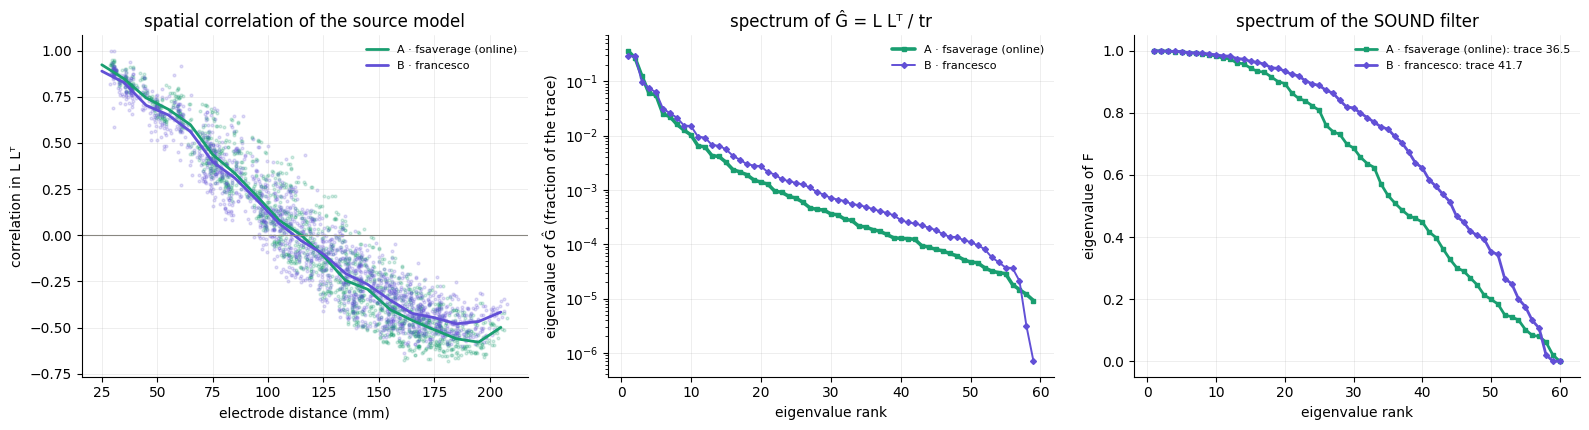

In [14]:
POS_STD = standard_positions(SESSION_CH) * 1e3
iu = np.triu_indices(len(SESSION_CH), 1)
pair_dist = np.linalg.norm(POS_STD[:, None, :] - POS_STD[None, :, :], axis=-1)[iu]
fig, axes = plt.subplots(1, 3, figsize=(16, 4.4))
bins = np.arange(0, pair_dist.max() + 10, 10)
for name in ARMS:
    st, G = SOURCE_STYLE[name], FWD[name]["G"]
    corr = (G / np.sqrt(np.outer(np.diag(G), np.diag(G))))[iu]
    axes[0].scatter(pair_dist, corr, s=4, alpha=0.18, color=st["color"], rasterized=True)
    idx = np.digitize(pair_dist, bins)
    centres = [bins[i - 1] + 5 for i in np.unique(idx)]
    axes[0].plot(centres, [np.median(corr[idx == i]) for i in np.unique(idx)], color=st["color"], lw=2,
                 label=source_label(name))
    ev = np.linalg.eigvalsh(FWD[name]["G_hat"])[::-1][:-1]      # the last one is 0 (average reference)
    axes[1].semilogy(np.arange(1, len(ev) + 1), np.clip(ev, 1e-12, None), color=st["color"],
                     lw=2.6 if name == "A" else 1.4, marker=st["marker"], ms=3, label=source_label(name))
    evF = np.sort(np.real(np.linalg.eigvals(CALIB[name]["bundle"]["sound_filter"])))[::-1]
    axes[2].plot(np.arange(1, len(evF) + 1), evF, color=st["color"], lw=2, marker=st["marker"], ms=3,
                 label=f"{source_label(name)}: trace {np.trace(CALIB[name]['bundle']['sound_filter']):.1f}")
axes[0].axhline(0, color=INK_MUTED, lw=0.8)
axes[0].set(xlabel="electrode distance (mm)", ylabel="correlation in L Lᵀ", title="spatial correlation of the source model")
axes[1].set(xlabel="eigenvalue rank", ylabel="eigenvalue of Ĝ (fraction of the trace)", title="spectrum of Ĝ = L Lᵀ / tr")
axes[2].set(xlabel="eigenvalue rank", ylabel="eigenvalue of F", title="spectrum of the SOUND filter")
for ax in axes:
    ax.legend(fontsize=8)
fig.tight_layout()
plt.show()

#### Noise estimates and filters

Top: the noise standard deviation SOUND estimated for each channel in each arm, on a shared log₁₀ colour scale
(one noisy channel would otherwise take the whole range), the ratio B / A on a log₂ scale (red: B assumes more
noise there), and both per channel. Interpolated channels are marked ×. Bottom: the filters themselves (row =
output channel, column = input channel), on one symmetric colour scale, and their difference.

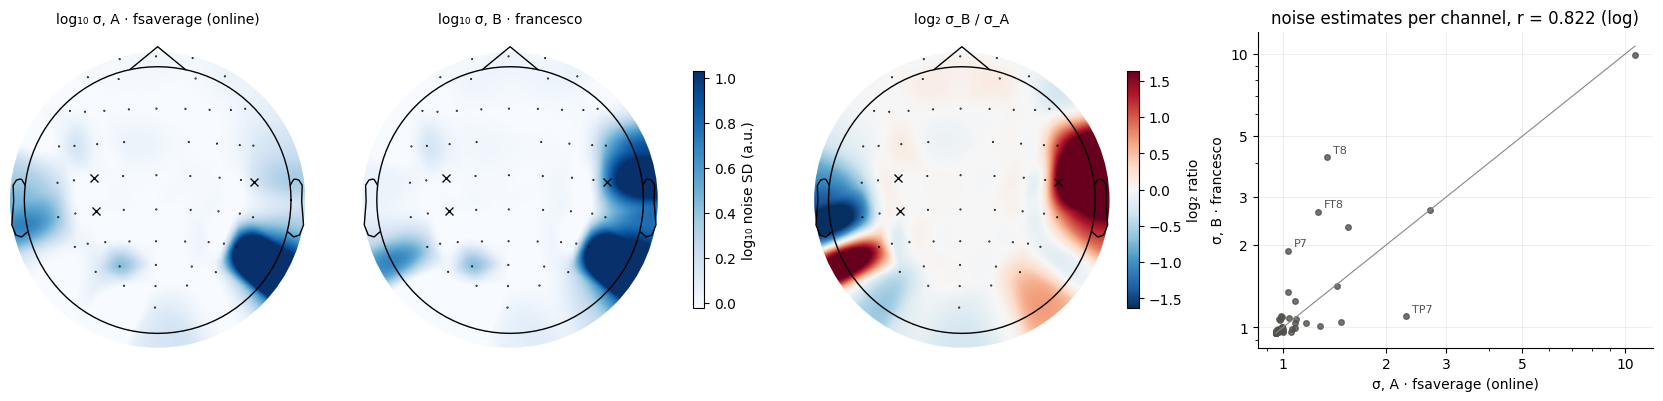

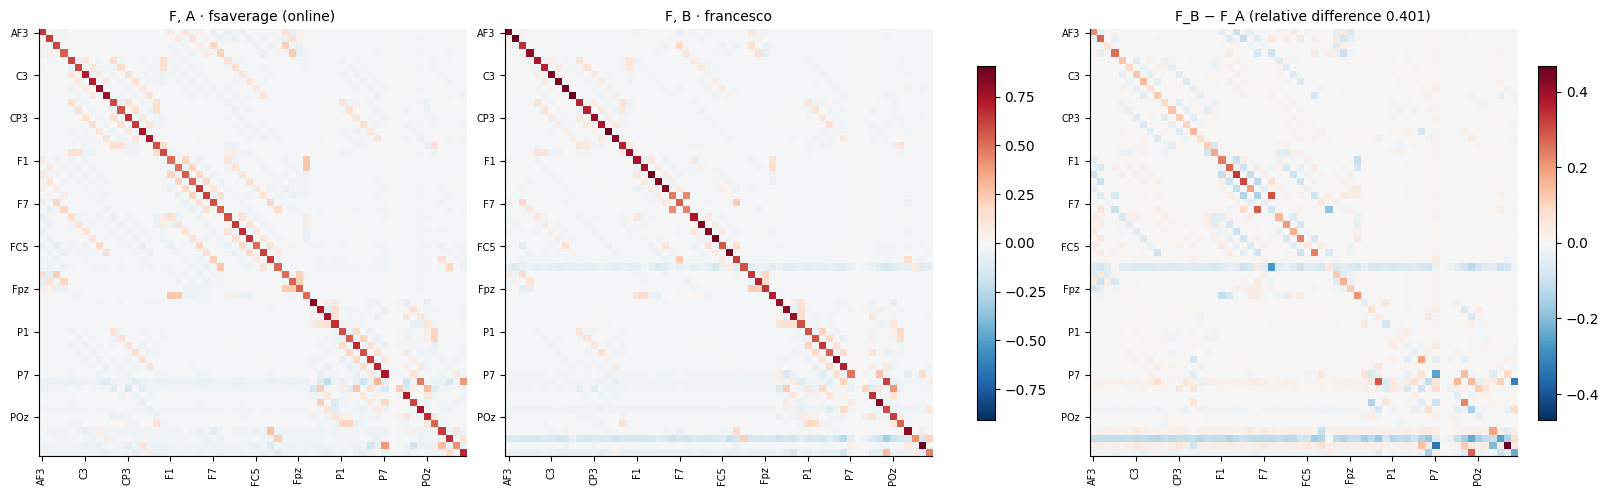

In [15]:
def topo(ax, values, title, cmap, vlim, info=None, mask=None):
    im, _ = mne.viz.plot_topomap(values, info if info is not None else ONLINE["pp"]._info_processed, axes=ax,
                                 show=False, cmap=cmap, vlim=vlim, contours=0, sensors=True, mask=mask,
                                 mask_params=dict(marker="x", markeredgecolor=INK, markersize=6))
    ax.set_title(title, fontsize=10)
    return im


bad_mask = np.isin(SESSION_CH, [str(c) for c in CALIB["A"]["bundle"]["bad_channels"]])
sig = {n: CALIB[n]["sound_m"]["sigmas"] for n in ARMS}
fig, axes = plt.subplots(1, 4, figsize=(17, 3.9), gridspec_kw=dict(width_ratios=[1, 1, 1, 1.15]),
                         layout="constrained")
lo, hi = min(v.min() for v in sig.values()), max(v.max() for v in sig.values())
for ax, n in zip(axes[:2], ARMS):
    im = topo(ax, np.log10(sig[n]), f"log₁₀ σ, {source_label(n)}", "Blues", (np.log10(lo), np.log10(hi)),
              mask=bad_mask)
fig.colorbar(im, ax=axes[:2], shrink=0.75, label="log₁₀ noise SD (a.u.)")
ratio = np.log2(sig["B"] / sig["A"])
lim = max(np.abs(ratio).max(), 1e-6)
im = topo(axes[2], ratio, "log₂ σ_B / σ_A", "RdBu_r", (-lim, lim), mask=bad_mask)
fig.colorbar(im, ax=axes[2], shrink=0.75, label="log₂ ratio")
ax = axes[3]
ax.loglog(sig["A"], sig["B"], "o", color=INK_2, ms=4, alpha=0.8)
ax.plot([lo, hi], [lo, hi], color=INK_MUTED, lw=0.8)
for i in np.argsort(-np.abs(ratio))[:4]:                         # label the channels that change most
    ax.annotate(SESSION_CH[i], (sig["A"][i], sig["B"][i]), textcoords="offset points", xytext=(4, 3), fontsize=8,
                color=INK_2)
ax.set(xlabel=f"σ, {source_label('A')}", ylabel=f"σ, {source_label('B')}",
       title=f"noise estimates per channel, r = {stats.pearsonr(np.log(sig['A']), np.log(sig['B']))[0]:.3f} (log)")
plain_log(ax, "x")
plain_log(ax, "y")
plt.show()

fig, axes = plt.subplots(1, 3, figsize=(16, 4.8), layout="constrained")
F = {n: CALIB[n]["bundle"]["sound_filter"] for n in ARMS}
lim = max(np.abs(F["A"]).max(), np.abs(F["B"]).max())
for ax, n in zip(axes[:2], ARMS):
    im = ax.imshow(F[n], cmap="RdBu_r", vmin=-lim, vmax=lim)
    ax.set_title(f"F, {source_label(n)}", fontsize=10)
fig.colorbar(im, ax=axes[:2], shrink=0.8)
dF = F["B"] - F["A"]
lim_d = max(np.abs(dF).max(), 1e-12)
im = axes[2].imshow(dF, cmap="RdBu_r", vmin=-lim_d, vmax=lim_d)
axes[2].set_title(f"F_B − F_A (relative difference {rel_diff(F['B'], F['A']):.3f})", fontsize=10)
fig.colorbar(im, ax=axes[2], shrink=0.8)
ticks = np.arange(0, len(SESSION_CH), 6)
for ax in axes:
    ax.set_xticks(ticks, [SESSION_CH[i] for i in ticks], rotation=90, fontsize=7)
    ax.set_yticks(ticks, [SESSION_CH[i] for i in ticks], fontsize=7)
    ax.grid(False)
plt.show()

#### What SOUND does to the data

Left: global field power of the calibration evoked response before SOUND (each arm's own kept trials; the input is
the same in both arms unless their kept trials differ) and after it. Middle: the share of each trial's 15–100 ms
energy SOUND removes. Right: how SOUND changes each trial's dipole amplitude at the arm's own vertex
(after / before). Boxes: median and quartiles, whiskers to 1.5 IQR; calibration trials are in-sample.

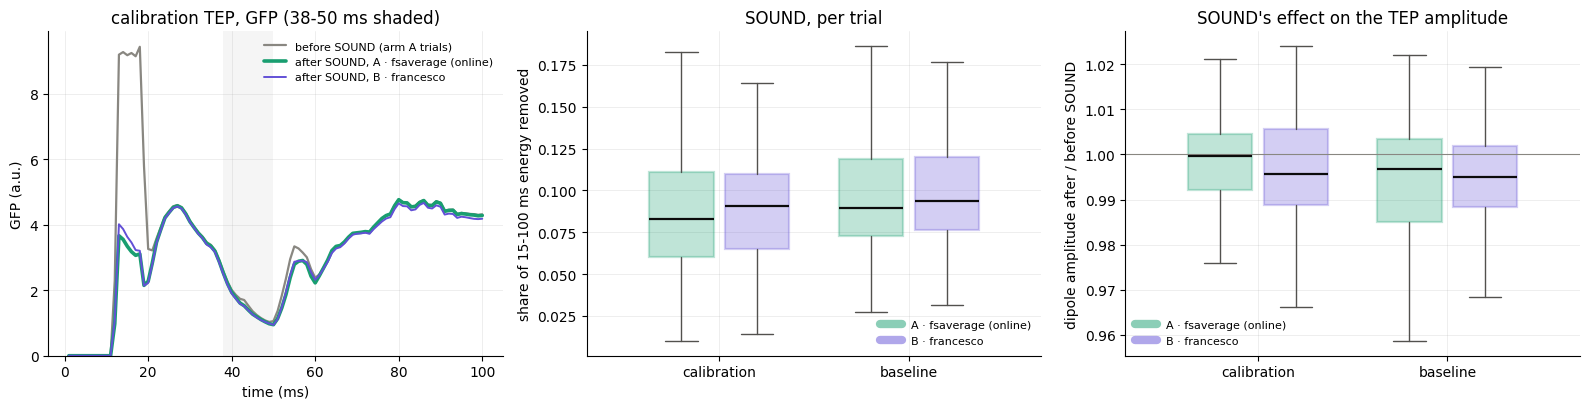

trials  energy_removed  amplitude_ratio  hf_before  hf_after
arm                    set                                                                      
A · fsaverage (online) baseline         83          0.0897           0.9968     1.2958    1.0269
                       calibration     107          0.0829           0.9997     1.2330    1.0014
B · francesco          baseline         82          0.0934           0.9951     1.2839    1.0515
                       calibration     108          0.0906           0.9957     1.2315    1.0102

In [16]:
def boxes(ax, groups, positions, colors, width=0.32):
    data = [np.asarray(g, dtype=float)[np.isfinite(np.asarray(g, dtype=float))] for g in groups]
    bp = ax.boxplot(data, positions=positions, widths=width, showfliers=False, patch_artist=True,
                    medianprops=dict(color=INK, lw=1.6), whiskerprops=dict(color=INK_2, lw=1),
                    capprops=dict(color=INK_2, lw=1))
    for patch, c in zip(bp["boxes"], colors):
        patch.set(facecolor=c, alpha=0.28, edgecolor=c, lw=1.6)
    return bp


def grouped_boxes(ax, table, value, group_col, groups, arms=("A", "B"), transform=None):
    width = 0.8 / len(arms)
    for j, name in enumerate(arms):
        vals = []
        for g in groups:
            v = table[(table.arm == name) & (table[group_col] == g)][value].to_numpy(dtype=float)
            vals.append(transform(v) if transform else v)
        pos = np.arange(len(groups)) + (j - (len(arms) - 1) / 2) * width
        boxes(ax, vals, pos, [SOURCE_STYLE[name]["color"]] * len(groups), width=width * 0.85)
        ax.plot([], [], color=SOURCE_STYLE[name]["color"], lw=6, alpha=0.5, label=source_label(name))
    ax.set_xticks(np.arange(len(groups)), groups)


fig, axes = plt.subplots(1, 3, figsize=(16, 4.2))
for name in ARMS:
    stg = STAGE_DATA[(name, "calibration")]
    st = SOURCE_STYLE[name]
    gfp = lambda k: stg[:, STAGES.index(k)].mean(axis=0).std(axis=0)
    if name == "A":
        axes[0].plot(T_MS, gfp("pre_sound"), color=INK_MUTED, lw=1.6, label="before SOUND (arm A trials)")
    axes[0].plot(T_MS, gfp("sound"), color=st["color"], lw=2.6 if name == "A" else 1.4,
                 label=f"after SOUND, {source_label(name)}")
axes[0].axvspan(DIP_TMIN * 1e3, DIP_TMAX * 1e3, color=INK_MUTED, alpha=0.08, lw=0)
axes[0].set(xlabel="time (ms)", ylabel="GFP (a.u.)", title="calibration TEP, GFP (38-50 ms shaded)", ylim=(0, None))
grouped_boxes(axes[1], STAGE_TABLE, "removed_sound", "set", list(STAGE_SETS))
axes[1].set(ylabel="share of 15-100 ms energy removed", title="SOUND, per trial")
STAGE_TABLE["ratio_sound"] = STAGE_TABLE.amp_sound / STAGE_TABLE.amp_pre_sound
grouped_boxes(axes[2], STAGE_TABLE, "ratio_sound", "set", list(STAGE_SETS))
axes[2].axhline(1, color=INK_MUTED, lw=0.8)
axes[2].set(ylabel="dipole amplitude after / before SOUND", title="SOUND's effect on the TEP amplitude")
for ax in axes:
    ax.legend(fontsize=8)
fig.tight_layout()
plt.show()

SOUND_SUMMARY = STAGE_TABLE.groupby(["arm", "set"]).agg(
    trials=("stem", "size"), energy_removed=("removed_sound", "median"), amplitude_ratio=("ratio_sound", "median"),
    hf_before=("hf_pre_sound", "median"), hf_after=("hf_sound", "median"))
display(SOUND_SUMMARY.rename(index=source_label, level=0).round(4))

### 4.3 SSP-SIR

**What SSP-SIR computes.** `ssp_sir_to_average()` runs once, on the calibration evoked response after SOUND. It
high-passes it at 100 Hz, weights it by an artifact kernel k(t) (a 50 ms moving RMS of the high-frequency power,
normalised to a maximum of 1), and takes the principal components of the weighted data; the leading ones that
together explain 99 % of its power are treated as muscle topographies and projected out (P). Because projecting
out topographies also distorts the brain signal, both the original and the suppressed data are rebuilt through
the forward model (source-informed reconstruction, SIR, keeping rank M = rank(data) − components), and every
sample is blended: x̂(t) = k(t)·SIR(Px)(t) + (1 − k(t))·SIR(x)(t). So the forward model enters twice: in the two
SIR projection matrices directly, and through SOUND's output, which sets the components and the kernel. With
G = L Lᵀ, SIR(x) is the orthogonal projection onto the M leading eigenvectors of G: the forward model decides
which M spatial patterns of the original data survive wherever k(t) < 1, including the dipole window.

Figures: the kernel of each arm with its fitted dipole window shaded; the cumulative power of the weighted data's
components with the 99 % cut; the first three removed topographies (sign aligned to arm A); and per trial, as in
4.2, the high-frequency residual and the dipole amplitude through the stages.

,A · fsaverage (online),B · francesco
components removed,15,15
rank kept for SIR (M),38,38
power explained by the removed components,0.9909,0.9902
kernel: peak (ms),35,35
kernel: mean over 38-50 ms / over the fitted window,0.690 / 0.744,0.678 / 0.758
"kernel: largest step between samples (ms, Δk)","38, -0.127","38, -0.138"
SIR(original): relative difference to A,–,0.487
SIR(suppressed): relative difference to A,–,0.493
SIR(original) subspace vs A: largest principal angle (°),–,87.0
recomputed spectrum spans the removed topographies,1.000000,1.000000


principal angles between the removed subspaces of A and B (°): 51.9, 33.9, 32.0, 26.6, 20.0, 13.9, 11.7, 10.6, 7.6, 5.9, 5.0, 3.9, 2.5, 1.9, 1.5   (relative difference of P: 0.275)


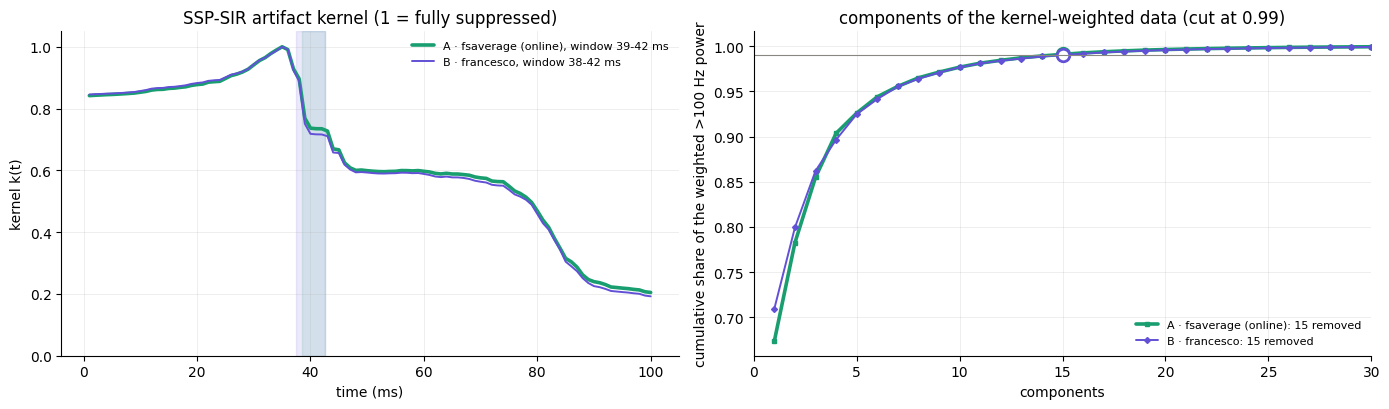

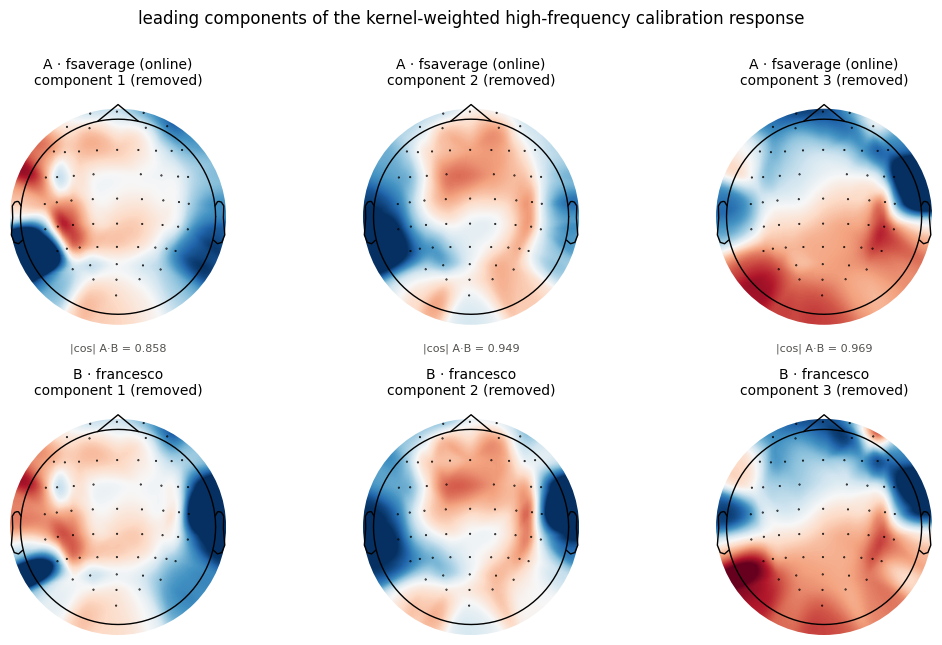

In [17]:
def sspsir_spectrum(call):
    # The singular values ssp_sir_to_average() thresholds, recomputed from its recorded input and kernel; the
    # leading vectors must span the topographies it removed (check printed below).
    data, fs, kernel = call["evoked"], call["fs"], call["kernel"]
    kw = call["kwargs"]
    b, a = signal.butter(kw.get("order", 2), kw.get("high_cutoff", 100) / (fs / 2), btype="high", analog=False)
    data_high = signal.filtfilt(b, a, data, axis=-1, padlen=None)
    U, s, _ = linalg.svd(kernel * data_high, full_matrices=False)
    n = int(call["n_pcs"])
    span = np.linalg.norm(U[:, :n].T @ call["artifact_topographies"], axis=0)     # 1 = inside the recorded subspace
    return U, s, float(span.min())


def sir_subspace(S, M):
    # SIR(original) = G (G)⁺_M with G = L Lᵀ is the orthogonal projector onto G's M leading eigenvectors
    w, V = np.linalg.eigh((S + S.T) / 2)
    return V[:, np.argsort(w)[::-1][:M]]


SSP = {}
for name in ARMS:
    call = CALIB[name]["sspsir"][0]
    U, s, span = sspsir_spectrum(call)
    SSP[name] = dict(call=call, U=U, s=s, n=int(call["n_pcs"]), M=int(call["M"]), span=span,
                     kernel=np.asarray(call["kernel"][0]), S_orig=call["sir_projmat_orig"],
                     S_suppr=call["sir_projmat_suppr"])
angles = np.degrees(linalg.subspace_angles(SSP["A"]["U"][:, :SSP["A"]["n"]], SSP["B"]["U"][:, :SSP["B"]["n"]]))
rows = {}
for name, d in SSP.items():
    win = CALIB[name]["dipole"]["index_range"]
    rows[source_label(name)] = {
        "components removed": d["n"], "rank kept for SIR (M)": d["M"],
        "power explained by the removed components": f"{np.sum(d['s'][:d['n']] ** 2) / np.sum(d['s'] ** 2):.4f}",
        "kernel: peak (ms)": f"{T_MS[np.argmax(d['kernel'])]:.0f}",
        "kernel: mean over 38-50 ms / over the fitted window":
            f"{d['kernel'][DIP_IDX].mean():.3f} / {d['kernel'][DIP_IDX.start + win[0]:DIP_IDX.start + win[1]].mean():.3f}",
        "kernel: largest step between samples (ms, Δk)":
            f"{T_MS[np.argmax(np.abs(np.diff(d['kernel'])))]:.0f}, {np.diff(d['kernel'])[np.argmax(np.abs(np.diff(d['kernel'])))]:+.3f}",
        "SIR(original): relative difference to A": "–" if name == "A" else f"{rel_diff(d['S_orig'], SSP['A']['S_orig']):.3f}",
        "SIR(suppressed): relative difference to A": "–" if name == "A" else f"{rel_diff(d['S_suppr'], SSP['A']['S_suppr']):.3f}",
        "SIR(original) subspace vs A: largest principal angle (°)": "–" if name == "A" else
            f"{np.degrees(linalg.subspace_angles(sir_subspace(d['S_orig'], d['M']), sir_subspace(SSP['A']['S_orig'], SSP['A']['M']))).max():.1f}",
        "recomputed spectrum spans the removed topographies": f"{d['span']:.6f}",
    }
SSP_TABLE = pd.DataFrame(rows)
display(SSP_TABLE)
print(f"principal angles between the removed subspaces of A and B (°): "
      + ", ".join(f"{a:.1f}" for a in angles) + f"   (relative difference of P: "
      f"{rel_diff(CALIB['B']['bundle']['sspsir_suppression_matrix_P'], CALIB['A']['bundle']['sspsir_suppression_matrix_P']):.3f})")

fig, axes = plt.subplots(1, 2, figsize=(14, 4.2))
for name, d in SSP.items():
    st, w = SOURCE_STYLE[name], CALIB[name]["dipole"]["window_ms"]
    axes[0].plot(T_MS, d["kernel"], color=st["color"], lw=2.6 if name == "A" else 1.4,
                 label=f"{source_label(name)}, window {w[0]:.0f}-{w[1]:.0f} ms")
    axes[0].axvspan(w[0] - 0.5, w[1] + 0.5, color=st["color"], alpha=0.12)
    cum = np.cumsum(d["s"] ** 2) / np.sum(d["s"] ** 2)
    axes[1].plot(np.arange(1, len(cum) + 1), cum, color=st["color"], lw=2.6 if name == "A" else 1.4,
                 marker=st["marker"], ms=3, label=f"{source_label(name)}: {d['n']} removed")
    axes[1].plot(d["n"], cum[d["n"] - 1], "o", ms=9, mfc="white", mec=st["color"], mew=2)
method = CALIB["A"]["pp"]._opts["ssp_sir_opts"]["method"]
axes[1].axhline(method[1], color=INK_MUTED, lw=0.8)
axes[0].set(xlabel="time (ms)", ylabel="kernel k(t)", title="SSP-SIR artifact kernel (1 = fully suppressed)", ylim=(0, 1.05))
axes[1].set(xlabel="components", ylabel="cumulative share of the weighted >100 Hz power",
            title=f"components of the kernel-weighted data (cut at {method[1]:g})", xlim=(0, 30))
for ax in axes:
    ax.legend(fontsize=8)
fig.tight_layout()
plt.show()

n_show = 3
fig, axes = plt.subplots(2, n_show, figsize=(3.4 * n_show + 1, 6.4))
for j in range(n_show):
    ua = SSP["A"]["U"][:, j]
    ub = SSP["B"]["U"][:, j] * np.sign(np.dot(SSP["B"]["U"][:, j], ua) or 1.0)       # sign aligned to arm A
    lim = max(np.abs(ua).max(), np.abs(ub).max())
    for i, (name, u) in enumerate((("A", ua), ("B", ub))):
        removed = "removed" if j < SSP[name]["n"] else "kept"
        im = topo(axes[i, j], u, f"{source_label(name)}\ncomponent {j + 1} ({removed})", "RdBu_r", (-lim, lim))
    axes[0, j].text(0.5, -0.08, f"|cos| A·B = {abs(np.dot(ua, ub)):.3f}", transform=axes[0, j].transAxes,
                    ha="center", va="top", fontsize=8, color=INK_2)
fig.suptitle("leading components of the kernel-weighted high-frequency calibration response", y=1.0)
fig.tight_layout()
plt.show()

#### What SSP-SIR does to the data

Left: GFP of the calibration evoked response after SOUND (SSP-SIR's input) and after SSP-SIR, per arm. Middle: the
>100 Hz RMS over 15–38 ms through the stages. Right: the dipole amplitude at each arm's vertex through the stages
(the TEP each stage would give); the final stage is what the decider logs as `tep_amplitude_raw`.

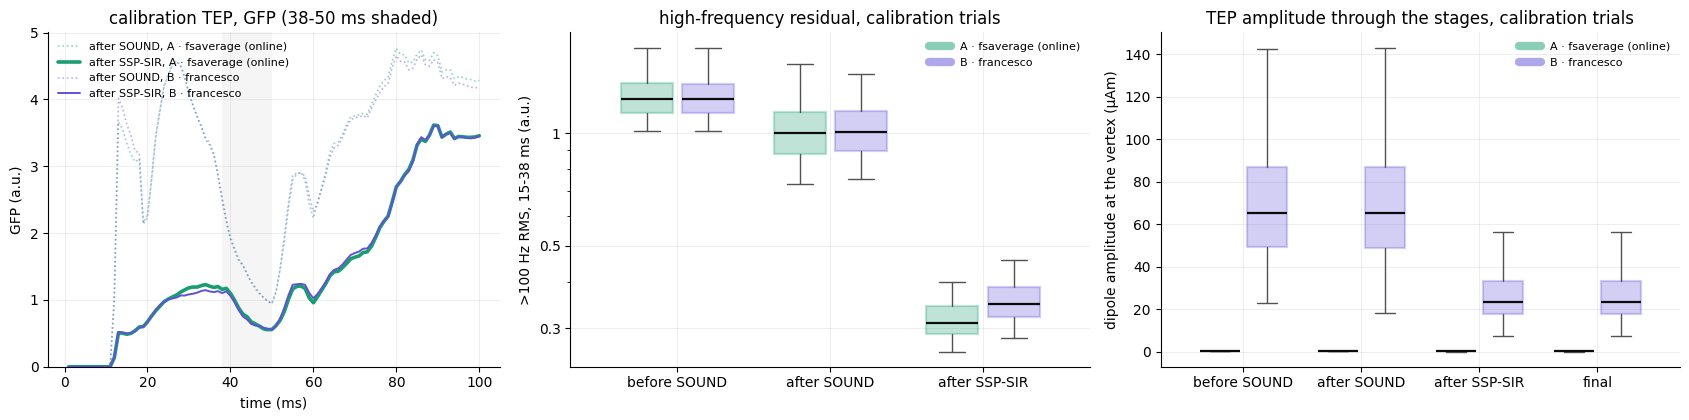

trials  energy_removed  amplitude_ratio  hf_before  hf_after  amplitude_final
arm                    set                                                                                       
A · fsaverage (online) baseline         83          0.3963           0.3360     1.0269    0.3207           0.0311
                       calibration     107          0.4089           0.3308     1.0014    0.3091           0.0298
B · francesco          baseline         82          0.3838           0.3576     1.0515    0.3591          22.9938
                       calibration     108          0.3966           0.3634     1.0102    0.3488          23.2272

In [18]:
fig, axes = plt.subplots(1, 3, figsize=(17, 4.3), gridspec_kw=dict(width_ratios=[1, 1.15, 1.15]))
for name in ARMS:
    stg, st = STAGE_DATA[(name, "calibration")], SOURCE_STYLE[name]
    gfp = lambda k: stg[:, STAGES.index(k)].mean(axis=0).std(axis=0)
    axes[0].plot(T_MS, gfp("sound"), color=st["color"], lw=1.2, alpha=0.45, ls=":",
                 label=f"after SOUND, {source_label(name)}")
    axes[0].plot(T_MS, gfp("sspsir"), color=st["color"], lw=2.6 if name == "A" else 1.4,
                 label=f"after SSP-SIR, {source_label(name)}")
axes[0].axvspan(DIP_TMIN * 1e3, DIP_TMAX * 1e3, color=INK_MUTED, alpha=0.08, lw=0)
axes[0].set(xlabel="time (ms)", ylabel="GFP (a.u.)", title="calibration TEP, GFP (38-50 ms shaded)", ylim=(0, None))
long = STAGE_TABLE.melt(id_vars=["arm", "set", "stem"], value_vars=[f"hf_{k}" for k in STAGES[:3]],
                        var_name="stage", value_name="hf")
long["stage"] = long.stage.str[3:].map(STAGE_LABELS)
grouped_boxes(axes[1], long[long.set == "calibration"], "hf", "stage", [STAGE_LABELS[k] for k in STAGES[:3]])
axes[1].set(ylabel=">100 Hz RMS, 15-38 ms (a.u.)", title="high-frequency residual, calibration trials", yscale="log")
plain_log(axes[1])
long = STAGE_TABLE.melt(id_vars=["arm", "set", "stem"], value_vars=[f"amp_{k}" for k in STAGES],
                        var_name="stage", value_name="amp")
long["stage"] = long.stage.str[4:].map(STAGE_LABELS)
grouped_boxes(axes[2], long[long.set == "calibration"], "amp", "stage", [STAGE_LABELS[k] for k in STAGES])
axes[2].set(ylabel="dipole amplitude at the vertex (µAm)", title="TEP amplitude through the stages, calibration trials")
for ax in axes:
    ax.legend(fontsize=8)
fig.tight_layout()
plt.show()

STAGE_TABLE["ratio_sspsir"] = STAGE_TABLE.amp_sspsir / STAGE_TABLE.amp_sound
SSP_SUMMARY = STAGE_TABLE.groupby(["arm", "set"]).agg(
    trials=("stem", "size"), energy_removed=("removed_sspsir", "median"), amplitude_ratio=("ratio_sspsir", "median"),
    hf_before=("hf_sound", "median"), hf_after=("hf_sspsir", "median"),
    amplitude_final=("amp_final", "median"))
display(SSP_SUMMARY.rename(index=source_label, level=0).round(4))
STAGE_TABLE.to_csv(RESULTS_ROOT / "stage_replay_trials.csv", index=False)

### 4.4 Dipoles

The calibration dipole of each source, in head coordinates, over the source points of both forward models (A dark
grey, B light grey; the same points when B uses the fsaverage source space). The arrow is the orientation from
`determine_optimal_ori_and_pos()`. Top row: the whole source space. Bottom row: a cube of ±25 mm around the
dipoles (larger if they are further apart), with only the source points inside it, so that a few millimetres
between the dipoles become visible. The table gives the fitted time windows, the distances and angles between the
dipoles, and how much their windows overlap. Below it, for each arm, the calibration TEP's topography over its
fitted window next to the topography its dipole predicts (one shared colour scale per arm).

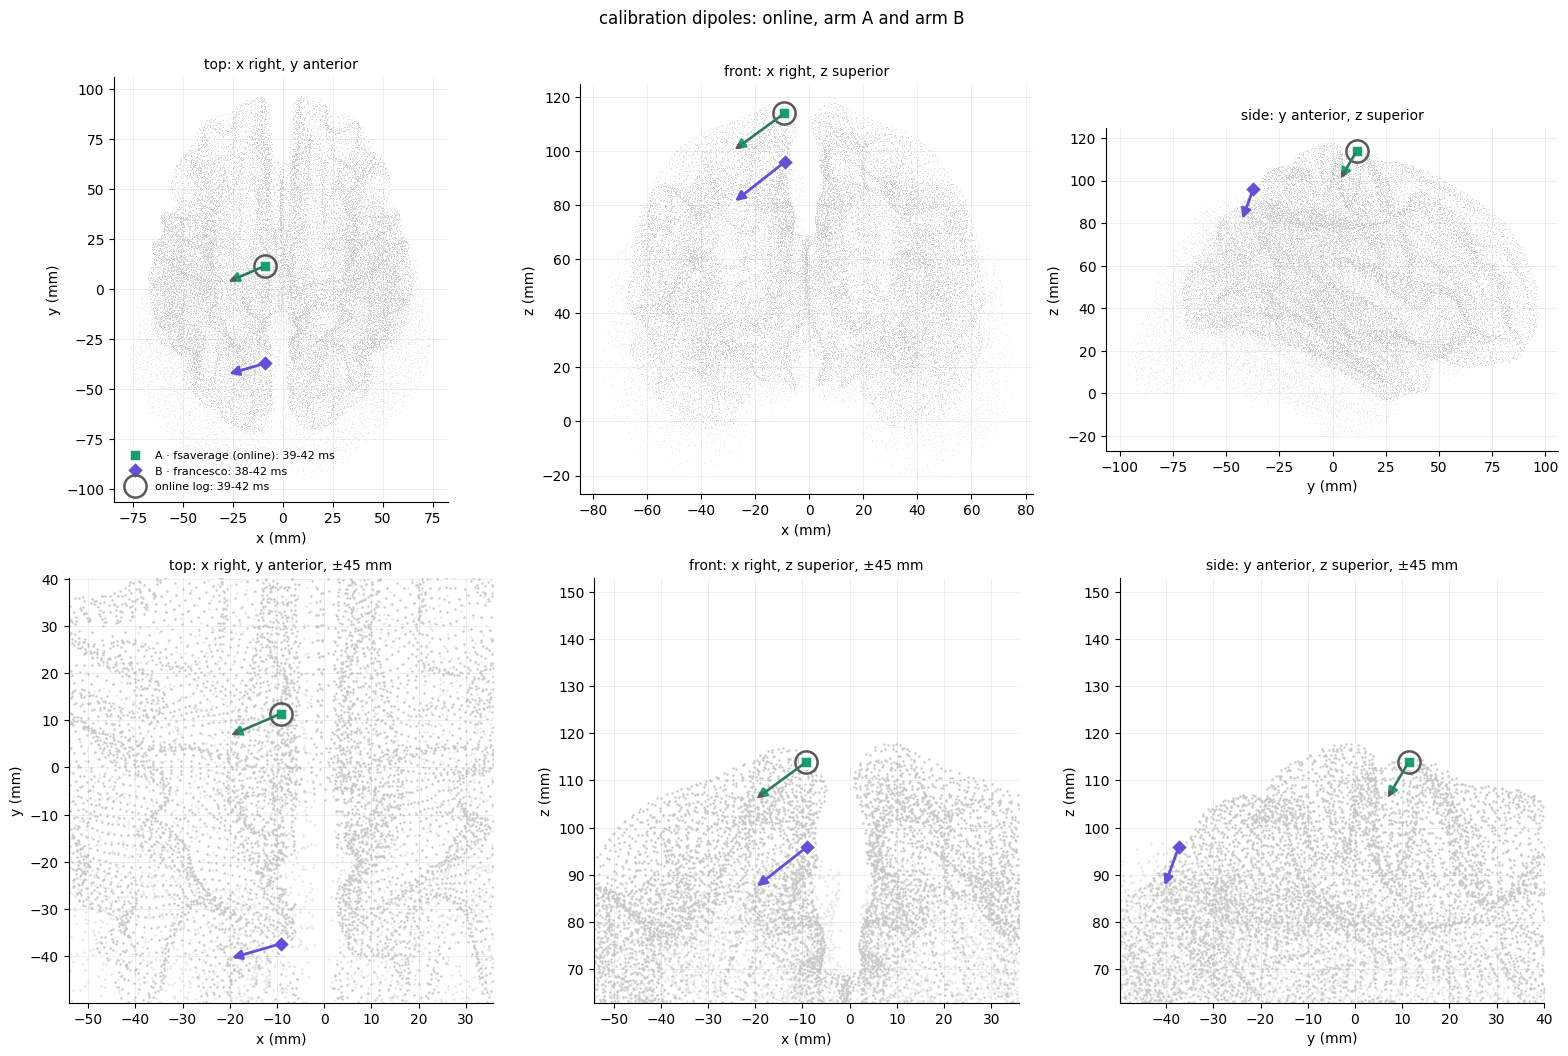

,vertex,"position x, y, z (mm)",orientation,window (samples),window (ms),samples,evoked R²,evoked amplitude (µAm)
source,,,,,,,,
online log,4641,"-9.2, 11.4, 113.9","-0.76, -0.33, -0.56",1-5,39-42,4,0.607,0.0150
A · fsaverage (online),4641,"-9.2, 11.4, 113.9","-0.76, -0.33, -0.56",1-5,39-42,4,0.607,0.0150
B · francesco,1000,"-9.1, -37.3, 95.9","-0.77, -0.22, -0.60",0-5,38-42,5,0.634,11.9471


,distance (mm),orientation angle (°),windows (ms),window start shift (ms),overlap (samples)
comparison,,,,,
A vs online,0.0,0.0,39-42 vs 39-42,0.0,4
B vs online,51.9,6.7,38-42 vs 39-42,-1.0,4
B vs A,51.9,6.7,38-42 vs 39-42,-1.0,4


online log              time window 39-42 ms (samples 1-4 of the 38-50 ms crop)
A · fsaverage (online)  time window 39-42 ms (samples 1-4 of the 38-50 ms crop)
B · francesco           time window 38-42 ms (samples 0-4 of the 38-50 ms crop)


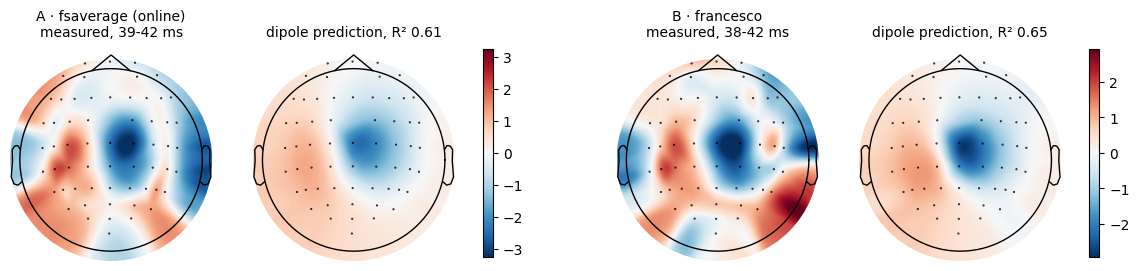

In [19]:
VIEWS = [(0, 1, "top: x right, y anterior"), (0, 2, "front: x right, z superior"), (1, 2, "side: y anterior, z superior")]
DIPOLES = {src: CAL_SRC[src]["dipole"] for src in SOURCES}
ZOOM_MM = 25


def draw_source_space(ax, h, v, centre=None, half=ZOOM_MM):
    # Source points of both forwards; with a centre, only those inside the cube of ±half mm around it.
    same_space = (FWD["A"]["rr_mm"].shape == FWD["B"]["rr_mm"].shape
                  and np.allclose(FWD["A"]["rr_mm"], FWD["B"]["rr_mm"]))
    for key, shade in (("B", "0.9"), ("A", "0.78")):
        if key == "B" and same_space:
            continue
        rr = FWD[key]["rr_mm"]
        if centre is not None:
            rr = rr[np.all(np.abs(rr - centre) <= half, axis=1)]
        ax.scatter(rr[:, h], rr[:, v], s=0.3 if centre is None else 3, color=shade, linewidths=0, rasterized=True)
    if centre is not None:
        ax.set_xlim(centre[h] - half, centre[h] + half)
        ax.set_ylim(centre[v] - half, centre[v] + half)


def draw_dipoles(axes, names, arrow_mm=25, centre=None, half=ZOOM_MM):
    for ax, (h, v, title) in zip(axes, VIEWS):
        draw_source_space(ax, h, v, centre, half)
        for name in names:
            d, st = DIPOLES[name], SOURCE_STYLE[name]
            p, o = d["position_mm"], d["orientation"] * arrow_mm
            ring = name == "online"                              # online drawn as a ring with a thin arrow
            ax.annotate("", xy=(p[h] + o[h], p[v] + o[v]), xytext=(p[h], p[v]),
                        arrowprops=dict(arrowstyle="-|>", color=st["color"], lw=0.9 if ring else 2,
                                        mutation_scale=9 if ring else 14))
            ax.plot(p[h], p[v], st["marker"], color=st["color"], mfc="none" if ring else st["mfc"],
                    ms=16 if ring else 9, mew=1.8, mec="white" if not ring else st["color"],
                    label=f"{source_label(name)}: {d['window_ms'][0]:.0f}-{d['window_ms'][1]:.0f} ms")
        ax.set_xlabel(f"{'xyz'[h]} (mm)")
        ax.set_ylabel(f"{'xyz'[v]} (mm)")
        ax.set_title(title + (f", ±{half:.0f} mm" if centre is not None else ""), fontsize=10)
        ax.set_aspect("equal")


DIPOLE_CENTRE = np.mean([DIPOLES[s]["position_mm"] for s in SOURCES], axis=0)
DIPOLE_HALF = max(ZOOM_MM, float(np.ceil(max(np.linalg.norm(DIPOLES[s]["position_mm"] - DIPOLE_CENTRE)
                                              for s in SOURCES) + 10)))
fig, axes = plt.subplots(2, 3, figsize=(16, 10.5))
draw_dipoles(axes[0], ["A", "B", "online"])
draw_dipoles(axes[1], ["A", "B", "online"], arrow_mm=8 * DIPOLE_HALF / ZOOM_MM, centre=DIPOLE_CENTRE, half=DIPOLE_HALF)
axes[0, 0].legend(fontsize=8, loc="lower left")
fig.suptitle("calibration dipoles: online, arm A and arm B", y=1.0)
fig.tight_layout()
plt.show()


def angle_deg(a, b):
    return float(np.degrees(np.arccos(np.clip(np.dot(a, b) / (np.linalg.norm(a) * np.linalg.norm(b)), -1, 1))))


rows = []
for src in SOURCES:
    d = DIPOLES[src]
    rows.append({"source": source_label(src), "vertex": d["vertex"],
                 "position x, y, z (mm)": ", ".join(f"{v:.1f}" for v in d["position_mm"]),
                 "orientation": ", ".join(f"{v:+.2f}" for v in d["orientation"]),
                 "window (samples)": f"{d['index_range'][0]}-{d['index_range'][1]}",
                 "window (ms)": f"{d['window_ms'][0]:.0f}-{d['window_ms'][1]:.0f}", "samples": d["samples"],
                 "evoked R²": round(d["r2"], 3), "evoked amplitude (µAm)": round(d["evoked_amplitude"], 4)})
DIPOLE_TABLE = pd.DataFrame(rows).set_index("source")
display(DIPOLE_TABLE)
rows = []
for a, b in (("A", "online"), ("B", "online"), ("B", "A")):
    da, db = DIPOLES[a], DIPOLES[b]
    (wa0, wa1), (wb0, wb1) = da["window_ms"], db["window_ms"]
    rows.append({"comparison": f"{a} vs {b}", "distance (mm)": round(float(np.linalg.norm(da["position_mm"] - db["position_mm"])), 1),
                 "orientation angle (°)": round(angle_deg(da["orientation"], db["orientation"]), 1),
                 "windows (ms)": f"{wa0:.0f}-{wa1:.0f} vs {wb0:.0f}-{wb1:.0f}",
                 "window start shift (ms)": round(wa0 - wb0, 1),
                 "overlap (samples)": max(0, min(da["index_range"][1], db["index_range"][1])
                                          - max(da["index_range"][0], db["index_range"][0]))})
DIPOLE_DIFF = pd.DataFrame(rows).set_index("comparison")
display(DIPOLE_DIFF)
for src in SOURCES:
    d = DIPOLES[src]
    print(f"{source_label(src):{LABEL_W}s}  time window {d['window_ms'][0]:.0f}-{d['window_ms'][1]:.0f} ms "
          f"(samples {d['index_range'][0]}-{d['index_range'][1] - 1} of the 38-50 ms crop)")

fig, axes = plt.subplots(1, 4, figsize=(15, 3.6))
for k, name in enumerate(ARMS):
    d = DIPOLES[name]
    s, e = d["index_range"]
    measured = d["evoked"][:, s:e].mean(axis=1)
    q = np.linalg.pinv(d["Lp"]) @ measured
    predicted = d["Lp"] @ q
    lim = max(np.abs(measured).max(), np.abs(predicted).max())
    r2 = 1 - np.sum((measured - predicted) ** 2) / np.sum((measured - measured.mean()) ** 2)
    im = topo(axes[2 * k], measured, f"{source_label(name)}\nmeasured, {d['window_ms'][0]:.0f}-{d['window_ms'][1]:.0f} ms",
              "RdBu_r", (-lim, lim))
    topo(axes[2 * k + 1], predicted, f"dipole prediction, R² {r2:.2f}", "RdBu_r", (-lim, lim))
    fig.colorbar(im, ax=axes[2 * k:2 * k + 2], shrink=0.75)
plt.show()

## 5 · Dipole fit, replayed 200 times

`DipoleFitter.calibrate()` is deterministic, so rerunning it on the same trials gives the same dipole. To see how
stable each arm's fit is, it is replayed on `N_BOOTSTRAP` bootstrap resamples of that arm's calibration trials:
each replay draws as many trials as the arm kept, with replacement, from the same dipole-window buffers
`Preprocessor.calibrate()` handed to the fitter in section 3.2, and runs the unmodified `DipoleFitter.calibrate()`
on them (vertex scan, window search, position and orientation). Only the dipole stage is resampled: SOUND,
SSP-SIR and the gates stay as calibrated, so the spread is that of the fit itself. Both arms draw from the same
random sequence (`BOOTSTRAP_SEED`): when they kept the same trials, replay *i* uses the same resample in both.

**How the window is chosen.** `determine_optimal_index_range()` scores every window of 3–6 samples inside
38–50 ms by `rank(size)^1.5 / (rank(position spread) + rank(orientation spread) + rank(minimum amplitude))`, the
ranks taken over all candidate windows, and keeps the best one. The score table of every call is recorded (by
handing the module a pandas stand-in that keeps each DataFrame it builds; nothing is recomputed), so the first table
below shows how close the runners-up of each arm's full-sample window were, and the replays record where the
full-sample window ranked. The window is a discrete argmax: when two windows score almost the same, resampling
flips between them, and the bootstrap distribution of the window need not be centred on the full-sample choice.

Each replay gives a position, an orientation and a window. The spread is read against the arm's own full-sample
fit (section 4.4): distance and angle to it, how often the vertex and the window come out the same, and which
windows occur. A refit on all trials once (no resampling) checks first that the replay reproduces that fit. Last,
the B − A difference of section 4.4 is set against arm A's spread: a shift smaller than most of the shifts A shows
when only its trials are resampled cannot be told apart from trial noise.

In [20]:
class _RecordFrames:
    # Stands in for pandas inside dipole_fitter during a call and keeps every DataFrame it builds; everything else
    # is passed through to pandas.
    def __init__(self, real):
        self._real, self.frames = real, []

    def __getattr__(self, name):
        return getattr(self._real, name)

    def DataFrame(self, *args, **kwargs):
        df = self._real.DataFrame(*args, **kwargs)
        self.frames.append(df)
        return df


@contextlib.contextmanager
def recording_window_scores():
    rec = _RecordFrames(dipole_module.pd)
    dipole_module.pd = rec
    try:
        yield rec
    finally:
        dipole_module.pd = rec._real


def to_ms(i):
    return (DIP_TMIN + i / PROC_SFREQ) * 1e3


def window_name(s, e):
    return f"{to_ms(s):.0f}-{to_ms(e - 1):.0f} ms"


def refit(fitter, buffers):
    # The unmodified DipoleFitter.calibrate() on these buffers, with the window score table it ranked
    with contextlib.redirect_stdout(io.StringIO()), recording_window_scores() as rec:
        amps = fitter.calibrate(buffers)
    scores = rec.frames[-1].sort_values("final_score", ascending=False).reset_index(drop=True)
    return np.asarray(amps), scores


def window_rank(scores, index_range):
    hit = scores.index[(scores.start == index_range[0]) & (scores.end == index_range[1])]
    return int(hit[0]) + 1 if len(hit) else np.nan


# The full-sample refit: must reproduce section 3.2, and its score table shows the runners-up
FULL_SCORES, rows = {}, []
for name in ARMS:
    cal, full = CALIB[name], DIPOLES[name]
    fitter = DipoleFitter(ARMS[name]["forward"])
    amps, scores = refit(fitter, cal["dipole_buffers"])
    info = fitter.fitting_info
    rows.append({"arm": source_label(name), "same vertex": int(info["position_index"]) == full["vertex"],
                 "same window": tuple(int(v) for v in info["index_range"]) == full["index_range"],
                 "orientation max |Δ|": float(np.max(np.abs(np.asarray(info["orientation"]) - full["orientation"]))),
                 "calibration amplitudes max |Δ|": float(np.max(np.abs(amps - cal["amplitudes"])))})
    FULL_SCORES[name] = scores
REFIT_CHECK = pd.DataFrame(rows).set_index("arm")
display(REFIT_CHECK)
if not (REFIT_CHECK["same vertex"].all() and REFIT_CHECK["same window"].all()):
    print("WARNING: the refit on all trials does not reproduce the calibration dipole; the replays below are not "
          "comparable with section 4.4")

top = []
for name, scores in FULL_SCORES.items():
    t = scores.head(6).copy()
    t.insert(0, "arm", source_label(name))
    t.insert(1, "rank", np.arange(1, len(t) + 1))
    t.insert(2, "window", [window_name(s, e) for s, e in zip(t.start, t.end)])
    t["score / best"] = t.final_score / t.final_score.iloc[0]
    t["pos_stability"] = t.pos_stability * 1e3                   # source_rr is in m
    top.append(t)
WINDOW_CANDIDATES = pd.concat(top)[["arm", "rank", "window", "size", "min_amplitude", "pos_stability",
                                    "ori_stability", "min_amplitude_rank", "pos_rank", "ori_rank", "size_rank",
                                    "final_score", "score / best"]]
WINDOW_CANDIDATES = WINDOW_CANDIDATES.rename(columns={
    "min_amplitude": "min amplitude (µAm)", "pos_stability": "position spread (mm)", "ori_stability": "orientation spread (°)",
    "min_amplitude_rank": "rank: amplitude", "pos_rank": "rank: position", "ori_rank": "rank: orientation",
    "size_rank": "rank: size", "final_score": "score"}).set_index(["arm", "rank"])
print("the six best-scoring windows of each arm's full-sample fit (rank 1 is the window it chose)")
display(WINDOW_CANDIDATES.round(4))
WINDOW_CANDIDATES.to_csv(RESULTS_ROOT / "dipole_window_candidates.csv")

,same vertex,same window,orientation max |Δ|,calibration amplitudes max |Δ|
arm,,,,
A · fsaverage (online),True,True,0.0,0.0
B · francesco,True,True,0.0,0.0


the six best-scoring windows of each arm's full-sample fit (rank 1 is the window it chose)


window  size  min amplitude (µAm)  position spread (mm)  orientation spread (°)  rank: amplitude  rank: position  rank: orientation  rank: size    score  score / best
arm                    rank                                                                                                                                                                          
A · fsaverage (online) 1     39-42 ms     4               0.0129                6.3537                  4.4064              5.0             4.0                3.0        16.5   5.5853        1.0000
                       2     39-44 ms     6               0.0104                7.8685                  6.4418             12.5            15.0               11.0        34.5   5.2634        0.9424
                       3     38-43 ms     6               0.0114                9.6340                  6.1466              8.5            25.0                9.0        34.5   4.7680        0.8537
                       4     39-43 ms     5               0.0114                8.1328                  5.3358              8.5            17.0                6.0        26.0   4.2087        0.7535
                       5     40-45 ms     6               0.0090                8.4101                  7.0083             16.5            20.0               14.0        34.5   4.0127        0.7184
                       6     38-42 ms     5               0.0129                9.4688                  6.0022              5.0            24.0                8.0        26.0   3.5831        0.6415
B · francesco          1     38-42 ms     5               9.4688                1.4586                  3.9387              5.0             2.0                5.0        26.0  11.0479        1.0000
                       2     38-43 ms     6               9.0210                5.0779                  5.7506              8.5             7.0                8.0        34.5   8.6230        0.7805
                       3     39-42 ms     4               9.4688                1.7093                  3.4532              5.0             3.5                2.0        16.5   6.3832        0.5778
                       4     38-41 ms     4              11.3801                1.7093                  3.9481              2.5             3.5                6.0        16.5   5.5853        0.5056
                       5     39-44 ms     6               7.6499               10.9031                  6.9786             12.5            12.0               12.0        34.5   5.5518        0.5025
                       6     39-43 ms     5               9.0210                5.7925                  5.8464              8.5             8.0               10.0        26.0   5.0028        0.4528

In [21]:
BOOT_ROWS, BOOT_TIME = [], {}
for name in ARMS:
    cal, full = CALIB[name], DIPOLES[name]
    buffers = cal["dipole_buffers"]
    fitter = DipoleFitter(ARMS[name]["forward"])             # its own fitter: the arm's calibrated one is untouched
    rr = fitter._forward["source_rr"] * 1e3
    rng, n = np.random.default_rng(BOOTSTRAP_SEED), len(buffers)
    t0 = time.perf_counter()
    for b in range(N_BOOTSTRAP):
        idx = rng.integers(0, n, n)
        amps, scores = refit(fitter, buffers[idx])
        info = fitter.fitting_info
        pos, (s, e) = int(info["position_index"]), tuple(int(v) for v in info["index_range"])
        ori = np.asarray(info["orientation"], dtype=float)
        BOOT_ROWS.append({"arm": name, "replay": b, "unique_trials": len(np.unique(idx)), "vertex": pos,
                          "x": rr[pos, 0], "y": rr[pos, 1], "z": rr[pos, 2], "ox": ori[0], "oy": ori[1], "oz": ori[2],
                          "start": s, "end": e, "start_ms": to_ms(s), "end_ms": to_ms(e - 1),
                          "median_amplitude": float(np.median(amps)),
                          "distance_mm": float(np.linalg.norm(rr[pos] - full["position_mm"])),
                          "angle_deg": angle_deg(ori, full["orientation"]),
                          "same_vertex": pos == full["vertex"], "same_window": (s, e) == full["index_range"],
                          "full_window_rank": window_rank(scores, full["index_range"]),
                          "score_margin": float(1 - scores.final_score.iloc[1] / scores.final_score.iloc[0])})
    BOOT_TIME[name] = (time.perf_counter() - t0) / N_BOOTSTRAP
    print(f"{source_label(name):{LABEL_W}s}: {N_BOOTSTRAP} refits of {n} trials, {BOOT_TIME[name]:.2f} s each")
BOOT = pd.DataFrame(BOOT_ROWS)
BOOT["window"] = [window_name(s, e) for s, e in zip(BOOT.start, BOOT.end)]
BOOT.to_csv(RESULTS_ROOT / "dipole_bootstrap.csv", index=False)

rows = {}
for name in ARMS:
    d, full = BOOT[BOOT.arm == name], DIPOLES[name]
    centre = d[["x", "y", "z"]].mean().to_numpy()
    modal = d.window.value_counts()
    rows[source_label(name)] = {
        "full-sample fit: window": f"{full['window_ms'][0]:.0f}-{full['window_ms'][1]:.0f} ms",
        "full-sample fit: score margin over the runner-up (%)":
            f"{100 * (1 - FULL_SCORES[name].final_score.iloc[1] / FULL_SCORES[name].final_score.iloc[0]):.1f}",
        "same vertex as the full fit (%)": f"{100 * d.same_vertex.mean():.0f}",
        "distinct vertices": d.vertex.nunique(),
        "distance to the full fit, median / 95th pct (mm)": f"{d.distance_mm.median():.1f} / {d.distance_mm.quantile(0.95):.1f}",
        "SD of position x / y / z (mm)": " / ".join(f"{d[c].std():.1f}" for c in "xyz"),
        "radius around the bootstrap mean holding 95 % (mm)":
            f"{np.quantile(np.linalg.norm(d[['x', 'y', 'z']].to_numpy() - centre, axis=1), 0.95):.1f}",
        "orientation angle to the full fit, median / 95th pct (°)": f"{d.angle_deg.median():.1f} / {d.angle_deg.quantile(0.95):.1f}",
        "same window as the full fit (%)": f"{100 * d.same_window.mean():.0f}",
        "rank of the full-sample window in the replays, median [range]":
            f"{d.full_window_rank.median():.0f} [{d.full_window_rank.min():.0f}, {d.full_window_rank.max():.0f}]",
        "most frequent window (%)": f"{modal.index[0]} ({100 * modal.iloc[0] / len(d):.0f})",
        "distinct windows": len(modal),
        "window start, median [range] (ms)": f"{d.start_ms.median():.0f} [{d.start_ms.min():.0f}, {d.start_ms.max():.0f}]",
        "window length, median [range] (samples)":
            f"{(d.end - d.start).median():.0f} [{(d.end - d.start).min()}, {(d.end - d.start).max()}]",
        "replay score margin over the runner-up, median (%)": f"{100 * d.score_margin.median():.1f}",
        "seconds per refit": f"{BOOT_TIME[name]:.2f}",
    }
BOOT_SUMMARY = pd.DataFrame(rows)
display(BOOT_SUMMARY)
BOOT_SUMMARY.to_csv(RESULTS_ROOT / "dipole_bootstrap_summary.csv")

# The B - A difference of section 4.4 against arm A's own resampling spread
a, dA, dB = BOOT[BOOT.arm == "A"], DIPOLES["A"], DIPOLES["B"]
d_ba = float(np.linalg.norm(dB["position_mm"] - dA["position_mm"]))
ang_ba = angle_deg(dB["orientation"], dA["orientation"])
win_b = window_name(*dB["index_range"])
SHIFT_VS_BOOT = pd.Series({
    "B vs A: distance (mm)": f"{d_ba:.1f}",
    "  larger than this share of A's resampling distances (%)": f"{100 * (a.distance_mm < d_ba).mean():.1f}",
    "B vs A: orientation angle (°)": f"{ang_ba:.1f}",
    "  larger than this share of A's resampling angles (%)": f"{100 * (a.angle_deg < ang_ba).mean():.1f}",
    "B's window": win_b,
    "  chosen in this share of A's replays (%)": f"{100 * (a.window == win_b).mean():.1f}",
}, name="arm B against arm A's resampling spread")
display(SHIFT_VS_BOOT.to_frame())
SHIFT_VS_BOOT.to_csv(RESULTS_ROOT / "dipole_B_vs_A_resampling.csv")

A · fsaverage (online): 200 refits of 107 trials, 0.85 s each
B · francesco         : 200 refits of 108 trials, 0.63 s each


,A · fsaverage (online),B · francesco
full-sample fit: window,39-42 ms,38-42 ms
full-sample fit: score margin over the runner-up (%),5.8,21.9
same vertex as the full fit (%),2,24
distinct vertices,53,39
"distance to the full fit, median / 95th pct (mm)",12.9 / 21.6,4.6 / 19.2
SD of position x / y / z (mm),9.8 / 5.3 / 1.8,9.5 / 7.0 / 7.0
radius around the bootstrap mean holding 95 % (mm),15.7,18.3
"orientation angle to the full fit, median / 95th pct (°)",10.8 / 20.2,11.2 / 27.2
same window as the full fit (%),6,34
"rank of the full-sample window in the replays, median [range]","5 [1, 22]","2 [1, 11]"


,arm B against arm A's resampling spread
B vs A: distance (mm),51.9
larger than this share of A's resampling distances (%),100.0
B vs A: orientation angle (°),6.7
larger than this share of A's resampling angles (%),19.5
B's window,38-42 ms
chosen in this share of A's replays (%),26.5


### 5.1 Spread in position and time window

Positions: every bootstrap dipole (small dots) with the arm's full-sample fit (large marker) and the online dipole
(ring), in the three views of section 4.4; top row the whole source space, bottom row a cube of ±30 mm around the
full-sample fits (replays outside it are counted in the titles). Then the distance and orientation angle of each
replay to its arm's full-sample fit. Last, the fitted window of every replay as a bar from its first to its last
sample, sorted by start and length (the arm's full-sample window shaded), and how often each window occurs.

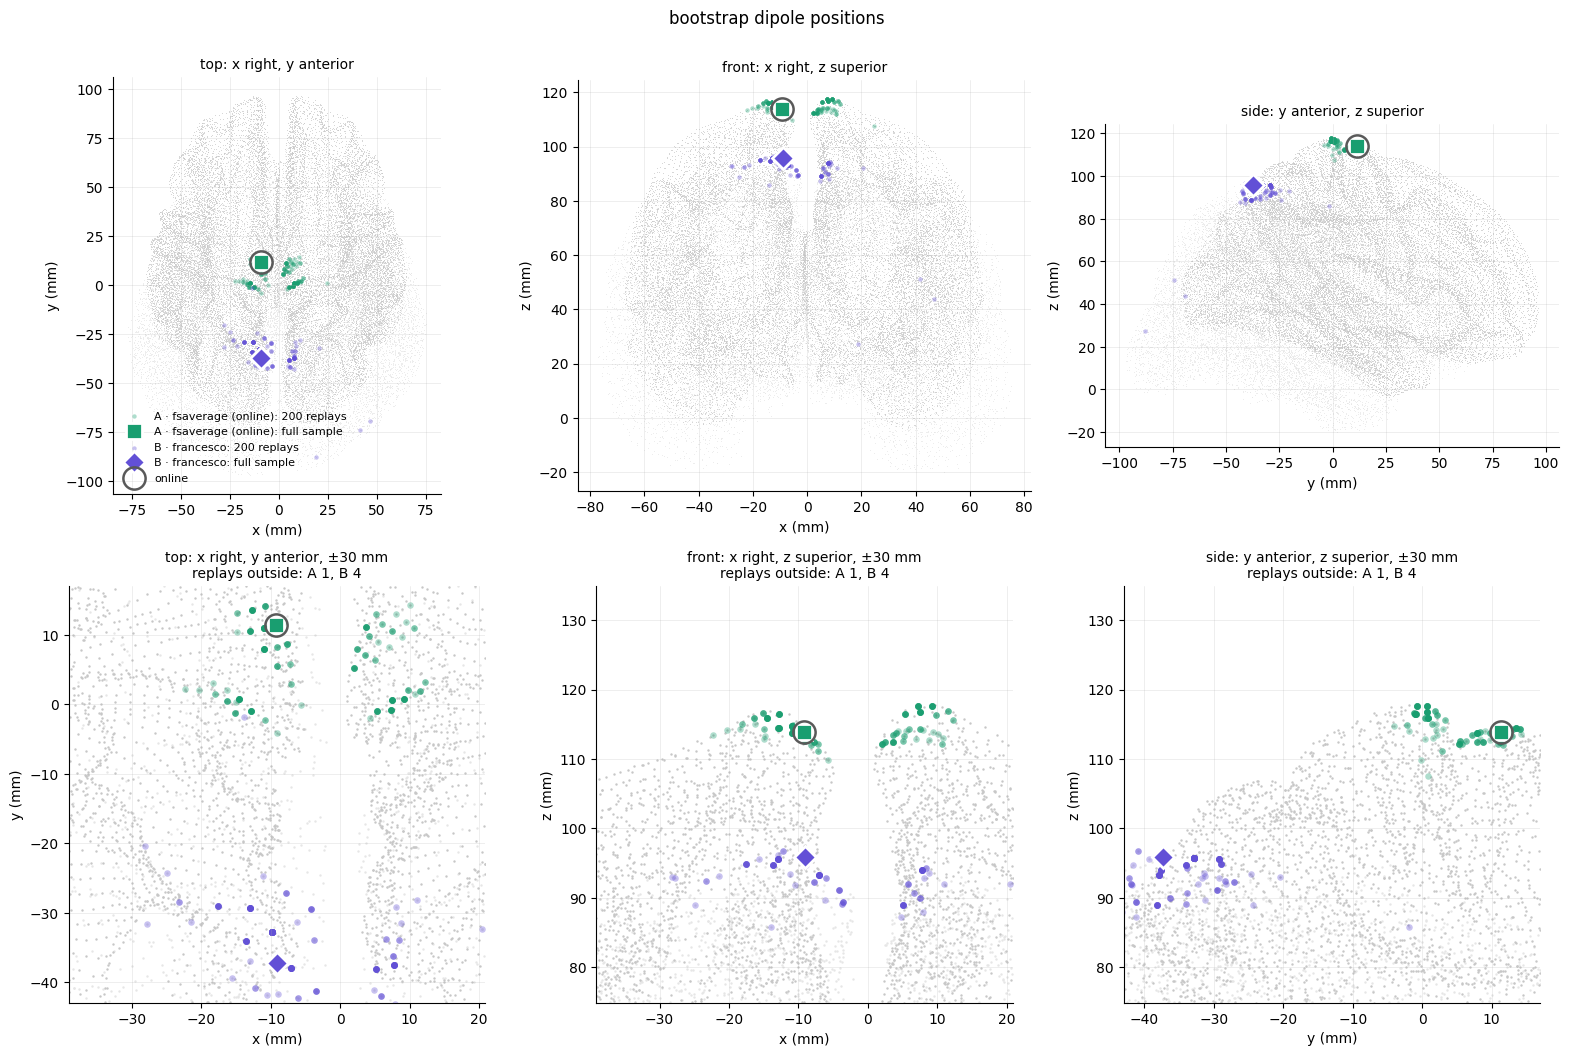

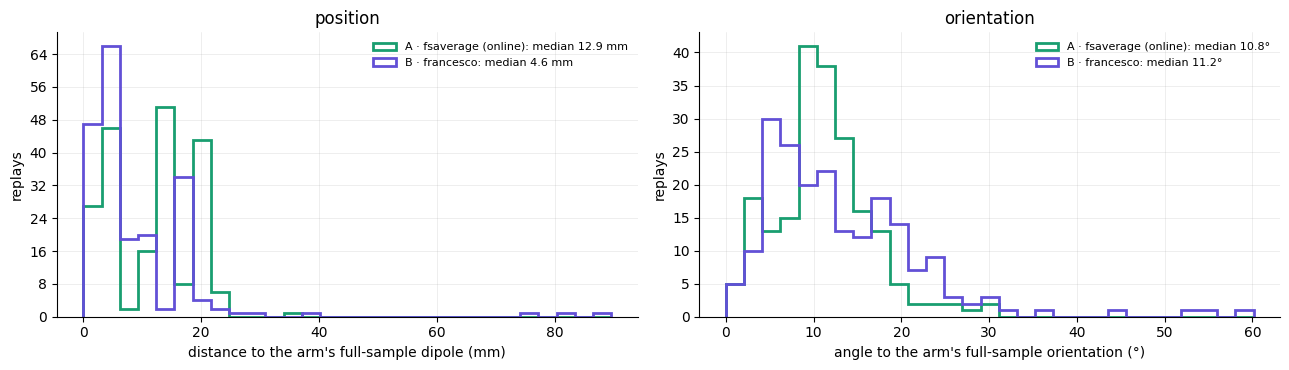

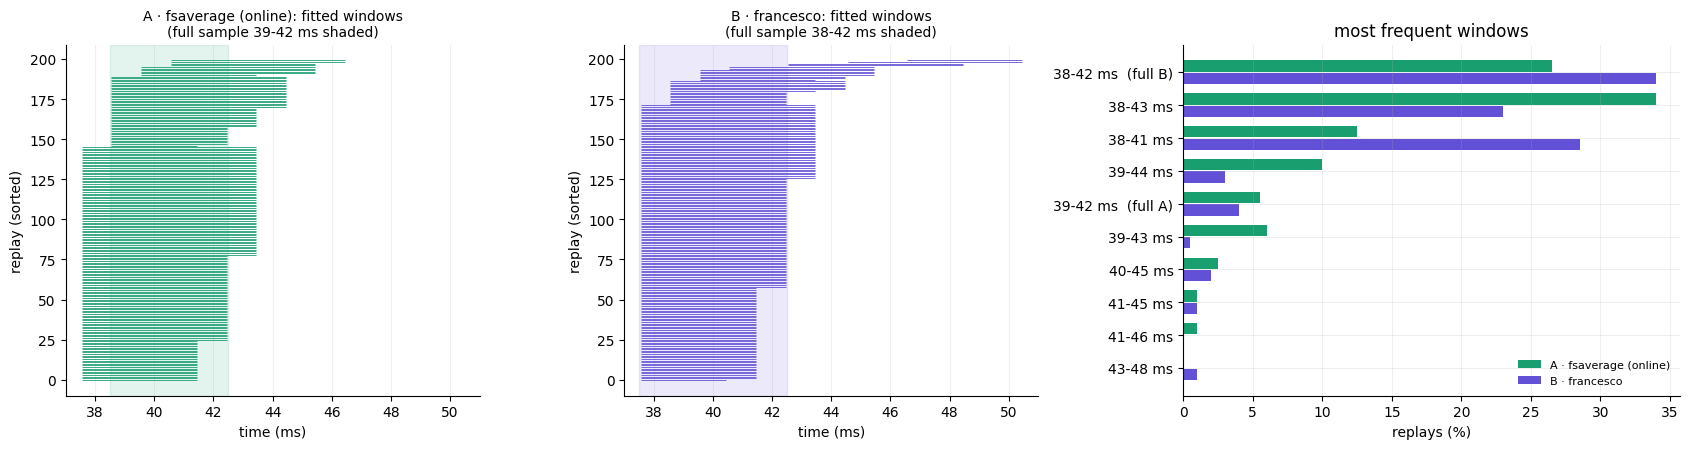

In [22]:
BOOT_HALF = 30
boot_centre = np.mean([DIPOLES[n]["position_mm"] for n in ARMS], axis=0)
fig, axes = plt.subplots(2, 3, figsize=(16, 10.5))
for row, centre in enumerate((None, boot_centre)):
    for ax, (h, v, title) in zip(axes[row], VIEWS):
        draw_source_space(ax, h, v, centre, BOOT_HALF)
        outside = []
        for name in ARMS:
            d, st, full = BOOT[BOOT.arm == name], SOURCE_STYLE[name], DIPOLES[name]
            ax.scatter(d["xyz"[h]], d["xyz"[v]], s=10 if centre is None else 22, color=st["color"], alpha=0.35,
                       linewidths=0, label=f"{source_label(name)}: {N_BOOTSTRAP} replays")
            ax.plot(full["position_mm"][h], full["position_mm"][v], st["marker"], color=st["color"], ms=11,
                    mec="white", mew=2, label=f"{source_label(name)}: full sample")
            if centre is not None:
                n_out = int((np.abs(d[["x", "y", "z"]].to_numpy() - centre) > BOOT_HALF).any(axis=1).sum())
                outside.append(f"{name} {n_out}")
        on = DIPOLES["online"]["position_mm"]
        ax.plot(on[h], on[v], "o", ms=16, mfc="none", mec=SOURCE_STYLE["online"]["color"], mew=1.8, label="online")
        ax.set(xlabel=f"{'xyz'[h]} (mm)", ylabel=f"{'xyz'[v]} (mm)")
        ax.set_title(title if centre is None else f"{title}, ±{BOOT_HALF} mm\nreplays outside: {', '.join(outside)}",
                     fontsize=10)
        ax.set_aspect("equal")
axes[0, 0].legend(fontsize=8, loc="lower left")
fig.suptitle("bootstrap dipole positions", y=1.0)
fig.tight_layout()
plt.show()

fig, axes = plt.subplots(1, 2, figsize=(13, 3.8))
for name in ARMS:
    d, st = BOOT[BOOT.arm == name], SOURCE_STYLE[name]
    axes[0].hist(d.distance_mm, bins=np.linspace(0, max(1, BOOT.distance_mm.max()), 30), histtype="step", lw=2,
                 color=st["color"], label=f"{source_label(name)}: median {d.distance_mm.median():.1f} mm")
    axes[1].hist(d.angle_deg, bins=np.linspace(0, max(1, BOOT.angle_deg.max()), 30), histtype="step", lw=2,
                 color=st["color"], label=f"{source_label(name)}: median {d.angle_deg.median():.1f}°")
axes[0].set(xlabel="distance to the arm's full-sample dipole (mm)", ylabel="replays", title="position")
axes[1].set(xlabel="angle to the arm's full-sample orientation (°)", ylabel="replays", title="orientation")
for ax in axes:
    ax.legend(fontsize=8)
    ax.yaxis.set_major_locator(mticker.MaxNLocator(integer=True))
fig.tight_layout()
plt.show()

fig, axes = plt.subplots(1, 3, figsize=(17, 4.6), gridspec_kw=dict(width_ratios=[1, 1, 1.2]))
for ax, name in zip(axes[:2], ARMS):
    d, st, full = BOOT[BOOT.arm == name].sort_values(["start_ms", "end_ms"]), SOURCE_STYLE[name], DIPOLES[name]
    ax.axvspan(full["window_ms"][0] - 0.5, full["window_ms"][1] + 0.5, color=st["color"], alpha=0.12)
    ax.hlines(np.arange(len(d)), d.start_ms - 0.45, d.end_ms + 0.45, color=st["color"],
              lw=max(0.3, min(1.2, 120 / max(1, len(d)))))
    ax.set(xlim=(DIP_TMIN * 1e3 - 1, DIP_TMAX * 1e3 + 1), xlabel="time (ms)", ylabel="replay (sorted)",
           title=f"{source_label(name)}: fitted windows\n(full sample {full['window_ms'][0]:.0f}-"
                 f"{full['window_ms'][1]:.0f} ms shaded)")
    ax.title.set_fontsize(10)
    ax.grid(axis="y", visible=False)
counts = BOOT.groupby(["window", "arm"]).size().unstack(fill_value=0)
counts = counts.loc[counts.sum(axis=1).sort_values(ascending=False).index[:10]]
width = 0.38
for j, name in enumerate(ARMS):
    if name in counts:
        axes[2].barh(np.arange(len(counts)) + (j - 0.5) * width, 100 * counts[name] / N_BOOTSTRAP, height=width * 0.9,
                     color=SOURCE_STYLE[name]["color"], label=source_label(name))
labels = [w + "  (full A)" * (w == window_name(*DIPOLES["A"]["index_range"]))
          + "  (full B)" * (w == window_name(*DIPOLES["B"]["index_range"])) for w in counts.index]
axes[2].set_yticks(np.arange(len(counts)), labels)
axes[2].invert_yaxis()
axes[2].set(xlabel="replays (%)", title="most frequent windows")
axes[2].legend(fontsize=8)
fig.tight_layout()
plt.show()

## 6 · Intervention replay

### 6.1 Replay with both arms

Trial by trial, in session order, as `process_intervention_pulse()` and `analyze_tep()` of the commit, with each
arm's own calibration and continual adaptation:

1. **TEP**: `preprocess_post()` on the `_post_raw` buffer → `fit_trial()` with the arm's dipole →
   `TEPNormalizer.transform_verbose()` (single pulses only), which appends the amplitude to the normaliser's EWMA
   history. A rejected trial gets no amplitude and does not enter the history.
2. **Model input** of every single pulse: for non-forced PRIME singles the window that triggered the pulse online
   (`_pre_proc`, through the arm's MAD gates and the crop to the model window, `PRE_WINDOW = "online"`), otherwise
   the pulse-aligned `_pre_raw` through the arm's `preprocess_pre()`, as `preprocess_pre_from_pulse()`. If an arm
   interpolated other channels than the session, its PRIME singles use `_pre_raw` too.
3. **Prediction** before the trial's finetuning step, as online. Unlike online, every single pulse whose window
   passes the gates gets one (forced trials and predetermined trials with a rejected post window included).
4. **Finetuning**: `finetune(window, label)` when both exist, as online.

`prime_triplet` trials (`REPLAY_TRIPLETS`) only go through step 1 without the normaliser, as
`analyze_tep(update_normalizer=False)`. The model is saved at the end of each block under the online names
(`classifier_after_trial_200.pt`, …).

**Timing.** Every step is timed per pulse (wall clock; `torch.cuda.synchronize()` before the model steps are read).
`pulse_ms` adds up what `process_intervention_pulse()` itself runs for that trial: the post window, the fit and the
normaliser; for forced PRIME singles and predetermined singles also the pre window from the pulse, for
predetermined singles the prediction, and the finetuning step when there is one (a rejected post window ends the
pulse there). The extra predictions the replay makes, and the pre window of non-forced PRIME singles (computed
online in `process_periodic()`, before the pulse), are timed but not added. The online `process_pulse` profile also
writes the buffers and a classifier checkpoint after every trial, so it sits above the replay's numbers.

In [23]:
ONLINE_COLS = ["prediction_probability", "preprocessing_failed", "postprocessing_failed", "post_reject_reason",
               "tep_amplitude", "tep_amplitude_raw"]
REPLAY_COLS = ["replayed", "postprocessing_failed", "post_reject_reason", "tep_amplitude", "tep_amplitude_raw",
               "tep_ewma", "tep_detrended", "tep_zscore", "pre_source", "preprocessing_failed", "pre_reject_reason",
               "prediction_probability", "finetuned", "t_post_ms", "t_fit_ms", "t_norm_ms", "t_pre_ms",
               "t_predict_ms", "t_finetune_ms", "pulse_ms"]
SAME_BAD_CHANNELS = {name: sorted(map(str, CALIB[name]["bundle"]["bad_channels"]))
                     == sorted(map(str, ONLINE["bundle"]["bad_channels"])) for name in ARMS}


def gate_pre(pp, pre_epoch):
    # The end of Preprocessor.preprocess_pre(): global MAD gate, local MAD gate, crop to the model window.
    stats_qc = pp.calibration_params["good_trial_stats_qc"]
    opts = pp._opts["trial_reject_opts"]["pre"]
    if global_mad_zscore_rejected(pre_epoch, stats_qc["mads_mean"], stats_qc["mads_std"],
                                  opts["global_zscore_threshold"], pp._mad_workspace):
        return None, "global_mad"
    if local_mad_zscore_rejected(pre_epoch, opts["local_zscore_threshold"], pp._mad_workspace):
        return None, "local_mad"
    return model_crop(pre_epoch), None


def pre_window(name, pp, r):
    # The model input of a single pulse, as the decider made it: (window or None, source, reject reason, ms)
    tic = time.perf_counter()
    if (PRE_WINDOW == "online" and r.condition == "prime_single_pulse" and not r.is_forced
            and "pre_proc" in RAW.get(r.stem, {}) and SAME_BAD_CHANNELS[name]):
        window, reason = gate_pre(pp, RAW[r.stem]["pre_proc"])
        source = "_pre_proc"
    else:
        window, epoch = run_preprocess_pre(pp, r.stem)
        reason = None if window is not None else gate_pre(pp, epoch)[1]
        source = "_pre_raw"
    return window, source, reason, (time.perf_counter() - tic) * 1e3


def replay_intervention(name):
    arm, cal = ARMS[name], CALIB[name]
    pp, fitter, normalizer, predictor = cal["pp"], cal["fitter"], cal["normalizer"], cal["predictor"]
    if RUN_MODEL:
        set_rng_state(cal["rng"])                  # continue the random stream of this arm's calibration
    rows, t0 = [], time.time()
    for block in BLOCKS:
        for r in IV[IV.stage == block].itertuples():
            single = r.condition != "prime_triplet"
            row = dict(stem=r.stem, replayed=bool(single or REPLAY_TRIPLETS))
            if row["replayed"]:
                x, t = post_raw(r.stem)
                tic = time.perf_counter()
                post = pp.preprocess_post(x, t)
                row["t_post_ms"] = (time.perf_counter() - tic) * 1e3
                row.update(postprocessing_failed=post is None, post_reject_reason=pp.last_post_reject_reason)
                pulse = row["t_post_ms"]
                if post is not None:
                    tic = time.perf_counter()
                    amplitude = fitter.fit_trial(post)
                    row["t_fit_ms"] = (time.perf_counter() - tic) * 1e3
                    pulse += row["t_fit_ms"]
                    if single:
                        tic = time.perf_counter()
                        tep = normalizer.transform_verbose(amplitude)
                        row["t_norm_ms"] = (time.perf_counter() - tic) * 1e3
                        pulse += row["t_norm_ms"]
                        row.update(tep_amplitude=tep["label"], tep_amplitude_raw=tep["raw"], tep_ewma=tep["ewma"],
                                   tep_detrended=tep["detrended"], tep_zscore=tep["zscore"])
                    else:
                        row["tep_amplitude_raw"] = float(amplitude)
                if single and RUN_MODEL:
                    window, source, reason, pre_ms = pre_window(name, pp, r)
                    row.update(pre_source=source, preprocessing_failed=window is None, pre_reject_reason=reason,
                               t_pre_ms=pre_ms)
                    online_pre = r.condition == "predetermined_single" or r.is_forced     # done inside the pulse
                    if post is not None and online_pre:
                        pulse += pre_ms
                    if window is not None:
                        tic = time.perf_counter()
                        row["prediction_probability"] = predictor.predict(window)
                        row["t_predict_ms"] = (time.perf_counter() - tic) * 1e3
                        if post is not None and r.condition == "predetermined_single":
                            pulse += row["t_predict_ms"]
                    row["finetuned"] = bool(window is not None and post is not None)
                    if row["finetuned"]:
                        tic = time.perf_counter()
                        predictor.finetune(window, row["tep_amplitude"])
                        cuda_sync()
                        row["t_finetune_ms"] = (time.perf_counter() - tic) * 1e3
                        pulse += row["t_finetune_ms"]
                row["pulse_ms"] = pulse
            rows.append(row)
        if RUN_MODEL:
            predictor.save_checkpoint(arm["dir"] / f"classifier_after_trial_{BLOCK_END[block]}.pt")
    rep = pd.DataFrame(rows).reindex(columns=["stem"] + REPLAY_COLS)
    online = IV[["stem", "stage", "trial_in_stage", "condition", "is_forced", "g", "lat_ms"] + ONLINE_COLS
                + (["online_process_pulse_ms"] if "online_process_pulse_ms" in IV else [])]
    rep = online.rename(columns={c: "online_" + c for c in ONLINE_COLS}).merge(rep, on="stem", how="left")
    n_single = int((rep.replayed.fillna(False).astype(bool) & (rep.condition != "prime_triplet")).sum())
    n_trip = int((rep.replayed.fillna(False).astype(bool) & (rep.condition == "prime_triplet")).sum())
    print(f"{source_label(name):{LABEL_W}s}: {n_single} single pulses and {n_trip} triplets in {time.time() - t0:.0f} s"
          + (f"; model inputs: {rep.pre_source.value_counts().to_dict()}" if RUN_MODEL else ""))
    return rep


REP = {name: replay_intervention(name) for name in ARMS}

A · fsaverage (online): 320 single pulses and 480 triplets in 47 s; model inputs: {'_pre_proc': 231, '_pre_raw': 89}
B · francesco         : 320 single pulses and 480 triplets in 45 s; model inputs: {'_pre_proc': 231, '_pre_raw': 89}


### 6.2 Open-loop blocks

The baseline block and the four evaluation runs computed nothing online. Their post windows go through each
source's `preprocess_post()` and `fit_trial()`: the online source uses the stored bundle and dipole (as in
`PRIME_online_performance.ipynb`), the arms their own calibration. These amplitudes feed section 7.

In [24]:
OPEN_SOURCES = {"online": (ONLINE["pp"], ONLINE["fitter"]), **{n: (CALIB[n]["pp"], CALIB[n]["fitter"]) for n in ARMS}}
OPEN_REP = {}
for src, (pp, fitter) in OPEN_SOURCES.items():
    rows, t0 = [], time.time()
    for r in OPEN.itertuples():
        x, t = post_raw(r.stem)
        tic = time.perf_counter()
        post = pp.preprocess_post(x, t)
        t_post = (time.perf_counter() - tic) * 1e3
        tic = time.perf_counter()
        amp = fitter.fit_trial(post) if post is not None else np.nan
        rows.append({"stem": r.stem, "block": r.block, "post_reject_reason": pp.last_post_reject_reason,
                     "tep_amplitude_raw": amp, "t_post_ms": t_post,
                     "t_fit_ms": (time.perf_counter() - tic) * 1e3 if post is not None else np.nan})
    OPEN_REP[src] = pd.DataFrame(rows)
    print(f"{source_label(src):{LABEL_W}s}: {len(rows)} open-loop trials, "
          f"{int(OPEN_REP[src].tep_amplitude_raw.notna().sum())} kept, in {time.time() - t0:.0f} s")
display(pd.DataFrame({source_label(s): d.groupby("block", sort=False).post_reject_reason.apply(
    lambda v: f"{int(v.isna().sum())} kept / {len(v)}") for s, d in OPEN_REP.items()}).reindex(OPEN_BLOCKS))

online log            : 500 open-loop trials, 426 kept, in 20 s
A · fsaverage (online): 500 open-loop trials, 426 kept, in 19 s
B · francesco         : 500 open-loop trials, 426 kept, in 19 s


,online log,A · fsaverage (online),B · francesco
block,,,
baseline,83 kept / 100,83 kept / 100,82 kept / 100
t0,97 kept / 100,97 kept / 100,97 kept / 100
t15,84 kept / 100,84 kept / 100,85 kept / 100
t30,82 kept / 100,82 kept / 100,82 kept / 100
t60,80 kept / 100,80 kept / 100,80 kept / 100


### 6.3 Replay against the online log

Arm A should reproduce every post-side value of the log: rejections exactly, TEP amplitudes and labels to float
precision, for single pulses and triplets alike. Its predictions come from a model calibrated and finetuned again,
so GPU arithmetic can make them drift slightly; that drift is the noise floor for reading arm B. Then the
rejections of both arms, per condition and reason.

In [25]:
SINGLE_CONDITIONS = ["predetermined_single", "prime_single_pulse"]


def replayed(rep, conditions):
    return rep[rep.replayed.fillna(False).astype(bool) & rep.condition.isin(conditions)]


def against_online(rep, conditions, title):
    s = replayed(rep, conditions)
    if s.empty:
        return
    fail, fail_on = s.postprocessing_failed.astype(bool), s.online_postprocessing_failed.astype(bool)
    reason, reason_on = s.post_reject_reason.fillna("kept"), s.online_post_reject_reason.fillna("kept")
    both = s[~fail & ~fail_on]
    raw_rel = (both.tep_amplitude_raw / both.online_tep_amplitude_raw - 1).abs()
    print(title)
    print(f"  postprocessing_failed identical : {int((fail == fail_on).sum())} / {len(s)}")
    print(f"  post_reject_reason identical    : {int((reason == reason_on).sum())} / {len(s)}")
    print(f"  tep_amplitude_raw               : max relative difference {raw_rel.max():.1e} ({len(both)} trials)")
    if "prime_triplet" not in conditions:
        lab = (both.tep_amplitude - both.online_tep_amplitude).abs()
        print(f"  tep_amplitude (label)           : max |diff| {lab.max():.1e}")
        if RUN_MODEL:
            pr = s.dropna(subset=["prediction_probability", "online_prediction_probability"])
            dp = (pr.prediction_probability - pr.online_prediction_probability).abs()
            if len(pr) >= 3:
                print(f"  prediction_probability          : r = "
                      f"{stats.pearsonr(pr.prediction_probability, pr.online_prediction_probability)[0]:.4f}, "
                      f"median |Δp| {dp.median():.1e}, max |Δp| {dp.max():.1e} ({len(pr)} trials)")


against_online(REP["A"], SINGLE_CONDITIONS, "arm A vs online log, single pulses")
against_online(REP["A"], ["prime_triplet"], "arm A vs online log, triplets")

REASONS = ["kept", "ocular", "global_mad", "local_mad"]
tables = {}
for cond in SINGLE_CONDITIONS + (["prime_triplet"] if REPLAY_TRIPLETS else []):
    cols = {"online log": replayed(REP["A"], [cond]).online_post_reject_reason.fillna("kept").value_counts()}
    for name in ARMS:
        cols[source_label(name)] = replayed(REP[name], [cond]).post_reject_reason.fillna("kept").value_counts()
    t = pd.DataFrame(cols).reindex(REASONS).fillna(0).astype(int)
    t.loc["rejected (%)"] = (100 * t.drop(index="kept").sum() / t.sum()).round(1)
    tables[cond] = t
REJECTION_TABLE = pd.concat(tables, names=["condition", "post_reject_reason"])
display(REJECTION_TABLE)
a = replayed(REP["A"], SINGLE_CONDITIONS).set_index("stem").post_reject_reason.fillna("kept")
b = replayed(REP["B"], SINGLE_CONDITIONS).set_index("stem").post_reject_reason.fillna("kept")
print("single pulses, arm A (rows) vs arm B (columns):")
display(pd.crosstab(a.rename("arm A"), b.reindex(a.index).rename("arm B"), margins=True))
if RUN_MODEL:
    counts = {}
    for n in ARMS:
        s = replayed(REP[n], SINGLE_CONDITIONS)
        g = s.assign(pre_rejected=s.preprocessing_failed.astype(bool), finetuned=s.finetuned.astype(bool),
                     post_kept=~s.postprocessing_failed.astype(bool)).groupby("condition")
        counts[source_label(n)] = pd.DataFrame({"trials": g.size(), "post kept": g.post_kept.sum(),
                                                "predicted": g.prediction_probability.count(),
                                                "pre rejected": g.pre_rejected.sum(), "finetuned": g.finetuned.sum()})
    on = SINGLES.assign(post_kept=~SINGLES.postprocessing_failed.astype(bool)).groupby("condition")
    counts["online log"] = pd.DataFrame({"trials": on.size(), "post kept": on.post_kept.sum(),
                                         "predicted": on.prediction_probability.count()})
    display(pd.concat(counts, axis=1).astype("Int64"))

arm A vs online log, single pulses
  postprocessing_failed identical : 320 / 320
  post_reject_reason identical    : 320 / 320
  tep_amplitude_raw               : max relative difference 3.5e-05 (295 trials)
  tep_amplitude (label)           : max |diff| 1.1e-16
  prediction_probability          : r = 1.0000, median |Δp| 6.7e-06, max |Δp| 4.1e-05 (305 trials)
arm A vs online log, triplets
  postprocessing_failed identical : 480 / 480
  post_reject_reason identical    : 480 / 480
  tep_amplitude_raw               : max relative difference 3.9e-05 (405 trials)


online log  A · fsaverage (online)  B · francesco
condition            post_reject_reason                                                   
predetermined_single kept                      74.0                    74.0           74.0
                     ocular                     4.0                     4.0            4.0
                     global_mad                 0.0                     0.0            0.0
                     local_mad                  2.0                     2.0            2.0
                     rejected (%)               7.5                     7.5            7.5
prime_single_pulse   kept                     221.0                   221.0          222.0
                     ocular                    18.0                    18.0           18.0
                     global_mad                 1.0                     1.0            0.0
                     local_mad                  0.0                     0.0            0.0
                     rejected (%)               7.9                     7.9            7.5
prime_triplet        kept                     405.0                   405.0          405.0
                     ocular                    64.0                    64.0           64.0
                     global_mad                 8.0                     8.0            8.0
                     local_mad                  3.0                     3.0            3.0
                     rejected (%)              15.6                    15.6           15.6

single pulses, arm A (rows) vs arm B (columns):


arm B,kept,local_mad,ocular,All
arm A,,,,
global_mad,1,0,0,1
kept,295,0,0,295
local_mad,0,2,0,2
ocular,0,0,22,22
All,296,2,22,320


A · fsaverage (online)                                            B · francesco                                            online log                    
                                     trials post kept predicted pre rejected finetuned        trials post kept predicted pre rejected finetuned     trials post kept predicted
condition                                                                                                                                                                     
predetermined_single                     80        74        80            0        74            80        74        80            0        74         80        74        74
prime_single_pulse                      240       221       240            0       221           240       222       240            0       222        240       221       231

### 6.4 Processing time per pulse

Top: the time `process_intervention_pulse()` takes per pulse in each arm (`pulse_ms`, see 6.1), by condition, with
the online `process_pulse` profile of the same pulses for reference (it includes writing the buffers and a
checkpoint). Bottom: the median time of each step. The forward model can only change the post-side steps: the
post window passes the same matrices (SOUND and SSP-SIR are 60 × 60 multiplications whichever model made them)
and the single-trial fit uses one vertex, so a difference here comes from the trial set (other rejections), not
from the model's size. A larger source space costs time only in the calibration (`DipoleFitter.calibrate()` scans
every source; section 4.1) and in section 5.

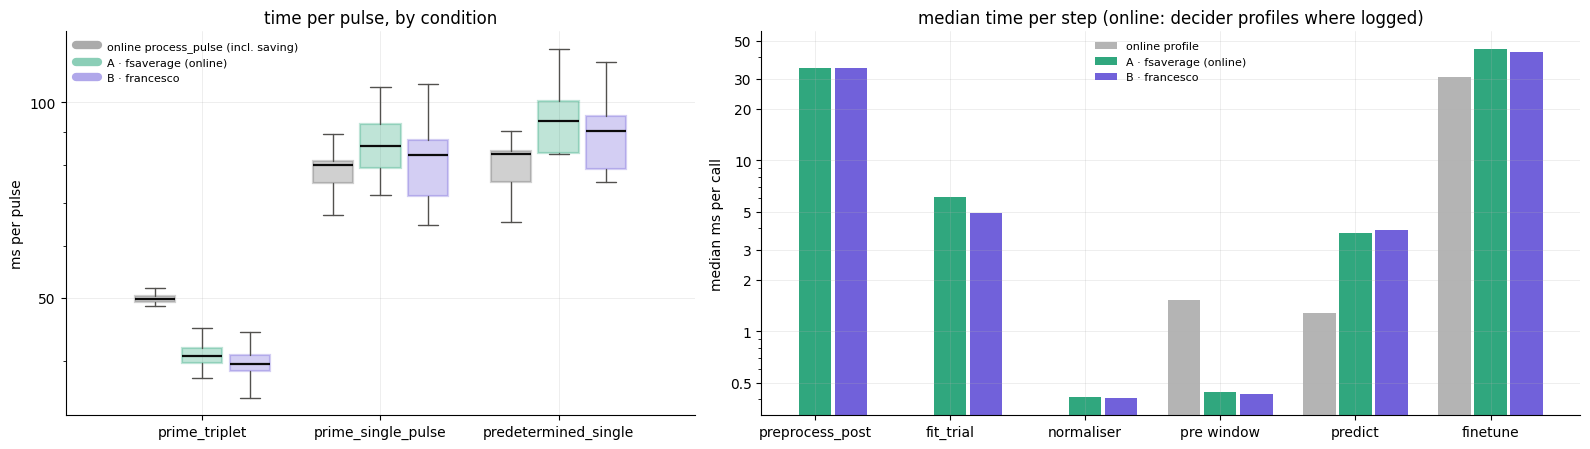

pulses  median (ms)  95th percentile (ms)  max (ms)
source                 condition                                                                
online process_pulse   prime_triplet            480         49.8                  51.3      57.8
                       prime_single_pulse       240         80.2                  83.2     182.2
                       predetermined_single      80         83.3                  85.3      90.2
A · fsaverage (online) prime_triplet            480         40.7                  45.9     248.9
                       prime_single_pulse       240         85.8                 105.6     147.0
                       predetermined_single      80         93.5                 117.8     141.5
B · francesco          prime_triplet            480         39.5                  45.6      57.8
                       prime_single_pulse       240         83.1                  99.5     231.8
                       predetermined_single      80         90.3                 113.5     139.4

,A · fsaverage (online),B · francesco
median ms per call,,
preprocess_post,34.73,34.77
fit_trial,6.10,4.92
normaliser,0.41,0.41
pre window,0.44,0.43
predict,3.77,3.89
finetune,44.83,42.95


open-loop post windows (preprocess_post + fit_trial), median ms: online log 40.0, A · fsaverage (online) 39.5, B · francesco 38.3


In [26]:
COND_ORDER = ["prime_triplet", "prime_single_pulse", "predetermined_single"] if REPLAY_TRIPLETS else SINGLE_CONDITIONS
fig, axes = plt.subplots(1, 2, figsize=(16, 4.6), gridspec_kw=dict(width_ratios=[1, 1.3]))
srcs = (["online"] if "online_process_pulse_ms" in IV else []) + list(ARMS)
width = 0.8 / len(srcs)
for j, src in enumerate(srcs):
    vals = []
    for cond in COND_ORDER:
        if src == "online":
            vals.append(IV.loc[IV.condition == cond, "online_process_pulse_ms"].to_numpy(dtype=float))
        else:
            vals.append(replayed(REP[src], [cond]).pulse_ms.to_numpy(dtype=float))
    pos = np.arange(len(COND_ORDER)) + (j - (len(srcs) - 1) / 2) * width
    boxes(axes[0], vals, pos, [SOURCE_STYLE[src]["color"]] * len(COND_ORDER), width=width * 0.85)
    axes[0].plot([], [], color=SOURCE_STYLE[src]["color"], lw=6, alpha=0.5,
                 label="online process_pulse (incl. saving)" if src == "online" else source_label(src))
axes[0].set_xticks(np.arange(len(COND_ORDER)), COND_ORDER)
axes[0].set(ylabel="ms per pulse", title="time per pulse, by condition", yscale="log")
plain_log(axes[0])
axes[0].legend(fontsize=8)

STEP_COLS = {"t_post_ms": "preprocess_post", "t_fit_ms": "fit_trial", "t_norm_ms": "normaliser",
             "t_pre_ms": "pre window", "t_predict_ms": "predict", "t_finetune_ms": "finetune"}
steps = [c for c in STEP_COLS if any(REP[n][c].notna().any() for n in ARMS)]
online_steps = {"t_pre_ms": "preprocess_pre", "t_predict_ms": "predict", "t_finetune_ms": "finetune"}
width = 0.8 / (len(ARMS) + 1)
for j, src in enumerate(["online"] + list(ARMS)):
    med = []
    for c in steps:
        if src == "online":
            v = ONLINE_PROFILE.get(online_steps.get(c, ""), np.array([np.nan]))
        else:
            v = REP[src][c].to_numpy(dtype=float)
        med.append(np.nanmedian(v) if np.isfinite(v).any() else np.nan)
    axes[1].bar(np.arange(len(steps)) + (j - len(ARMS) / 2) * width, med, width=width * 0.9,
                color=SOURCE_STYLE[src]["color"], alpha=0.9 if src != "online" else 0.45,
                label="online profile" if src == "online" else source_label(src))
axes[1].set_xticks(np.arange(len(steps)), [STEP_COLS[c] for c in steps])
axes[1].set(ylabel="median ms per call", title="median time per step (online: decider profiles where logged)",
            yscale="log")
plain_log(axes[1])
axes[1].legend(fontsize=8)
fig.tight_layout()
plt.show()

rows = []
for src in srcs:
    for cond in COND_ORDER:
        v = (IV.loc[IV.condition == cond, "online_process_pulse_ms"] if src == "online"
             else replayed(REP[src], [cond]).pulse_ms).astype(float).dropna()
        rows.append({"source": "online process_pulse" if src == "online" else source_label(src), "condition": cond,
                     "pulses": len(v), "median (ms)": v.median(), "95th percentile (ms)": v.quantile(0.95),
                     "max (ms)": v.max()})
TIMING_TABLE = pd.DataFrame(rows).set_index(["source", "condition"])
display(TIMING_TABLE.round(1))
STEP_TABLE = pd.DataFrame({source_label(n): {STEP_COLS[c]: REP[n][c].median() for c in steps} for n in ARMS})
display(STEP_TABLE.round(2).rename_axis("median ms per call"))
print("open-loop post windows (preprocess_post + fit_trial), median ms: "
      + ", ".join(f"{source_label(s)} {(d.t_post_ms + d.t_fit_ms.fillna(0)).median():.1f}" for s, d in OPEN_REP.items()))

### 6.5 Trial tables

One `trials_intervention.csv` per arm, with the rows of the online file (calibration and intervention) and the
replayed values under the online column names, the online values with an `online_` prefix, the timing columns,
`pre_source`, `pre_reject_reason`, `finetuned` and `replayed`. Calibration rows carry the calibration amplitude and
label of surviving trials and the gate that dropped a trial (`calibration_dropped`). The open-loop amplitudes of all
sources go to `open_loop_trials.csv`.

In [27]:
TIMING_COLS = [c for c in ["iti", "trial_start_time", "target_time", "max_time", "trigger_time", "pulse_time",
                           "prime_attempts", "qc_failures", "threshold", "search_time"] if c in TRIALS]


def trial_table(name):
    cal = CALIB[name]
    gate_of = lambda bundle: {int(i): GATE_NAMES[g] for g, idx in bundle["trials_dropped"].items() for i in idx}
    dropped, dropped_on = gate_of(cal["bundle"]), gate_of(ONLINE["bundle"])
    amp, lab = dict(zip(cal["kept"], cal["amplitudes"])), dict(zip(cal["kept"], cal["labels"]))
    cal_rows = pd.DataFrame([dict(
        stem=r.stem, replayed=True, calibration_dropped=dropped.get(r.trial_in_stage, ""),
        online_calibration_dropped=dropped_on.get(r.trial_in_stage, ""),
        preprocessing_failed=dropped.get(r.trial_in_stage) == GATE_NAMES["qc"],
        postprocessing_failed=dropped.get(r.trial_in_stage) in (GATE_NAMES["ocular"], GATE_NAMES["post"]),
        tep_amplitude_raw=amp.get(r.trial_in_stage, np.nan), tep_amplitude=lab.get(r.trial_in_stage, np.nan),
    ) for r in CAL.itertuples()])
    iv_rows = REP[name][["stem"] + REPLAY_COLS]
    table = TRIALS[["stem", "stage", "trial_in_stage", "condition", "is_forced", "trial_order", "lat_ms"] + TIMING_COLS]
    table = table.merge(pd.concat([cal_rows, iv_rows], ignore_index=True), on="stem", how="left")
    for c in ONLINE_COLS:
        table["online_" + c] = TRIALS[c].to_numpy()
    return table.rename(columns={"lat_ms": "trigger_latency_ms"})


TABLES = {}
for name, arm in ARMS.items():
    TABLES[name] = trial_table(name)
    TABLES[name].to_csv(arm["dir"] / "trials_intervention.csv", index=False)
    print(f"{arm['label']:{LABEL_W}s} -> {arm['dir'] / 'trials_intervention.csv'} ({len(TABLES[name])} rows)")
pd.concat({s: d for s, d in OPEN_REP.items()}, names=["source"]).reset_index(level=0).to_csv(
    RESULTS_ROOT / "open_loop_trials.csv", index=False)

A · fsaverage (online) -> D:\Linus\Loop\offline_fwdmodel\sub-pilot005\arm_A_fsaverage\trials_intervention.csv (925 rows)
B · francesco          -> D:\Linus\Loop\offline_fwdmodel\sub-pilot005\arm_B_francesco\trials_intervention.csv (925 rows)


## 7 · TEP amplitudes

The free-orientation dipole amplitude (`tep_amplitude_raw`) of every kept single pulse, per block and condition, in
session order: the baseline block, the two single-pulse conditions of the intervention blocks (PRIME-triggered and
predetermined), and the four evaluation runs. Sources:

- **online**: intervention trials from the log; open-loop blocks from the stored bundle and dipole (section 6.2),
  since nothing was computed online there;
- **A** and **B**: their own replay (sections 6.1 and 6.2).

Each source uses its own rejections, dipole and window, so raw amplitudes of A and B are not on a common scale: a
different leadfield changes the amplitude a dipole needs to explain the same scalp field. 7.2 therefore also shows
each source relative to its own baseline median, which is comparable across sources.

In [28]:
CATEGORIES = (["baseline"] if "baseline" in OPEN_BLOCKS else []) + ["PRIME single", "predetermined single"] \
             + [b for b in EVAL_LABELS if b in OPEN_BLOCKS]
CAT_OF_CONDITION = {"prime_single_pulse": "PRIME single", "predetermined_single": "predetermined single"}
rows = []
for src in SOURCES:
    if src == "online":
        iv = SINGLES[~SINGLES.postprocessing_failed.astype(bool)]
        iv = iv.assign(amp=iv.tep_amplitude_raw.astype(float))
    else:
        iv = replayed(REP[src], SINGLE_CONDITIONS)
        iv = iv[~iv.postprocessing_failed.astype(bool)].assign(amp=lambda d: d.tep_amplitude_raw.astype(float))
    rows += [{"source": src, "category": CAT_OF_CONDITION[r.condition], "stem": r.stem, "amp": r.amp}
             for r in iv.itertuples()]
    op = OPEN_REP[src].dropna(subset=["tep_amplitude_raw"])
    rows += [{"source": src, "category": r.block, "stem": r.stem, "amp": r.tep_amplitude_raw} for r in op.itertuples()]
AMP = pd.DataFrame(rows)
AMP = AMP[AMP.category.isin(CATEGORIES)]
base_median = AMP[AMP.category == "baseline"].groupby("source").amp.median() if "baseline" in CATEGORIES else None
if base_median is not None:
    AMP["rel"] = AMP.amp / AMP.source.map(base_median)

rows = []
for src in SOURCES:
    for cat in CATEGORIES:
        v = AMP[(AMP.source == src) & (AMP.category == cat)].amp.to_numpy()
        row = {"source": source_label(src), "category": cat, "n": len(v), "median": np.median(v) if len(v) else np.nan,
               "IQR": np.subtract(*np.percentile(v, [75, 25])) if len(v) else np.nan}
        if base_median is not None and cat != "baseline" and len(v):
            b = AMP[(AMP.source == src) & (AMP.category == "baseline")].amp.to_numpy()
            u = stats.mannwhitneyu(v, b, alternative="two-sided")
            row.update({"median / baseline median": np.median(v) / base_median[src],
                        "rank-biserial vs baseline": 2 * u.statistic / (len(v) * len(b)) - 1, "p (MWU)": u.pvalue})
        rows.append(row)
TEP_TABLE = pd.DataFrame(rows).set_index(["source", "category"])
display(TEP_TABLE.round(4))
TEP_TABLE.to_csv(RESULTS_ROOT / "tep_amplitudes_by_block.csv")
AMP.to_csv(RESULTS_ROOT / "tep_amplitudes_trials.csv", index=False)

n   median      IQR  median / baseline median  rank-biserial vs baseline  p (MWU)
source                 category                                                                                                 
online log             baseline               83   0.0311   0.0174                       NaN                        NaN      NaN
                       PRIME single          221   0.0461   0.0322                    1.4840                     0.3810   0.0000
                       predetermined single   74   0.0416   0.0264                    1.3383                     0.2911   0.0017
                       t0                     97   0.0436   0.0241                    1.4038                     0.3536   0.0000
                       t15                    84   0.0469   0.0246                    1.5099                     0.3669   0.0000
                       t30                    82   0.0425   0.0201                    1.3700                     0.3344   0.0002
                       t60                    80   0.0399   0.0228                    1.2834                     0.2877   0.0015
A · fsaverage (online) baseline               83   0.0311   0.0174                       NaN                        NaN      NaN
                       PRIME single          221   0.0461   0.0322                    1.4840                     0.3810   0.0000
                       predetermined single   74   0.0416   0.0264                    1.3383                     0.2911   0.0017
                       t0                     97   0.0436   0.0241                    1.4038                     0.3536   0.0000
                       t15                    84   0.0469   0.0246                    1.5099                     0.3669   0.0000
                       t30                    82   0.0425   0.0201                    1.3700                     0.3344   0.0002
                       t60                    80   0.0399   0.0228                    1.2834                     0.2877   0.0015
B · francesco          baseline               82  22.9938  12.3228                       NaN                        NaN      NaN
                       PRIME single          222  35.6189  24.5874                    1.5491                     0.3759   0.0000
                       predetermined single   74  30.9568  17.6148                    1.3463                     0.2877   0.0020
                       t0                     97  32.7112  18.2165                    1.4226                     0.3241   0.0002
                       t15                    85  35.9276  21.9506                    1.5625                     0.3971   0.0000
                       t30                    82  32.8031  15.3964                    1.4266                     0.3483   0.0001
                       t60                    80  31.2647  17.7688                    1.3597                     0.3128   0.0006

### 7.1 Per source

One panel per source, the seven categories in session order (predet. = predetermined); each box is the median and
quartiles (whiskers to 1.5 IQR), dots are trials. The y-axes are not shared: A and B can differ in scale.

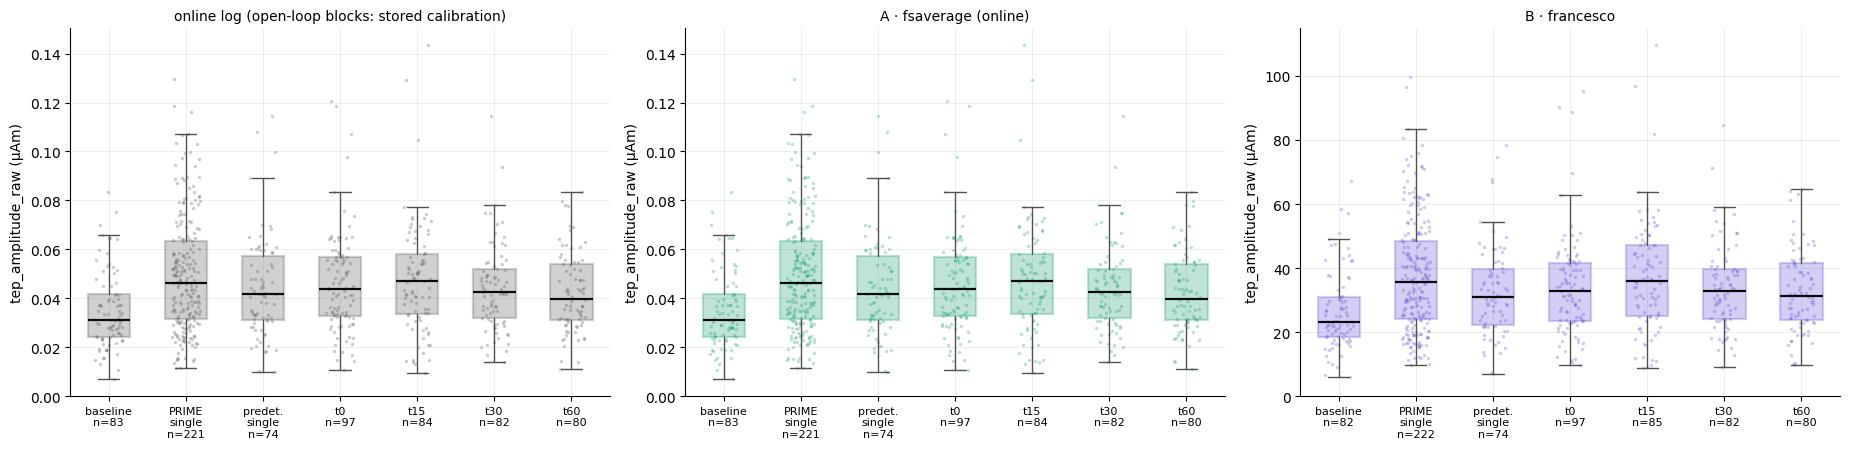

In [29]:
fig, axes = plt.subplots(1, len(SOURCES), figsize=(6.2 * len(SOURCES), 4.6))
rng_jitter = np.random.default_rng(1)
for ax, src in zip(axes, SOURCES):
    st = SOURCE_STYLE[src]
    vals = [AMP[(AMP.source == src) & (AMP.category == c)].amp.to_numpy() for c in CATEGORIES]
    for i, v in enumerate(vals):
        ax.scatter(i + rng_jitter.uniform(-0.18, 0.18, len(v)), v, s=6, color=st["color"], alpha=0.3, linewidths=0)
    boxes(ax, vals, np.arange(len(CATEGORIES)), [st["color"]] * len(CATEGORIES), width=0.55)
    short = {"PRIME single": "PRIME\nsingle", "predetermined single": "predet.\nsingle"}
    ax.set_xticks(np.arange(len(CATEGORIES)), [f"{short.get(c, c)}\nn={len(v)}" for c, v in zip(CATEGORIES, vals)],
                  fontsize=8)
    ax.set(ylabel="tep_amplitude_raw (µAm)", ylim=(0, None),
           title=source_label(src) + (" (open-loop blocks: stored calibration)" if src == "online" else ""))
    ax.title.set_fontsize(10)
fig.tight_layout()
plt.show()

### 7.2 All sources next to each other

Top: raw amplitudes, the three sources side by side in every category. Bottom: each trial divided by its source's
baseline median, so a source's baseline sits at 1 and a value of 1.2 means 20 % above that source's own baseline;
this is the readout that compares across forward models.

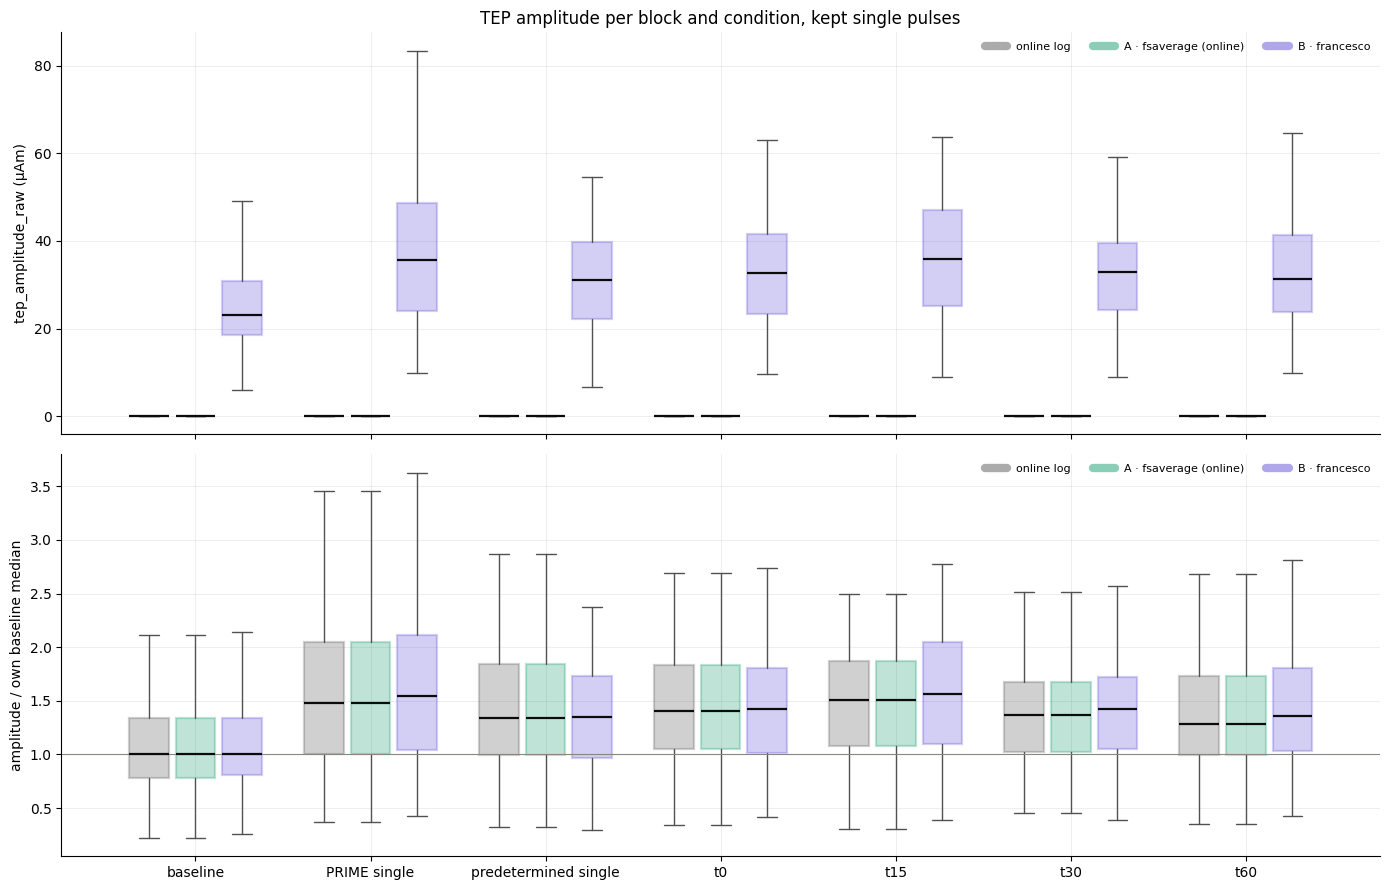

In [30]:
fig, axes = plt.subplots(2, 1, figsize=(14, 9), sharex=True)
width = 0.8 / len(SOURCES)
for row_ax, col, ylabel in ((axes[0], "amp", "tep_amplitude_raw (µAm)"),
                            (axes[1], "rel", "amplitude / own baseline median")):
    if col not in AMP:
        row_ax.set_visible(False)
        continue
    for j, src in enumerate(SOURCES):
        st = SOURCE_STYLE[src]
        vals = [AMP[(AMP.source == src) & (AMP.category == c)][col].to_numpy() for c in CATEGORIES]
        pos = np.arange(len(CATEGORIES)) + (j - (len(SOURCES) - 1) / 2) * width
        boxes(row_ax, vals, pos, [st["color"]] * len(CATEGORIES), width=width * 0.85)
        row_ax.plot([], [], color=st["color"], lw=6, alpha=0.5, label=source_label(src))
    row_ax.set(ylabel=ylabel)
    row_ax.legend(fontsize=8, ncol=3, loc="upper right")
axes[1].axhline(1, color=INK_MUTED, lw=0.8)
axes[1].set_xticks(np.arange(len(CATEGORIES)), CATEGORIES)
axes[0].set_title("TEP amplitude per block and condition, kept single pulses")
fig.tight_layout()
plt.show()

## 8 · Prediction performance on the intervention trials

The PRIME model's prediction for every single pulse against the arms, the raw TEP amplitude and the label. Sources:
the online log (`prediction_probability` as logged: the trigger probability of non-forced PRIME singles, the
retrospective prediction of predetermined singles whose post window was kept; none for forced trials) and the two
replays (every single pulse with a valid model input, section 6.1). Each prediction was made before its trial's
finetuning step, so all of them are prospective.

Two things to keep in mind when reading the panels. PRIME singles were selected by the online model and threshold,
so their predictions are range-restricted (high p only) for the online source; `predetermined_single` trials are
the unselected ones and the cleaner test. And each source is scored on its own trials (its own rejections and
model inputs), so n differs; the table also gives every correlation on the trials all three sources share, with a
paired bootstrap interval for ρ_B − ρ_A. Skipped with `RUN_MODEL = False`.

In [31]:
PERF, CORR = {}, []
N_BOOT_CORR = 2000


def perf_table(src):
    if src == "online":
        d = SINGLES.assign(p=SINGLES.prediction_probability, label=SINGLES.tep_amplitude, raw=SINGLES.tep_amplitude_raw)
    else:
        d = replayed(REP[src], SINGLE_CONDITIONS)
        d = d.assign(p=d.prediction_probability, label=d.tep_amplitude, raw=d.tep_amplitude_raw)
    return d[["stem", "stage", "condition", "is_forced", "g", "p", "label", "raw"]].astype(
        {"p": float, "label": float, "raw": float}).set_index("stem")


def corr_panel(ax, x, y, cond, title, xlabel, ylabel, identity=False):
    for c, color in CONDITION_COLORS.items():
        m = cond == c
        if m.any():
            ax.scatter(x[m], y[m], s=14, alpha=0.6, color=color, linewidths=0, label=f"{c} (n={int(m.sum())})")
    out = {"n": len(x)}
    if len(x) >= 3:
        r, p_r = stats.pearsonr(x, y)
        rho, p_rho = stats.spearmanr(x, y)
        out.update(r=r, p_r=p_r, rho=rho, p_rho=p_rho)
        if identity:
            ax.plot([0, 1], [0, 1], color=INK_MUTED, lw=0.8)
        else:
            b1, b0 = np.polyfit(x, y, 1)
            xs = np.linspace(x.min(), x.max(), 20)
            ax.plot(xs, b0 + b1 * xs, color=INK_2, lw=1.5)
        title += f"\nr = {r:+.3f} ({fmt_p(p_r)})   ρ = {rho:+.3f} ({fmt_p(p_rho)})   n = {len(x)}"
    else:
        title += f"\nfewer than 3 trials"
    ax.set_title(title, fontsize=9)
    ax.set(xlabel=xlabel, ylabel=ylabel, xlim=(0, 1))                 # predictions are probabilities
    if identity:
        ax.set(ylim=(0, 1), aspect="equal")
    if ax.get_legend_handles_labels()[0]:
        ax.legend(fontsize=7, loc="best")
    return out


def paired_rho_diff(d, ycol, n_boot=N_BOOT_CORR, seed=0):
    # rho(p_B, y_B) - rho(p_A, y_A) on common trials, percentile bootstrap over trials
    rng = np.random.default_rng(seed)
    pa, ya, pb, yb = (d[c].to_numpy() for c in ("p_A", f"{ycol}_A", "p_B", f"{ycol}_B"))
    obs = stats.spearmanr(pb, yb)[0] - stats.spearmanr(pa, ya)[0]
    boot = []
    for _ in range(n_boot):
        i = rng.integers(0, len(d), len(d))
        boot.append(stats.spearmanr(pb[i], yb[i])[0] - stats.spearmanr(pa[i], ya[i])[0])
    lo, hi = np.nanpercentile(boot, [2.5, 97.5])
    return obs, lo, hi


if RUN_MODEL:
    PERF = {src: perf_table(src) for src in SOURCES}
    for src, d in PERF.items():
        print(f"{source_label(src):{LABEL_W}s}: {int(d.p.notna().sum())} single pulses with a prediction "
              f"({', '.join(f'{c} {int(d[d.condition == c].p.notna().sum())}' for c in SINGLE_CONDITIONS)})")
else:
    print("skipped (RUN_MODEL = False)")

online log            : 305 single pulses with a prediction (predetermined_single 74, prime_single_pulse 231)
A · fsaverage (online): 320 single pulses with a prediction (predetermined_single 80, prime_single_pulse 240)
B · francesco         : 320 single pulses with a prediction (predetermined_single 80, prime_single_pulse 240)


### 8.1 Predictions: each arm against the online predictions, and against each other

The same trial in two sources. For arm A the difference to the online log is the replay floor (the model
re-calibrated and re-finetuned on the same labels); for arm B it is what the new forward model's labels and
trial selection did to the model.

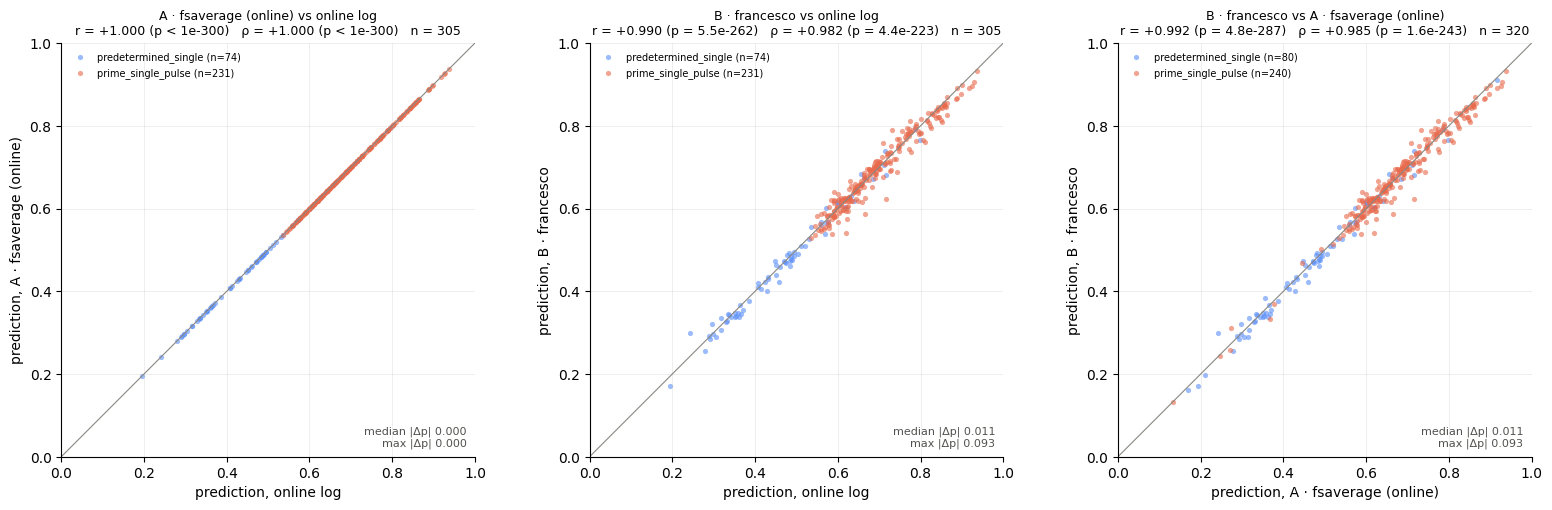

In [32]:
if RUN_MODEL:
    fig, axes = plt.subplots(1, 3, figsize=(16, 5))
    for ax, (a, b) in zip(axes, (("online", "A"), ("online", "B"), ("A", "B"))):
        d = PERF[a][["p", "condition"]].join(PERF[b][["p"]], rsuffix="_b", how="inner").dropna(subset=["p", "p_b"])
        out = corr_panel(ax, d.p.to_numpy(), d.p_b.to_numpy(), d.condition.to_numpy(),
                         f"{source_label(b)} vs {source_label(a)}", f"prediction, {source_label(a)}",
                         f"prediction, {source_label(b)}", identity=True)
        dp = (d.p_b - d.p).abs()
        if len(d):
            ax.text(0.98, 0.02, f"median |Δp| {dp.median():.3f}\nmax |Δp| {dp.max():.3f}", transform=ax.transAxes,
                    ha="right", va="bottom", fontsize=8, color=INK_2)
        CORR.append({"analysis": "prediction vs prediction", "x": a, "y": b, "condition": "all single pulses",
                     "trials": "both have a prediction", **out, "median |Δp|": dp.median()})
    fig.tight_layout()
    plt.show()
else:
    print("skipped (RUN_MODEL = False)")

### 8.2 Predictions vs raw TEP amplitude

Rows: `predetermined_single`, `prime_single_pulse` (forced trials included in the replays), and both pooled.
Columns: the three sources, each with its own predictions and its own raw amplitudes.

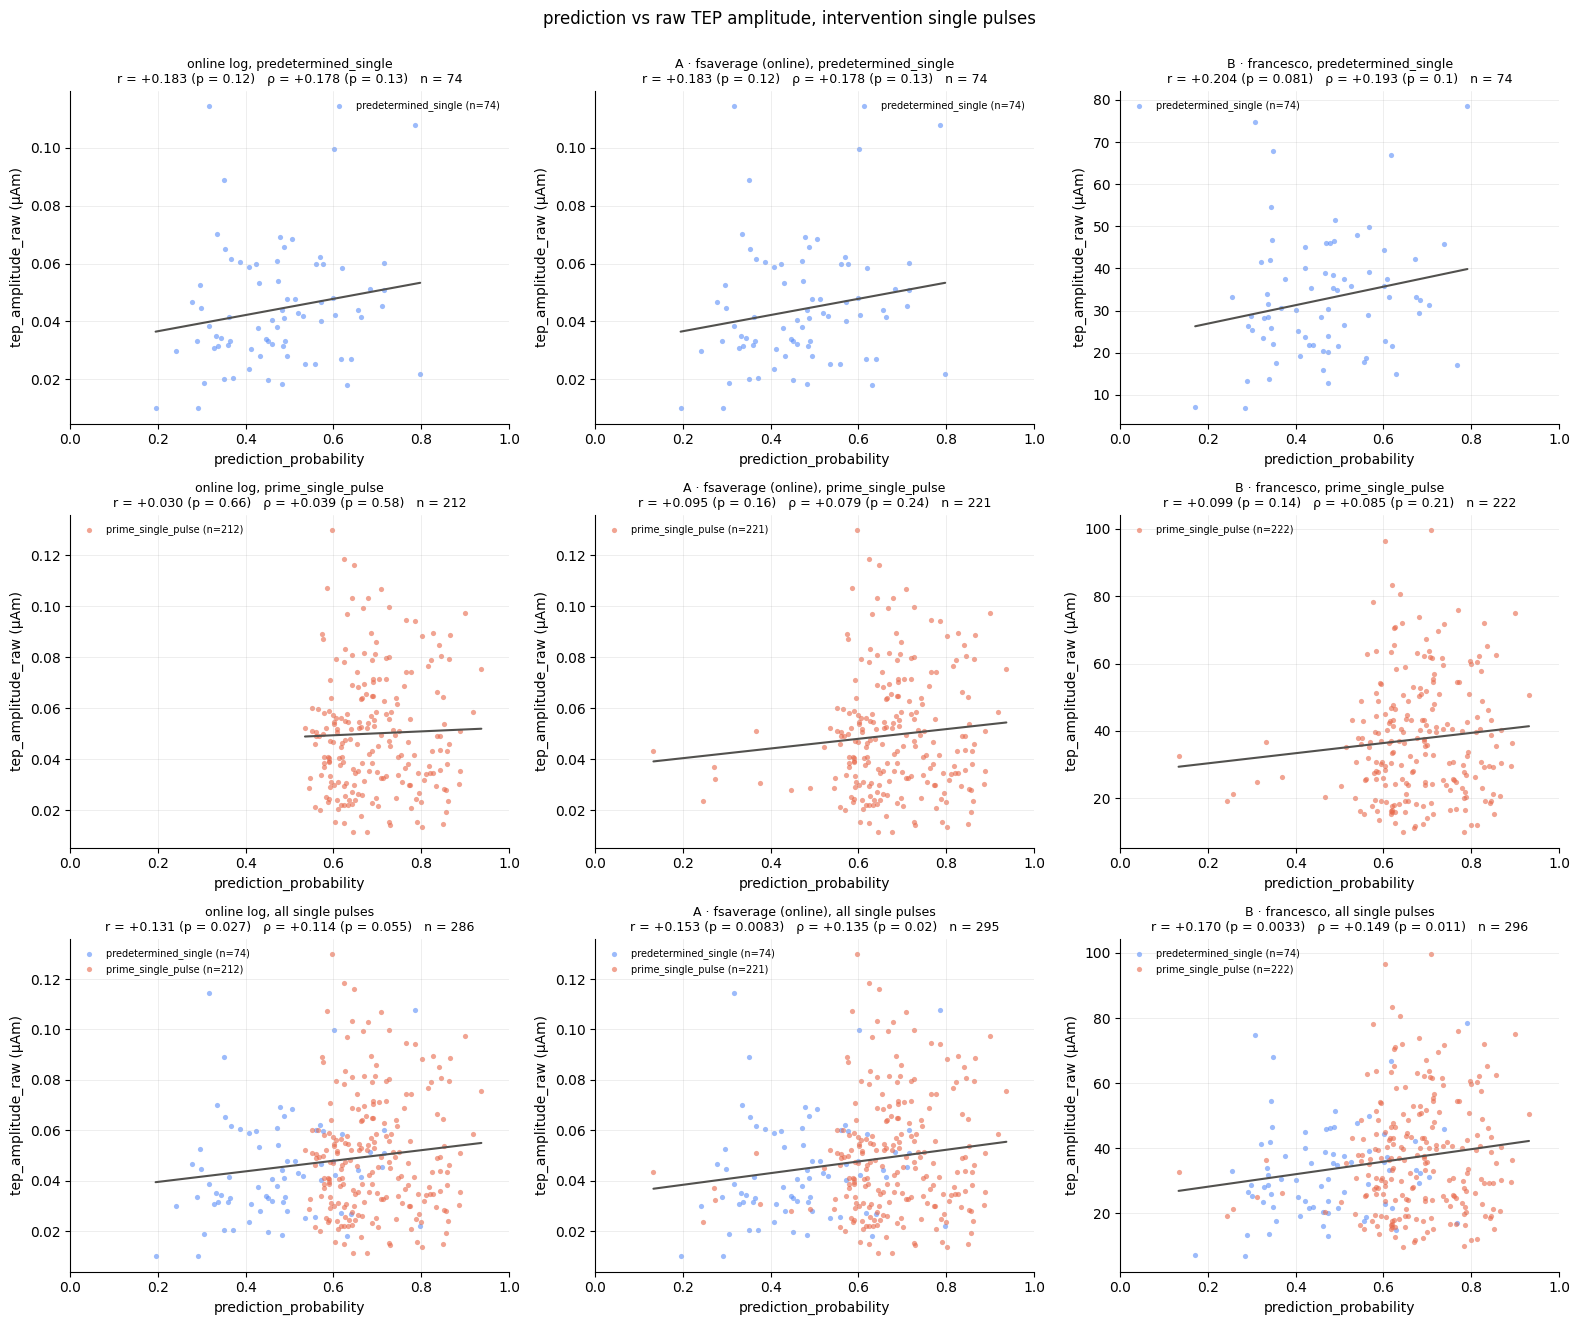

In [33]:
ROW_SETS = [("predetermined_single", ["predetermined_single"]), ("prime_single_pulse", ["prime_single_pulse"]),
            ("all single pulses", SINGLE_CONDITIONS)]


def prediction_grid(ycol, ylabel, title):
    fig, axes = plt.subplots(len(ROW_SETS), len(SOURCES), figsize=(5.3 * len(SOURCES), 4.4 * len(ROW_SETS)),
                             squeeze=False)
    for i, (row_name, conds) in enumerate(ROW_SETS):
        common = None
        for src in SOURCES:
            d = PERF[src][PERF[src].condition.isin(conds)].dropna(subset=["p", ycol])
            common = set(d.index) if common is None else common & set(d.index)
        for j, src in enumerate(SOURCES):
            d = PERF[src][PERF[src].condition.isin(conds)].dropna(subset=["p", ycol])
            out = corr_panel(axes[i, j], d.p.to_numpy(), d[ycol].to_numpy(), d.condition.to_numpy(),
                             f"{source_label(src)}, {row_name}", "prediction_probability", ylabel)
            dc = d.loc[sorted(common)]
            extra = ({"r (common)": stats.pearsonr(dc.p, dc[ycol])[0], "rho (common)": stats.spearmanr(dc.p, dc[ycol])[0],
                      "n (common)": len(dc)} if len(dc) >= 3 else {"n (common)": len(dc)})
            CORR.append({"analysis": f"prediction vs {ycol}", "x": "prediction", "y": f"{ycol} ({src})",
                         "source": src, "condition": row_name, "trials": "own", **out, **extra})
        if len(common) >= 5:
            pair = PERF["A"].loc[sorted(common), ["p", ycol]].join(PERF["B"].loc[sorted(common), ["p", ycol]],
                                                                  lsuffix="_A", rsuffix="_B")
            obs, lo, hi = paired_rho_diff(pair, ycol)
            CORR.append({"analysis": f"prediction vs {ycol}", "x": "prediction", "y": ycol, "source": "B - A",
                         "condition": row_name, "trials": "common", "n (common)": len(pair),
                         "rho_B - rho_A": obs, "95% CI low": lo, "95% CI high": hi})
    fig.suptitle(title, y=1.0)
    fig.tight_layout()
    plt.show()


if RUN_MODEL:
    prediction_grid("raw", "tep_amplitude_raw (µAm)", "prediction vs raw TEP amplitude, intervention single pulses")
else:
    print("skipped (RUN_MODEL = False)")

### 8.3 Predictions vs TEP label

The label each source's normaliser made of its amplitude (`tep_amplitude`: EWMA-detrended, z-scored against the
calibration, mapped through the calibration ECDF), which is what the model was finetuned on.

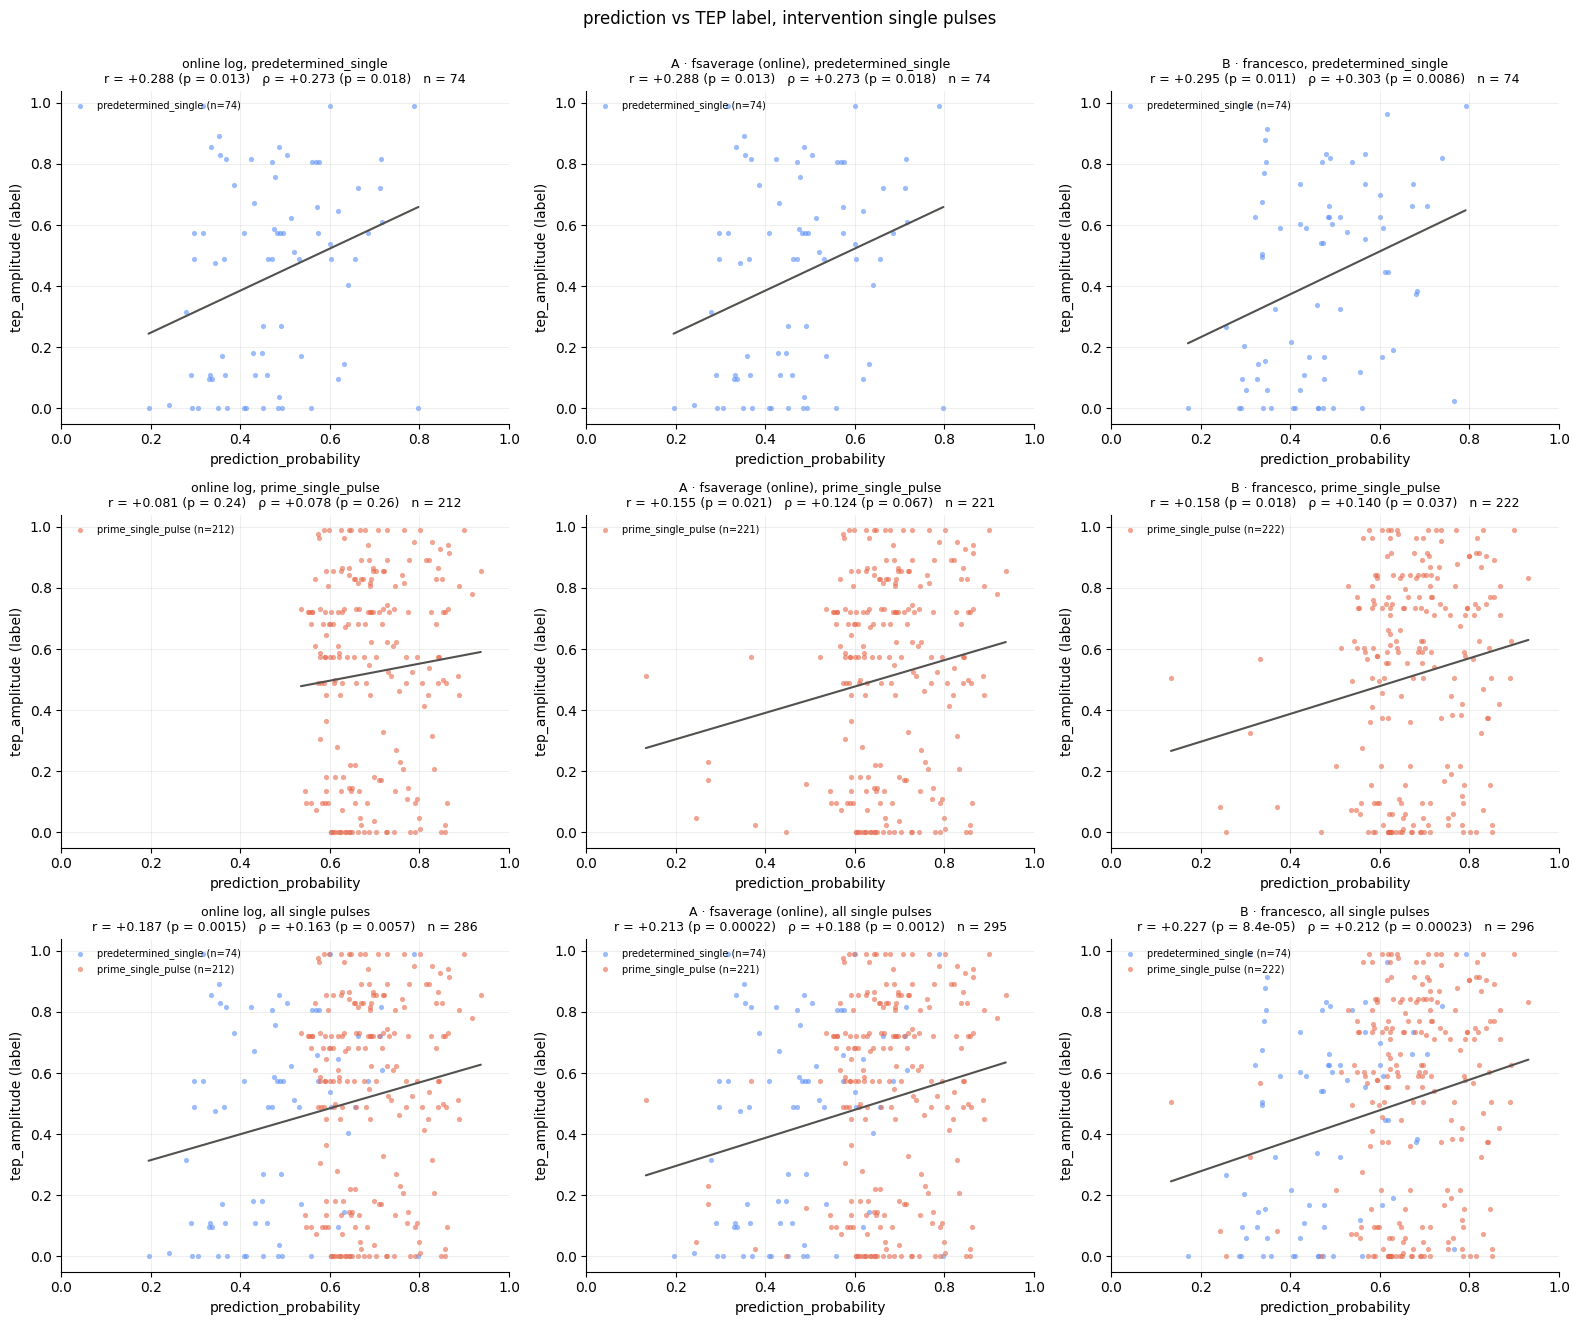

,analysis,condition,source,x,y,trials,n,r,p_r,rho,p_rho,median |Δp|,n (common),r (common),rho (common),rho_B - rho_A,95% CI low,95% CI high
0,prediction vs prediction,all single pulses,NaN,online,A,both have a prediction,305.0,1.0000,0.0000,1.0000,0.0000,0.0000,NaN,NaN,NaN,NaN,NaN,NaN
1,prediction vs prediction,all single pulses,NaN,online,B,both have a prediction,305.0,0.9903,0.0000,0.9825,0.0000,0.0108,NaN,NaN,NaN,NaN,NaN,NaN
2,prediction vs prediction,all single pulses,NaN,A,B,both have a prediction,320.0,0.9919,0.0000,0.9847,0.0000,0.0110,NaN,NaN,NaN,NaN,NaN,NaN
3,prediction vs raw,predetermined_single,online,prediction,raw (online),own,74.0,0.1825,0.1196,0.1783,0.1286,NaN,74.0,0.1825,0.1783,NaN,NaN,NaN
4,prediction vs raw,predetermined_single,A,prediction,raw (A),own,74.0,0.1825,0.1196,0.1783,0.1286,NaN,74.0,0.1825,0.1783,NaN,NaN,NaN
5,prediction vs raw,predetermined_single,B,prediction,raw (B),own,74.0,0.2044,0.0807,0.1925,0.1003,NaN,74.0,0.2044,0.1925,NaN,NaN,NaN
6,prediction vs raw,predetermined_single,B - A,prediction,raw,common,NaN,NaN,NaN,NaN,NaN,NaN,74.0,NaN,NaN,0.0142,-0.0608,0.0887
7,prediction vs raw,prime_single_pulse,online,prediction,raw (online),own,212.0,0.0302,0.6622,0.0387,0.5753,NaN,212.0,0.0302,0.0387,NaN,NaN,NaN
8,prediction vs raw,prime_single_pulse,A,prediction,raw (A),own,221.0,0.0949,0.1596,0.0792,0.2408,NaN,212.0,0.0302,0.0387,NaN,NaN,NaN
9,prediction vs raw,prime_single_pulse,B,prediction,raw (B),own,222.0,0.0988,0.1421,0.0853,0.2057,NaN,212.0,0.0299,0.0425,NaN,NaN,NaN


In [34]:
if RUN_MODEL:
    prediction_grid("label", "tep_amplitude (label)", "prediction vs TEP label, intervention single pulses")
    CORR_TABLE = pd.DataFrame(CORR)
    cols = ["analysis", "condition", "source", "x", "y", "trials", "n", "r", "p_r", "rho", "p_rho", "median |Δp|",
            "n (common)", "r (common)", "rho (common)", "rho_B - rho_A", "95% CI low", "95% CI high"]
    CORR_TABLE = CORR_TABLE.reindex(columns=[c for c in cols if c in CORR_TABLE])
    display(CORR_TABLE.round(4))
    CORR_TABLE.to_csv(RESULTS_ROOT / "prediction_correlations.csv", index=False)
else:
    print("skipped (RUN_MODEL = False)")

## Summary

The main numbers of sections 3–8 in one place. Tables are saved in `RESULTS_ROOT`: `forward_models.csv`,
`calibration_comparison.csv`, `stage_replay_trials.csv`, `dipole_window_candidates.csv`, `dipole_bootstrap.csv`,
`_summary.csv` and `dipole_B_vs_A_resampling.csv`, `open_loop_trials.csv`, `tep_amplitudes_by_block.csv` and
`_trials.csv`, `prediction_correlations.csv`, plus the ones written below; each arm's folder holds its calibration
files, block-end checkpoints and `trials_intervention.csv`.

In [35]:
print(f"{SUBJECT_ID} / {SESSION_ID} / {RUN_ID}, prime {EXPORT_MANIFEST['commit'][:10]}; forward B: {FWD['B']['file'].name} "
      f"({FWD['B']['src_desc']}, {FWD['B']['note']})")
print("\nCalibration")
for src in SOURCES:
    b, d = CAL_SRC[src]["bundle"], DIPOLES[src]
    print(f"  {source_label(src):{LABEL_W}s} kept {len(b['trials_kept']):3d} "
          f"(ocular {len(b['trials_dropped']['ocular'])}, pre MAD {len(b['trials_dropped']['qc'])}, "
          f"post MAD {len(b['trials_dropped']['post'])}); bad {', '.join(map(str, b['bad_channels'])) or '-'}; "
          f"SSP-SIR {n_sspsir(b)} components; dipole {d['window_ms'][0]:.0f}-{d['window_ms'][1]:.0f} ms, R² {d['r2']:.3f}")
print("  arm A " + ("reproduces the online calibration" if (REPRO.reproduced == "yes").all()
                   else "does not reproduce: " + ", ".join(REPRO.index[REPRO.reproduced == "NO"])))
display(DIPOLE_DIFF)
print("Dipole bootstrap")
display(BOOT_SUMMARY.loc[["same vertex as the full fit (%)", "distance to the full fit, median / 95th pct (mm)",
                          "full-sample fit: score margin over the runner-up (%)", "same window as the full fit (%)",
                          "rank of the full-sample window in the replays, median [range]",
                          "most frequent window (%)", "distinct windows"]])
display(SHIFT_VS_BOOT.to_frame())
print("Rejections of the intervention trials")
display(REJECTION_TABLE)
print("Processing time per pulse")
display(TIMING_TABLE.round(1))
print("TEP amplitude relative to the own baseline (medians)")
if "median / baseline median" in TEP_TABLE:
    display(TEP_TABLE["median / baseline median"].unstack("category")
            .reindex(index=[source_label(s) for s in SOURCES], columns=[c for c in CATEGORIES if c != "baseline"])
            .round(3))
if RUN_MODEL:
    print("Prediction vs TEP (own trials; common-trial and B - A columns in prediction_correlations.csv)")
    show = CORR_TABLE[CORR_TABLE.trials == "own"].pivot_table(index=["analysis", "condition"], columns="source",
                                                               values="rho", aggfunc="first")
    show = show.reindex(columns=[s for s in SOURCES if s in show.columns]).rename(columns=source_label)
    display(show.round(3))

SUMMARY_OUT = RESULTS_ROOT
REJECTION_TABLE.to_csv(SUMMARY_OUT / "rejections_by_reason.csv")
TIMING_TABLE.to_csv(SUMMARY_OUT / "processing_time_per_pulse.csv")
STEP_TABLE.to_csv(SUMMARY_OUT / "processing_time_per_step.csv")
DIPOLE_TABLE.to_csv(SUMMARY_OUT / "dipoles.csv")
DIPOLE_DIFF.to_csv(SUMMARY_OUT / "dipole_differences.csv")
REPRO.to_csv(SUMMARY_OUT / "arm_A_reproduction.csv")
SSP_TABLE.to_csv(SUMMARY_OUT / "sspsir_summary.csv")
pd.concat({"SOUND": SOUND_SUMMARY, "SSP-SIR": SSP_SUMMARY}, axis=1).to_csv(SUMMARY_OUT / "sound_sspsir_trials_summary.csv")
print(f"tables saved to {SUMMARY_OUT}")

pilot005 / ses-prime / 105, prime f4fd3954c4; forward B: pilot_0005_leadfield-fwd.fif (discrete 15684, as in the file)

Calibration
  online log             kept 107 (ocular 13, pre MAD 4, post MAD 1); bad C3, CP3, T8; SSP-SIR 15 components; dipole 39-42 ms, R² 0.607
  A · fsaverage (online) kept 107 (ocular 13, pre MAD 4, post MAD 1); bad C3, CP3, T8; SSP-SIR 15 components; dipole 39-42 ms, R² 0.607
  B · francesco          kept 108 (ocular 13, pre MAD 4, post MAD 0); bad C3, CP3, T8; SSP-SIR 15 components; dipole 38-42 ms, R² 0.634
  arm A reproduces the online calibration


,distance (mm),orientation angle (°),windows (ms),window start shift (ms),overlap (samples)
comparison,,,,,
A vs online,0.0,0.0,39-42 vs 39-42,0.0,4
B vs online,51.9,6.7,38-42 vs 39-42,-1.0,4
B vs A,51.9,6.7,38-42 vs 39-42,-1.0,4


Dipole bootstrap


,A · fsaverage (online),B · francesco
same vertex as the full fit (%),2,24
"distance to the full fit, median / 95th pct (mm)",12.9 / 21.6,4.6 / 19.2
full-sample fit: score margin over the runner-up (%),5.8,21.9
same window as the full fit (%),6,34
"rank of the full-sample window in the replays, median [range]","5 [1, 22]","2 [1, 11]"
most frequent window (%),38-43 ms (34),38-42 ms (34)
distinct windows,11,14


,arm B against arm A's resampling spread
B vs A: distance (mm),51.9
larger than this share of A's resampling distances (%),100.0
B vs A: orientation angle (°),6.7
larger than this share of A's resampling angles (%),19.5
B's window,38-42 ms
chosen in this share of A's replays (%),26.5


Rejections of the intervention trials


... (4 outputs left out)

category,PRIME single,predetermined single,t0,t15,t30,t60
source,,,,,,
online log,1.484,1.338,1.404,1.510,1.370,1.283
A · fsaverage (online),1.484,1.338,1.404,1.510,1.370,1.283
B · francesco,1.549,1.346,1.423,1.562,1.427,1.360


Prediction vs TEP (own trials; common-trial and B - A columns in prediction_correlations.csv)


source                                    online log  A · fsaverage (online)  B · francesco
analysis            condition                                                              
prediction vs label all single pulses          0.163                   0.188          0.212
                    predetermined_single       0.273                   0.273          0.303
                    prime_single_pulse         0.078                   0.124          0.140
prediction vs raw   all single pulses          0.114                   0.135          0.149
                    predetermined_single       0.178                   0.178          0.193
                    prime_single_pulse         0.039                   0.079          0.085

tables saved to D:\Linus\Loop\offline_fwdmodel\sub-pilot005
